# Silent failure detection of medical image classifiers under distribution shift

**Question.** Do *representation drift* (where an image's features lie relative to the training data) and *Grad-CAM explanation
drift* (whether the model "looks" at an image the way it usually does) detect **silent failures** - wrong predictions made with high
calibrated confidence - beyond calibrated predictive uncertainty? And do they lower the residual silent-failure rate when a fixed share
of cases can be sent to a human?

This notebook is the single final report. It **reads saved results only** (small CSV / JSON / PNG / Markdown files committed under
`outputs/` and `docs/`), performs no training, no GPU work and no feature extraction, and runs top-to-bottom from a fresh clone in a few
minutes. The heavy pipeline that produced these files is in `sfd/` and `scripts/` (see Section 14).

## Contents
0. [How to read this notebook, glossary, executive summary, main findings](#s0)
1. [Problem and definitions](#s1)
2. [Data, splits and shift families](#s2)
3. [Methods](#s3)
4. [Classifier performance and calibration (Table 1)](#s4)
5. [Behaviour under shift (Figure 2)](#s5)
6. [Sample-level detection (Figures 3-4, Table 2)](#s6)
7. [Batch (window) monitoring (Figure 5)](#s7)
8. [Referral policy under a review budget (Figure 6, Table 3)](#s8)
9. [Ablations and sensitivity (Figure 8)](#s9)
10. [EXPLORATORY, POST-HOC: targeted (confidence-gated) fusion](#s10)
10b. [Extensions (post-hoc): deep-ensemble baseline and in-family vs out-of-family](#sx)
11. [Shortcut case study (Figure 7)](#s11)
12. [Blueprint compliance checklist and deviations](#s12)
13. [Honest limitations](#s13)
14. [Reproducibility](#s14)
- [Appendix A: all remaining tables](#sA)
- [Appendix B: file index](#sB)

> **Known gaps (Blueprint items not done).** (1) a second classifier architecture; (2) MC-dropout uncertainty (a deep-ensemble baseline
> was added afterwards as a post-hoc extension, Section 10b); (3) Grad-CAM alternatives (Grad-CAM++, ScoreCAM, Integrated Gradients);
> (4) a within-family tuned in-family vs out-of-family comparison (only source-vs-shifted and in-sample evidence, Section 10b);
> (5) the artefact-patch (non-tissue) removal ablation in Camelyon. They are listed as DEVIATIONS in Section 12; no result in the
> main sections depends on them.

In [1]:
# ---------------------------------------------------------------- setup: imports, style, helpers (defined once) ----
import json, subprocess, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display, Markdown, Image, HTML

warnings.filterwarnings("ignore")
T_START = time.time()
ROOT = Path.cwd()
OUT = ROOT / "outputs"
assert OUT.exists(), "run the notebook from the repository root"

# Okabe-Ito colour-blind-safe palette, one fixed colour per method so every figure reads the same way
OI = {"black": "#000000", "orange": "#E69F00", "sky": "#56B4E9", "green": "#009E73", "yellow": "#F0E442",
      "blue": "#0072B2", "vermillion": "#D55E00", "purple": "#CC79A7", "grey": "#999999"}
COL = {"random": OI["grey"], "oracle": OI["black"], "M0": OI["blue"], "M1": OI["orange"], "M2": OI["green"],
       "sf_M1": OI["purple"], "sf_M2": OI["vermillion"], "G_M0": OI["sky"], "G_M1": "#882255", "G_sfM1": OI["purple"]}
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 120, "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
                     "legend.fontsize": 8, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.prop_cycle": plt.cycler(color=[OI[k] for k in ("blue", "orange", "green", "vermillion", "purple", "sky", "yellow", "black")])})
pd.set_option("display.max_rows", None, "display.max_columns", None, "display.width", 250, "display.max_colwidth", 120)

READ = []                                                   # every file read, for Appendix B


def rd(rel):
    # Load one committed result file (csv / json / parquet / md) and remember it for the file index.
    p = OUT / rel if not rel.startswith(("docs/", "configs/")) else ROOT / rel
    READ.append(str(p.relative_to(ROOT)).replace("\\", "/"))
    if p.suffix == ".csv":
        return pd.read_csv(p)
    if p.suffix == ".json":
        return json.loads(p.read_text(encoding="utf-8"))
    if p.suffix == ".parquet":
        return pd.read_parquet(p)
    return p.read_text(encoding="utf-8")


def ci(e, lo, hi, d=3, scale=1.0, signed=False):
    # 'estimate [low, high]' string; scale=100 turns rates into percent / percentage points.
    if pd.isna(e):
        return ""
    f = f"{{:{'+' if signed else ''}.{d}f}}"
    s = f.format(scale * e)
    return s if pd.isna(lo) else f"{s} [{f.format(scale * lo)}, {f.format(scale * hi)}]"


def fmt(df, est="estimate", lo="ci_low", hi="ci_high", d=3, scale=1.0, signed=False, keep=None, name="estimate [95% CI]"):
    # Table with one formatted 'estimate [95% CI]' column instead of three numeric ones.
    out = df.copy()
    out[name] = [ci(e, l, h, d, scale, signed) for e, l, h in zip(out[est], out[lo], out[hi])]
    cols = [c for c in (keep or [c for c in df.columns if c not in (est, lo, hi)]) if c in out.columns] + [name]
    return out[cols].reset_index(drop=True)


def show(df, title):
    # Display EVERY row of a table with a bold title.
    # rendered once as HTML (no duplicate plain-text copy) to keep the executed notebook small
    display(Markdown(f"**{title}** - {len(df)} rows"))
    display(HTML(df.reset_index(drop=True).to_html(index=False, na_rep="", border=0, max_rows=None, max_cols=None)))


def say(text):
    display(Markdown(text))


def figcap(n, text, notice):
    say(f"*Figure {n}. {text}*  \n**What to notice:** {notice}")


def png(rel, width=None):
    READ.append("outputs/" + rel)
    display(Image(filename=str(OUT / rel), width=width))


def one(df, **kw):
    # The single row matching every key=value (floats compared with a tolerance).
    m = pd.Series(True, index=df.index)
    for k, v in kw.items():
        m &= np.isclose(df[k].astype(float), v) if isinstance(v, float) else (df[k].astype(str) == str(v))
    r = df[m]
    assert len(r) == 1, (kw, len(r))
    return r.iloc[0]


def rc(r, d=3, scale=1.0, signed=True, est="estimate"):
    # Formatted 'estimate [CI]' of one table row.
    return ci(r[est], r["ci_low"], r["ci_high"], d, scale, signed)


print("setup ok; results folder:", OUT)

setup ok; results folder: D:\silent-failure\outputs


<a id="s0"></a>
## 0. How to read this notebook

* Every number in the text is **computed in the notebook from a saved table** and printed with its 95% confidence interval (CI).
  Rates are shown as proportions (0.123) or percent (12.3%); differences in residual rates are in **percentage points (pt)**.
* Every result is tagged with its evidential status:
  * **PRE-REGISTERED PRIMARY** - declared in a frozen plan committed (hash given) *before* any of its numbers were computed; no
    multiplicity adjustment.
  * **SECONDARY** - pre-registered secondary analyses or sensitivity analyses (Benjamini-Hochberg FDR within each declared family), and
    the outcome-informed but pre-committed amendment A1 of Phase 6.
  * **EXPLORATORY-POST-HOC** - motivated by earlier results; reported in clearly headed sections only, never in a main table, and never
    a replacement for the pre-registered detectors M0 / M1 / M2.
* Tables show **all rows** of the saved table they present (large tables are shown in full in Appendix A, with a filtered view in the
  main text that is labelled as such). Each table is followed by **What this shows**; each figure by a caption and **What to notice**.

### Glossary
| term | meaning |
|---|---|
| **Silent failure** | a wrong prediction whose *calibrated* confidence is high. Primary label `sf_090`: wrong AND confidence >= 0.90. |
| **MSP** | maximum softmax probability = the model's confidence; uncertainty = 1 - MSP. |
| **Temperature scaling** | dividing the logits by one scalar T fitted on source calibration data so that confidences match accuracies. |
| **ECE** | expected calibration error: average |accuracy - confidence| over confidence bins. |
| **AUROC** | probability that a random silent failure gets a higher monitor score than a random non-silent case (0.5 = chance). |
| **AUPRC** | area under the precision-recall curve (average precision); its chance level equals the prevalence. |
| **AURC** | area under the risk-coverage curve: accept cases from the lowest monitor score upwards and average the silent-failure rate among accepted cases (lower is better). |
| **FAR** | false-alarm rate of a batch monitor on windows that contain no shifted images (nominal 5%). |
| **CAM / Grad-CAM** | class activation map: a coarse heat map (8 x 8 at layer4) of image regions that drive the predicted class. |
| **JS divergence** | Jensen-Shannon divergence between two normalised maps (0 = identical). |
| **Mahalanobis / kNN** | distance of an image's 512-d penultimate features to the training-class Gaussians (Mahalanobis) or to its 10th nearest training neighbour (kNN). |
| **MMD** | maximum mean discrepancy: kernel two-sample statistic between a window's features and a training reference. |
| **M0 / M1 / M2** | nested detectors: M0 = uncertainty; M1 = M0 + Mahalanobis; M2 = M1 + CAM drift. |
| **Held-out-family rotation** | detector weights are fitted on two shift families and evaluated on the third one, so every result is *out-of-family*. |
| **Paired two-level cluster bootstrap** | resample the 5 classifier seeds, then clusters of near-identical images (PathMNIST) or patients (Camelyon); the same draw is used for every method, so differences are paired. 2,000 resamples. |
| **Pre-registered vs exploratory** | see the tags above. |

In [2]:
# ---------------------------------------------------------------- headline tables used throughout -----------------
t2 = rd("stage5/table2.csv")                                  # Phase 5 Table 2
t3 = rd("stage7/table3_referral.csv")                         # Phase 7 Table 3 (referral part)
t10_ = rd("stage10/e1_ensemble_baseline.csv")                  # Phase 10 extension E1
c6 = rd("stage6/contrasts.csv"); c6a = rd("stage6/a1/contrasts.csv")
far6 = rd("stage6/far_table.csv"); far6a = rd("stage6/a1/far_table.csv")
tt = rd("stage7/threshold_transfer.csv")
G = {g: rd(f"stage8/tables/ablation_{g}.csv") for g in ("G1", "G2", "G3", "G4", "G5", "G6", "G7", "G8", "G9")}
EX = rd("stage8/tables/exploratory_targeted.csv")
ftau = rd("stage4/frozen_tau.csv")

def t2r(H, q, m): return one(t2, heldout=H, quantity=q, metric=m)
def t3r(H, q, m, b): return one(t3, heldout=H, quantity=q, metric=m, budget=float(b))
def g8(H, q, b, m="dresid_sf", g="G2"):
    d = G[g]; return one(d[(d.kind == "contrast") & (d.level_col.isna())], heldout=H, quantity=q, metric=m, budget=float(b))
def ex(H, q, b, m="dresid_sf"):
    return one(EX, heldout=H, quantity=q, metric=m, budget=float(b))
def c6r(tab, H, a, b, kind="standard"):
    return one(tab[(tab["set"] == "primary") & (tab["size"] == 100) & (tab["mask"] == "silent_pooled")], H=H, kind=kind, a=a, b=b)
def rc6(r): return ci(r["diff"], r["ci_low"], r["ci_high"], 3, 1, True)

nfar_pre = int(far6[far6["size"] == 100].flag_outside_3_7pct.sum()); nfar_a1 = int(far6a[far6a["size"] == 100].flag_outside_3_7pct.sum())
ncell = int((far6["size"] == 100).sum())
n_tt = int(tt[tt.metric == "realised_workload"].workload_flag.astype(str).eq("True").sum()); N_tt = int((tt.metric == "realised_workload").sum())
n_degen = int(ftau.degenerate.notna().sum())
print("loaded")

loaded


In [3]:
# ---------------------------------------------------------------- executive summary (generated from the numbers) ---
say(f'''
### Executive summary (plain language)
We trained image classifiers (ResNet-18, 5 random seeds each) on two pathology datasets and then fed them images that differ from the
training data in three ways: **(A)** artificially corrupted images (blur, brightness, JPEG, ...), **(B)** tissue from two hospitals the
model never saw, and **(C)** images carrying a coloured marker that the model learned as a shortcut, which we then removed or reversed.
We asked whether three kinds of warning signals catch the dangerous errors - wrong answers given with at least 90% confidence:
the model's own uncertainty (**M0**), the distance of the image's internal features from the training data (**M1** adds this),
and a change in the model's attention map (**M2** adds this). Detectors were always tuned on two kinds of shift and tested on the third.

* Feature distance helps on corrupted images and new hospitals but **hurts on the shortcut**: AUROC gain M1-M0 =
  {rc(t2r("A","M1-M0","dAUROC"))} (A), {rc(t2r("B","M1-M0","dAUROC"))} (B), {rc(t2r("C","M1-M0","dAUROC"))} (C).
* The attention-map signal, used the pre-registered way (it may only *raise* the alarm), adds **nothing**: M2-M1 =
  {rc(t2r("A","M2-M1","dAUROC"),4)} (A), {rc(t2r("B","M2-M1","dAUROC"),4)} (B), {rc(t2r("C","M2-M1","dAUROC"),4)} (C).
* If a hospital can review a fixed share of cases, ranking by uncertainty sends the *unsure* cases first - but silent failures are by
  definition *sure*. At a 5% review budget the uncertainty ranking leaves **more** silent failures than random review
  ({rc(t3r("A","M0-random","dresid_sf",0.05),2,100)} pt on A). Adding feature distance helps only at a 20% budget
  (A {rc(t3r("A","M1-M0","dresid_sf",0.2),2,100)} pt, B {rc(t3r("B","M1-M0","dresid_sf",0.2),2,100)} pt) and hurts on the shortcut
  (C {rc(t3r("C","M1-M0","dresid_sf",0.2),2,100)} pt).
* Batch monitors calibrated on one source split raised far too many false alarms on another source split ({nfar_pre} of {ncell}
  cells outside the 3-7% tolerance); this pre-registered check **failed** and is reported openly with a pre-committed fix (A1).
* Ablation finding (pre-registered): if the attention-map signal is allowed a **negative** weight, it reduces residual silent failures on
  A ({rc(g8("A","sf_M2-sf_M1",0.10),2,100)} pt at 10%) and C ({rc(g8("C","sf_M2-sf_M1",0.10),2,100)} pt) - confident errors tend to look
  *typical*, not unusual.
* Exploratory only: ranking within the confident cases first (confidence >= 0.90) cuts residual silent failures strongly on A and B
  (gated M1 vs M1 at 20%: A {rc(ex("A","G_M1-M1",0.2),2,100)} pt, B {rc(ex("B","G_M1-M1",0.2),2,100)} pt).
''')


### Executive summary (plain language)
We trained image classifiers (ResNet-18, 5 random seeds each) on two pathology datasets and then fed them images that differ from the
training data in three ways: **(A)** artificially corrupted images (blur, brightness, JPEG, ...), **(B)** tissue from two hospitals the
model never saw, and **(C)** images carrying a coloured marker that the model learned as a shortcut, which we then removed or reversed.
We asked whether three kinds of warning signals catch the dangerous errors - wrong answers given with at least 90% confidence:
the model's own uncertainty (**M0**), the distance of the image's internal features from the training data (**M1** adds this),
and a change in the model's attention map (**M2** adds this). Detectors were always tuned on two kinds of shift and tested on the third.

* Feature distance helps on corrupted images and new hospitals but **hurts on the shortcut**: AUROC gain M1-M0 =
  +0.093 [+0.064, +0.127] (A), +0.038 [+0.015, +0.065] (B), -0.057 [-0.077, -0.033] (C).
* The attention-map signal, used the pre-registered way (it may only *raise* the alarm), adds **nothing**: M2-M1 =
  -0.0000 [-0.0000, -0.0000] (A), -0.0038 [-0.0114, +0.0002] (B), -0.0000 [-0.0000, +0.0000] (C).
* If a hospital can review a fixed share of cases, ranking by uncertainty sends the *unsure* cases first - but silent failures are by
  definition *sure*. At a 5% review budget the uncertainty ranking leaves **more** silent failures than random review
  (+0.57 [+0.49, +0.64] pt on A). Adding feature distance helps only at a 20% budget
  (A -4.32 [-5.15, -3.43] pt, B -1.43 [-2.47, -0.45] pt) and hurts on the shortcut
  (C +3.61 [+1.92, +5.27] pt).
* Batch monitors calibrated on one source split raised far too many false alarms on another source split (46 of 55
  cells outside the 3-7% tolerance); this pre-registered check **failed** and is reported openly with a pre-committed fix (A1).
* Ablation finding (pre-registered): if the attention-map signal is allowed a **negative** weight, it reduces residual silent failures on
  A (-2.05 [-2.46, -1.44] pt at 10%) and C (-5.14 [-6.60, -3.14] pt) - confident errors tend to look
  *typical*, not unusual.
* Exploratory only: ranking within the confident cases first (confidence >= 0.90) cuts residual silent failures strongly on A and B
  (gated M1 vs M1 at 20%: A -5.25 [-6.04, -4.25] pt, B -6.99 [-9.48, -4.40] pt).


In [4]:
# ---------------------------------------------------------------- main findings table ----------------------------
P5, P6, A1, P7, P8 = "e388dd6", "931fb36", "4ea78c3", "aa962a9", "f0553df"
rows = [
 ("Representation drift (M1) improves out-of-family detection AUROC over uncertainty on A and B", "PRE-REGISTERED PRIMARY", P5,
  f"A {rc(t2r('A','M1-M0','dAUROC'))}; B {rc(t2r('B','M1-M0','dAUROC'))}"),
 ("Representation drift hurts detection on the strong shortcut (C)", "PRE-REGISTERED PRIMARY", P5, f"C {rc(t2r('C','M1-M0','dAUROC'))}"),
 ("Explanation drift (non-negative M2) adds nothing over M1", "PRE-REGISTERED PRIMARY", P5,
  f"A {rc(t2r('A','M2-M1','dAUROC'),4)}; B {rc(t2r('B','M2-M1','dAUROC'),4)}; C {rc(t2r('C','M2-M1','dAUROC'),4)}"),
 ("Batch false-alarm check failed (val_cal thresholds do not transfer to id_test windows)", "PRE-REGISTERED PRIMARY", P6,
  f"{nfar_pre}/{ncell} cells outside 3-7% (after A1: {nfar_a1}/{ncell})"),
 ("At matched FAR, MMD beats mean uncertainty on silent windows only for new hospitals (B)", "SECONDARY (amendment A1)", A1,
  f"B {rc6(c6r(c6a,'B','r_mmd','u_mean'))}; A {rc6(c6r(c6a,'A','r_mmd','u_mean'))}"),
 ("Uncertainty-first referral leaves MORE silent failures than random at a 5% budget", "PRE-REGISTERED PRIMARY (reference contrast)", P7,
  f"M0-random: A {rc(t3r('A','M0-random','dresid_sf',0.05),2,100)} pt; B {rc(t3r('B','M0-random','dresid_sf',0.05),2,100)} pt"),
 ("M1 lowers residual silent failures only at a 20% budget (A, B) and raises them on C", "PRE-REGISTERED PRIMARY", P7,
  f"20%: A {rc(t3r('A','M1-M0','dresid_sf',0.2),2,100)}; B {rc(t3r('B','M1-M0','dresid_sf',0.2),2,100)}; C {rc(t3r('C','M1-M0','dresid_sf',0.2),2,100)} pt"),
 ("Blueprint-literal transferred thresholds miss the review budget", "SECONDARY", P7, f"{n_tt}/{N_tt} cells off by > 1 pt of workload"),
 ("Sign-free CAM drift (sf-M2) reduces residual silent failures on A and C", "PRE-REGISTERED PRIMARY (P2)", P8,
  f"10%: A {rc(g8('A','sf_M2-sf_M1',0.1),2,100)}; B {rc(g8('B','sf_M2-sf_M1',0.1),2,100)}; C {rc(g8('C','sf_M2-sf_M1',0.1),2,100)} pt"),
 ("Confidence-gated M1 ranking reduces residual silent failures vs plain M1", "EXPLORATORY-POST-HOC", P8,
  f"20%: A {rc(ex('A','G_M1-M1',0.2),2,100)}; B {rc(ex('B','G_M1-M1',0.2),2,100)}; C {rc(ex('C','G_M1-M1',0.2),2,100)} pt"),
 ("A leave-seed-out deep ensemble recovers most of M1's 20%-budget benefit over single-model uncertainty", "EXTENSION (post-hoc)", "6e6f05c",
  f"20%: E-fuse - M0 A {rc(one(t10_, kind='contrast', heldout='A', quantity='E_fuse-M0', metric='dresid_sf', budget=0.2),2,100)} pt; M1 - E-fuse A {rc(one(t10_, kind='contrast', heldout='A', quantity='M1-E_fuse', metric='dresid_sf', budget=0.2),2,100)} pt"),
]
MAIN = pd.DataFrame(rows, columns=["finding", "status", "plan commit", "key numbers (95% CI)"])
show(MAIN, "Main findings")
say("**What this shows:** the robust pre-registered results are mixed: representation drift helps for natural shifts but not for a "
    "dominant shortcut, explanation drift adds nothing as a monotone alarm, and uncertainty-first referral cannot reach silent "
    "failures at small budgets. Positive results for sign-free CAM drift (pre-registered ablation) and gating (exploratory) point to "
    "the mechanism: silent failures look *typical* to every monitor.")

**Main findings** - 11 rows

finding,status,plan commit,key numbers (95% CI)
Representation drift (M1) improves out-of-family detection AUROC over uncertainty on A and B,PRE-REGISTERED PRIMARY,e388dd6,"A +0.093 [+0.064, +0.127]; B +0.038 [+0.015, +0.065]"
Representation drift hurts detection on the strong shortcut (C),PRE-REGISTERED PRIMARY,e388dd6,"C -0.057 [-0.077, -0.033]"
Explanation drift (non-negative M2) adds nothing over M1,PRE-REGISTERED PRIMARY,e388dd6,"A -0.0000 [-0.0000, -0.0000]; B -0.0038 [-0.0114, +0.0002]; C -0.0000 [-0.0000, +0.0000]"
Batch false-alarm check failed (val_cal thresholds do not transfer to id_test windows),PRE-REGISTERED PRIMARY,931fb36,46/55 cells outside 3-7% (after A1: 23/55)
"At matched FAR, MMD beats mean uncertainty on silent windows only for new hospitals (B)",SECONDARY (amendment A1),4ea78c3,"B +0.306 [+0.191, +0.448]; A -0.428 [-0.493, -0.380]"
Uncertainty-first referral leaves MORE silent failures than random at a 5% budget,PRE-REGISTERED PRIMARY (reference contrast),aa962a9,"M0-random: A +0.57 [+0.49, +0.64] pt; B +0.64 [+0.42, +0.89] pt"
"M1 lowers residual silent failures only at a 20% budget (A, B) and raises them on C",PRE-REGISTERED PRIMARY,aa962a9,"20%: A -4.32 [-5.15, -3.43]; B -1.43 [-2.47, -0.45]; C +3.61 [+1.92, +5.27] pt"
Blueprint-literal transferred thresholds miss the review budget,SECONDARY,aa962a9,36/36 cells off by > 1 pt of workload
Sign-free CAM drift (sf-M2) reduces residual silent failures on A and C,PRE-REGISTERED PRIMARY (P2),f0553df,"10%: A -2.05 [-2.46, -1.44]; B +0.02 [-0.08, +0.13]; C -5.14 [-6.60, -3.14] pt"
Confidence-gated M1 ranking reduces residual silent failures vs plain M1,EXPLORATORY-POST-HOC,f0553df,"20%: A -5.25 [-6.04, -4.25]; B -6.99 [-9.48, -4.40]; C -1.72 [-2.32, -1.04] pt"


**What this shows:** the robust pre-registered results are mixed: representation drift helps for natural shifts but not for a dominant shortcut, explanation drift adds nothing as a monotone alarm, and uncertainty-first referral cannot reach silent failures at small budgets. Positive results for sign-free CAM drift (pre-registered ablation) and gating (exploratory) point to the mechanism: silent failures look *typical* to every monitor.

<a id="s1"></a>
## 1. Problem and definitions

A classifier is *deployed* on data that may differ from its training data. Most errors under shift come with low confidence and are
easy to flag. The dangerous errors are **silent**: the model is wrong but confident. Confidence here is always the **calibrated**
maximum softmax probability, $\hat p = \max_k \operatorname{softmax}(z/T)_k$, with temperature $T$ fitted on source calibration data.

**Labels.** For an image with true class $y$, prediction $\hat y$ and calibrated confidence $\hat p$:

* **`sf_090` (primary):** $\hat y \neq y$ and $\hat p \ge 0.90$.
* `sf_095` (sensitivity): $\hat y \neq y$ and $\hat p \ge 0.95$.
* `sf_tau` (Blueprint rule, sensitivity): $\hat y \neq y$ and $\hat p \ge \tau$, where $\tau$ is the smallest confidence threshold with
  $\ge 95\%$ precision (accuracy among accepted cases) on the source calibration split.
* `sf_099` (sensitivity): the same rule with a 99% precision target.

**Worked example (illustrative numbers, not data).** Five deployed images:

In [5]:
ex_cases = pd.DataFrame({"image": [1, 2, 3, 4, 5], "true": ["tumour", "normal", "tumour", "normal", "tumour"],
                         "predicted": ["tumour", "tumour", "normal", "tumour", "normal"], "calibrated confidence": [0.98, 0.97, 0.62, 0.91, 0.93]})
ex_cases["wrong"] = ex_cases.true != ex_cases.predicted
ex_cases["sf_090"] = ex_cases.wrong & (ex_cases["calibrated confidence"] >= 0.90)
ex_cases["sf_095"] = ex_cases.wrong & (ex_cases["calibrated confidence"] >= 0.95)
ex_cases["uncertainty 1-MSP"] = 1 - ex_cases["calibrated confidence"]
show(ex_cases, "Illustrative cases (made-up numbers)")
say("**What this shows:** images 2, 4 and 5 are silent failures under `sf_090` (only image 2 under `sf_095`); image 3 is a *visible* "
    "error (confidence 0.62). An uncertainty ranking (largest 1-MSP first) refers image 3 first - a visible error - and ranks the "
    "silent failures 2, 4, 5 below it: with a budget of one case, uncertainty-first referral removes no silent failure. This is the "
    "structural problem quantified in Section 8.")

show(fmt(ftau.assign(estimate=ftau.tau, ci_low=np.nan, ci_high=np.nan), d=4, name="tau",
         keep=["model", "dataset", "kind", "seed", "val_cal_acc", "val_cal_precision_at_tau", "accept_frac", "degenerate"]),
     "Frozen Blueprint threshold tau per classifier (outputs/stage4/frozen_tau.csv)")
say(f"**What this shows:** for {n_degen} of {len(ftau)} classifiers the source calibration accuracy is already >= 0.95, so the "
    "95%-precision rule accepts *every* calibration prediction and tau falls to the lowest observed confidence; `sf_tau` then labels "
    "almost **every error** a silent failure. That label no longer separates silent from visible errors, so the fixed threshold 0.90 "
    "(`sf_090`) was made primary before any detection result (plan `docs/analysis_plan_frozen.md`, commit e388dd6); `sf_tau` and "
    "`sf_099` remain sensitivities.")

**Illustrative cases (made-up numbers)** - 5 rows

image,true,predicted,calibrated confidence,wrong,sf_090,sf_095,uncertainty 1-MSP
1,tumour,tumour,0.98,False,False,False,0.02
2,normal,tumour,0.97,True,True,True,0.03
3,tumour,normal,0.62,True,False,False,0.38
4,normal,tumour,0.91,True,True,False,0.09
5,tumour,normal,0.93,True,True,False,0.07


**What this shows:** images 2, 4 and 5 are silent failures under `sf_090` (only image 2 under `sf_095`); image 3 is a *visible* error (confidence 0.62). An uncertainty ranking (largest 1-MSP first) refers image 3 first - a visible error - and ranks the silent failures 2, 4, 5 below it: with a budget of one case, uncertainty-first referral removes no silent failure. This is the structural problem quantified in Section 8.

**Frozen Blueprint threshold tau per classifier (outputs/stage4/frozen_tau.csv)** - 20 rows

model,dataset,kind,seed,val_cal_acc,val_cal_precision_at_tau,accept_frac,degenerate,tau
pathmnist_standard_seed0,pathmnist,standard,0,0.996199,0.996199,1.0000,accepts every val_cal prediction (val_cal precision 0.9962 >= 0.95),0.2750
camelyon17_standard_seed0,camelyon17,standard,0,0.957400,0.957400,1.0000,accepts every val_cal prediction (val_cal precision 0.9574 >= 0.95),0.5007
pathmnist_shortcut_seed0,pathmnist,shortcut,0,0.999400,0.999400,1.0000,accepts every val_cal prediction (val_cal precision 0.9994 >= 0.95),0.5655
pathmnist_shortcutv2_seed0,pathmnist,shortcutv2,0,1.000000,1.000000,1.0000,accepts every val_cal prediction (val_cal precision 1.0000 >= 0.95),1.0000
pathmnist_standard_seed1,pathmnist,standard,1,0.995799,0.995799,1.0000,accepts every val_cal prediction (val_cal precision 0.9958 >= 0.95),0.3375
camelyon17_standard_seed1,camelyon17,standard,1,0.939400,0.950072,0.9734,,0.5926
pathmnist_shortcut_seed1,pathmnist,shortcut,1,0.999400,0.999400,1.0000,accepts every val_cal prediction (val_cal precision 0.9994 >= 0.95),0.5688
pathmnist_shortcutv2_seed1,pathmnist,shortcutv2,1,1.000000,1.000000,1.0000,accepts every val_cal prediction (val_cal precision 1.0000 >= 0.95),1.0000
pathmnist_standard_seed2,pathmnist,standard,2,0.995799,0.995799,1.0000,accepts every val_cal prediction (val_cal precision 0.9958 >= 0.95),0.3123
camelyon17_standard_seed2,camelyon17,standard,2,0.966200,0.966200,1.0000,accepts every val_cal prediction (val_cal precision 0.9662 >= 0.95),0.5031


**What this shows:** for 19 of 20 classifiers the source calibration accuracy is already >= 0.95, so the 95%-precision rule accepts *every* calibration prediction and tau falls to the lowest observed confidence; `sf_tau` then labels almost **every error** a silent failure. That label no longer separates silent from visible errors, so the fixed threshold 0.90 (`sf_090`) was made primary before any detection result (plan `docs/analysis_plan_frozen.md`, commit e388dd6); `sf_tau` and `sf_099` remain sensitivities.

<a id="s2"></a>
## 2. Data, splits and shift families

* **PathMNIST** (MedMNIST v2, 128 x 128 px, 9 colorectal tissue classes; NCT-CRC-HE-100K). The official train + val images form one
  pool split into `train` / `val_es` (early stopping) / `val_cal` (calibration and monitoring references) / `id_test` with a
  **near-duplicate-cluster split** (clusters of near-identical images never cross splits). The official test set (CRC-VAL-HE-7K, a
  different clinical centre) is the supplement family **X** (`nct7k_test`).
* **Camelyon17-WILDS v1.0** (96 x 96 px lymph-node patches, tumour vs normal; 5 hospitals). Source hospitals 0, 3, 4; held-out
  hospitals 1 (`ood_c1`) and 2 (`ood_c2`) form family **B**. Splits are **patient-disjoint** (Phase 1b "Rank 1" assignment). Data were
  read from the unofficial Hugging Face mirror `wltjr1007/Camelyon17-WILDS` (counts verified against WILDS v1.0).
* **Family A** - MedMNIST-C v0.1.0: 11 corruptions x severities 1-5 applied at 224 px and resized to 128 px, plus the clean images =
  **56 conditions** on one fixed 3,000-image `id_test` sample.
* **Family C** - synthetic shortcut: a class-coded coloured cue in the image corner is present in training; at test it is `aligned`,
  `removed` or `reversed`. **v2** (cue on 100% of training images, 16 px; primary) and **v1** (95%; supplement), 5 seeds each.

In [6]:
tab1 = rd("stage1/table1.csv")
show(tab1, "Table S1 - datasets, splits, roles, sizes, licences (outputs/stage1/table1.csv)")
say(f"**What this shows:** PathMNIST train has {int(one(tab1, dataset='pathmnist', split='train').n):,} images; Camelyon train "
    f"{int(one(tab1, dataset='camelyon17', split='train').n):,} patches from only "
    f"{int(one(tab1, dataset='camelyon17', split='train').n_groups)} patients; each held-out hospital contributes 8,000 patches.")

sp = rd("stage1/splits.parquet")
cam = sp[sp.dataset == "camelyon17"]
per_h = cam.groupby(["split", "hospital"]).agg(patches=("uid", "size"), patients=("patient", "nunique"),
                                               tumour_share=("label", "mean")).reset_index()
per_h["tumour_share"] = per_h.tumour_share.round(3)
show(per_h, "Camelyon17 patches, patients and tumour share per split and hospital (from outputs/stage1/splits.parquet)")
tr = cam[cam.split == "train"].label.mean(); src = cam[cam.split.isin(["val_es", "val_cal", "id_test"])].label.mean()
ood = cam[cam.split.isin(["ood_c1", "ood_c2"])].label.mean()
say(f"**What this shows:** the patient-level split leaves a **tumour-prior gap**: train is balanced ({tr:.1%} tumour) while the "
    f"other source splits ({src:.1%}) were matched to the held-out hospitals ({ood:.1%}). Cells are uneven (e.g. hospital 3 has a "
    f"single id_test patient). These are limitations of 10 / 4 / 6 / 6 source patients per split (Section 13).")

pm = sp[sp.dataset == "pathmnist"].groupby("split").agg(images=("uid", "size"), clusters=("group", "nunique")).reset_index()
show(pm, "PathMNIST images and near-duplicate clusters per split (from outputs/stage1/splits.parquet)")
say("**What this shows:** every PathMNIST split contains several thousand independent clusters; clusters are the resampling unit of "
    "the bootstrap because PathMNIST has no patient identifiers.")

b1 = rd("stage1b/best_candidate_detail.csv")
show(b1, "Phase 1b selected patient assignment (Rank 1) per split and hospital (outputs/stage1b/best_candidate_detail.csv)")
say("**What this shows:** each source split is drawn from all three source hospitals with at least 10% of its patches per hospital, "
    "but from only 1-5 patients per hospital.")

**Table S1 - datasets, splits, roles, sizes, licences (outputs/stage1/table1.csv)** - 11 rows

dataset,split,domain,family,role,n,n_groups,class_counts,hospital_counts,flagged_nontissue,access_licence
pathmnist,train,"NCT-CRC-HE-100K (Macenko-normalised H&E, colorectal)",source / in-distribution,fit classifier,79755,75006,"{""adipose"": 8326, ""background"": 8210, ""debris"": 9209, ""lymphocytes"": 9245, ""mucus"": 7116, ""smooth_muscle"": 10828, ""normal_mucosa"": 7011, ""stroma"": 8357, ""tumor_epithelium"": 11453}",{},0,"MedMNIST v2 (CC BY 4.0), 128x128; underlying data NCT-CRC-HE (CC BY 4.0)"
pathmnist,id_test,"NCT-CRC-HE-100K (Macenko-normalised H&E, colorectal)",source / in-distribution,in-distribution test,10247,8885,"{""adipose"": 1041, ""background"": 1302, ""debris"": 1151, ""lymphocytes"": 1156, ""mucus"": 890, ""smooth_muscle"": 1354, ""normal_mucosa"": 876, ""stroma"": 1045, ""tumor_epithelium"": 1432}",{},0,"MedMNIST v2 (CC BY 4.0), 128x128; underlying data NCT-CRC-HE (CC BY 4.0)"
pathmnist,val_cal,"NCT-CRC-HE-100K (Macenko-normalised H&E, colorectal)",source / in-distribution,"temperature scaling, acceptance threshold, monitoring references",4999,4556,"{""adipose"": 520, ""background"": 527, ""debris"": 576, ""lymphocytes"": 578, ""mucus"": 445, ""smooth_muscle"": 677, ""normal_mucosa"": 438, ""stroma"": 522, ""tumor_epithelium"": 716}",{},0,"MedMNIST v2 (CC BY 4.0), 128x128; underlying data NCT-CRC-HE (CC BY 4.0)"
pathmnist,val_es,"NCT-CRC-HE-100K (Macenko-normalised H&E, colorectal)",source / in-distribution,early stopping,4999,4426,"{""adipose"": 520, ""background"": 527, ""debris"": 576, ""lymphocytes"": 578, ""mucus"": 445, ""smooth_muscle"": 677, ""normal_mucosa"": 438, ""stroma"": 522, ""tumor_epithelium"": 716}",{},0,"MedMNIST v2 (CC BY 4.0), 128x128; underlying data NCT-CRC-HE (CC BY 4.0)"
pathmnist,nct7k_test,CRC-VAL-HE-7K (different clinical centre),X (supplement: real centre shift),shifted evaluation only,7180,6570,"{""adipose"": 1338, ""background"": 847, ""debris"": 339, ""lymphocytes"": 634, ""mucus"": 1035, ""smooth_muscle"": 592, ""normal_mucosa"": 741, ""stroma"": 421, ""tumor_epithelium"": 1233}",{},0,"MedMNIST v2 (CC BY 4.0), 128x128; underlying data NCT-CRC-HE (CC BY 4.0)"
camelyon17,train,"source hospitals [0, 3, 4]",source / in-distribution,fit classifier,40000,10,"{""non_tumor"": 20000, ""tumor"": 20000}","{""0"": 1878, ""3"": 18902, ""4"": 19220}",516,"Camelyon17-WILDS v1.0 (CC0), 96x96; via unofficial HF mirror wltjr1007/Camelyon17-WILDS"
camelyon17,id_test,"source hospitals [0, 3, 4]",source / in-distribution,in-distribution test,5000,6,"{""non_tumor"": 2881, ""tumor"": 2119}","{""0"": 1339, ""3"": 793, ""4"": 2868}",47,"Camelyon17-WILDS v1.0 (CC0), 96x96; via unofficial HF mirror wltjr1007/Camelyon17-WILDS"
camelyon17,val_cal,"source hospitals [0, 3, 4]",source / in-distribution,"temperature scaling, acceptance threshold, monitoring references",5000,6,"{""non_tumor"": 2884, ""tumor"": 2116}","{""0"": 1431, ""3"": 2754, ""4"": 815}",83,"Camelyon17-WILDS v1.0 (CC0), 96x96; via unofficial HF mirror wltjr1007/Camelyon17-WILDS"
camelyon17,val_es,"source hospitals [0, 3, 4]",source / in-distribution,early stopping,3000,4,"{""non_tumor"": 1729, ""tumor"": 1271}","{""0"": 1569, ""3"": 444, ""4"": 987}",57,"Camelyon17-WILDS v1.0 (CC0), 96x96; via unofficial HF mirror wltjr1007/Camelyon17-WILDS"
camelyon17,ood_c1,held-out hospital 1,B (held-out hospital),shifted evaluation only,8000,8,"{""non_tumor"": 4622, ""tumor"": 3378}","{""1"": 8000}",54,"Camelyon17-WILDS v1.0 (CC0), 96x96; via unofficial HF mirror wltjr1007/Camelyon17-WILDS"


**What this shows:** PathMNIST train has 79,755 images; Camelyon train 40,000 patches from only 10 patients; each held-out hospital contributes 8,000 patches.

**Camelyon17 patches, patients and tumour share per split and hospital (from outputs/stage1/splits.parquet)** - 14 rows

split,hospital,patches,patients,tumour_share
id_test,0,1339,2,0.500
id_test,3,793,1,0.019
id_test,4,2868,3,0.500
ood_c1,1,8000,8,0.422
ood_c2,2,8000,9,0.425
train,0,1878,2,0.500
train,3,18902,5,0.500
train,4,19220,3,0.500
val_cal,0,1431,2,0.500
val_cal,3,2754,3,0.500


...

split,images,clusters
id_test,10247,8885
nct7k_test,7180,6570
train,79755,75006
val_cal,4999,4556
val_es,4999,4426


**What this shows:** every PathMNIST split contains several thousand independent clusters; clusters are the resampling unit of the bootstrap because PathMNIST has no patient identifiers.

**Phase 1b selected patient assignment (Rank 1) per split and hospital (outputs/stage1b/best_candidate_detail.csv)** - 12 rows

split,hospital,patients,slides,patches,tumour
id_test,0,2,2,1339,0.500
id_test,3,1,1,793,0.019
id_test,4,3,3,2868,0.500
train,0,2,2,1878,0.500
train,3,5,5,18902,0.500
train,4,3,4,19220,0.500
val_cal,0,2,3,1431,0.500
val_cal,3,3,3,2754,0.500
val_cal,4,1,1,815,0.029
val_es,0,1,3,1569,0.500


**What this shows:** each source split is drawn from all three source hospitals with at least 10% of its patches per hospital, but from only 1-5 patients per hospital.

**Near-duplicate audit (outputs/stage1/dedup_report.csv)** - 18 rows

dataset,scope,rms_threshold,n_pairs,n_clusters,n_dup_clusters,n_images_in_dup_clusters,max_cluster_size,pairs_saturated,n_label_mixed_clusters,n_images_with_neighbor,n_images
pathmnist,pool_self_join,0.000,0,100000.0,0.0,0.0,1.0,False,,,
pathmnist,pool_self_join,0.005,195609,98547.0,18.0,1471.0,611.0,False,0.0,,
pathmnist,pool_self_join,0.010,840891,96437.0,43.0,3606.0,1067.0,False,1.0,,
pathmnist,pool_self_join,0.020,2690968,92873.0,43.0,7170.0,4750.0,False,1.0,,
pathmnist,pool_self_join,0.030,5973179,90134.0,24.0,9890.0,5628.0,False,3.0,,
pathmnist,pool_self_join,0.050,13890805,79546.0,33.0,20487.0,20278.0,False,2.0,,
pathmnist,nct7k_test_to_pool,0.000,0,,,,,False,,0.0,7180.0
pathmnist,nct7k_test_to_pool,0.005,0,,,,,False,,0.0,7180.0
pathmnist,nct7k_test_to_pool,0.010,0,,,,,False,,0.0,7180.0
pathmnist,nct7k_test_to_pool,0.020,53926,,,,,False,,364.0,7180.0


**Automated leakage checks (outputs/stage1/leakage_audit.json)** - 15 rows

check,passed,value
uid unique (all datasets),True,
pathmnist: no near-duplicate cluster crosses splits,True,
pathmnist: split fractions within tolerance,True,"{'train': 0.79755, 'val_es': 0.04999, 'val_cal': 0.04999, 'id_test': 0.10247}"
pathmnist: every split has all 9 classes,True,
pathmnist: 0 near-duplicate pairs across pool splits,True,0
pathmnist: 0 near-duplicate pairs between nct7k_test and the pool (after exclusion),True,0
camelyon: no patient (grouping unit) crosses splits,True,
camelyon: no patient crosses splits,True,
camelyon: no slide crosses splits,True,
camelyon: source splits use source hospitals only,True,True


**What this shows:** 15 of 15 leakage checks pass (no uid, near-duplicate cluster, patient or slide crosses splits; held-out hospitals never appear in source splits).

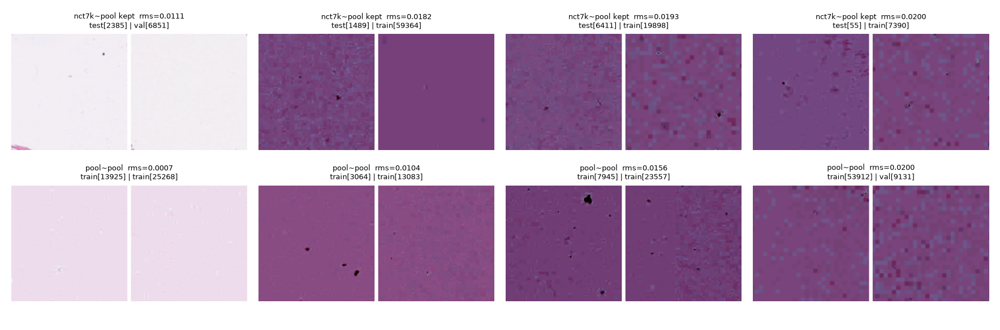

*Figure S1. Example near-duplicate pairs found by the audit (PathMNIST).*  
**What to notice:** near-identical tiles exist inside the official pool; the cluster split keeps each cluster in one split.

In [7]:
ded = rd("stage1/dedup_report.csv")
show(ded, "Near-duplicate audit (outputs/stage1/dedup_report.csv)")
la = rd("stage1/leakage_audit.json")
chk = pd.DataFrame(la["checks"]); chk["value"] = chk["value"].astype(str).str.slice(0, 100)
show(chk, "Automated leakage checks (outputs/stage1/leakage_audit.json)")
say(f"**What this shows:** {int(chk.passed.sum())} of {len(chk)} leakage checks pass (no uid, near-duplicate cluster, patient or slide "
    f"crosses splits; held-out hospitals never appear in source splits).")
png("stage1/near_duplicate_pairs.png", width=700)
figcap("S1", "Example near-duplicate pairs found by the audit (PathMNIST).", "near-identical tiles exist inside the official pool; the cluster split keeps each cluster in one split.")

**All evaluation conditions with per-condition behaviour (outputs/stage3/condition_summary.csv)** - 67 rows

family,condition,severity,model_kind,dataset,n_seeds,n,acc_std,conf_mean,ece_mean,sf_rate_mean,sf_rate_std,sf_among_errors_mean,accuracy (mean over seeds)
A,brightness_down,1,standard,pathmnist,5,3000,0.0305,0.9262,0.0905,0.0739,0.0111,0.4563,0.8369
A,brightness_down,2,standard,pathmnist,5,3000,0.0535,0.8893,0.1784,0.1345,0.0322,0.4642,0.7117
A,brightness_down,3,standard,pathmnist,5,3000,0.0659,0.8654,0.2863,0.2005,0.0606,0.4700,0.5791
A,brightness_down,4,standard,pathmnist,5,3000,0.0688,0.8519,0.3530,0.2385,0.0694,0.4699,0.4999
A,brightness_down,5,standard,pathmnist,5,3000,0.0630,0.8416,0.3825,0.2516,0.0720,0.4585,0.4592
A,brightness_up,1,standard,pathmnist,5,3000,0.0309,0.9334,0.1811,0.1130,0.0590,0.4492,0.7531
A,brightness_up,2,standard,pathmnist,5,3000,0.0651,0.8935,0.3176,0.2100,0.0867,0.4815,0.5763
A,brightness_up,3,standard,pathmnist,5,3000,0.0709,0.8767,0.4536,0.2965,0.1106,0.5020,0.4232
A,brightness_up,4,standard,pathmnist,5,3000,0.0701,0.8776,0.4918,0.3242,0.1104,0.5179,0.3861
A,brightness_up,5,standard,pathmnist,5,3000,0.0654,0.8790,0.5378,0.3619,0.1104,0.5412,0.3414


**What this shows:** 56 family-A rows (11 corruptions x 5 severities + clean), the Camelyon id_test and two held-out hospitals, three cue states for each shortcut model and the X supplement. These are the units over which the evaluation pools of Sections 6-10 are built.

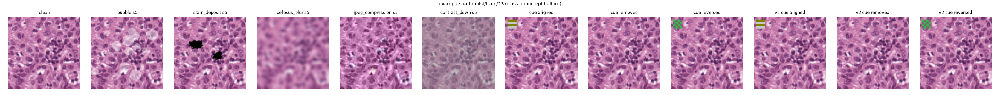

*Figure S2. Example images per shift family (corruptions at increasing severity, held-out hospitals, shortcut cue states).*  
**What to notice:** family A corruptions range from subtle (bubble, pixelate) to severe (brightness, contrast); the shortcut cue is a small corner patch.

In [8]:
cs = rd("stage3/condition_summary.csv")
show(fmt(cs.assign(estimate=cs.acc_mean, ci_low=np.nan, ci_high=np.nan), d=4, name="accuracy (mean over seeds)",
         keep=["family", "condition", "severity", "model_kind", "dataset", "n_seeds", "n", "acc_std", "conf_mean", "ece_mean", "sf_rate_mean", "sf_rate_std", "sf_among_errors_mean"]),
     "All evaluation conditions with per-condition behaviour (outputs/stage3/condition_summary.csv)")
say(f"**What this shows:** {int((cs.family == 'A').sum())} family-A rows (11 corruptions x 5 severities + clean), the Camelyon "
    "id_test and two held-out hospitals, three cue states for each shortcut model and the X supplement. These are the units over which "
    "the evaluation pools of Sections 6-10 are built.")
png("stage3/figures/examples.png", width=850)
figcap("S2", "Example images per shift family (corruptions at increasing severity, held-out hospitals, shortcut cue states).",
       "family A corruptions range from subtle (bubble, pixelate) to severe (brightness, contrast); the shortcut cue is a small corner patch.")

<a id="s3"></a>
## 3. Methods

**Classifier.** ResNet-18 initialised from ImageNet (torchvision `IMAGENET1K_V1`), SGD (lr 0.01, cosine, weight decay 5e-4), at most
8 epochs with early stopping on source `val_es` loss (patience 2), batch 128, mixed precision; augmentation = random flips and 90-degree
rotations only (no colour or blur augmentation, which would pre-train robustness to family A). 5 seeds per model kind (PathMNIST
standard, Camelyon standard, shortcut v1, shortcut v2) = 20 frozen classifiers.

**Temperature scaling** on `val_cal`: $T^\* = \arg\min_T \sum_i -\log \operatorname{softmax}(z_i/T)_{y_i}$.
**ECE** $= \sum_b \frac{|B_b|}{n} \lvert \operatorname{acc}(B_b) - \operatorname{conf}(B_b) \rvert$ over 15 equal-width confidence bins.

**Per-image signals** (higher = more suspicious):
* **M0 - uncertainty:** $u_1 = \log(1-\hat p)$ and $u_2 = \log H(\hat{\mathbf p})$, computed stably in log space from $z/T$ (identical
  ranking to $1-\hat p$ and entropy, but without float ties for saturated confidences). Energy is a descriptive extra.
* **M1 - representation:** Mahalanobis distance to the predicted class,
  $d_M(x) = \sqrt{(f(x)-\mu_{\hat y})^\top \Sigma^{-1} (f(x)-\mu_{\hat y})}$ with class means $\mu_c$ and one shared Ledoit-Wolf
  covariance $\Sigma$ fitted on penultimate features $f$ of **source training images only**, after the classifier was frozen
  (20,000 PathMNIST / 40,000 Camelyon reference images; frozen with checksums before any shifted file was read). kNN distance
  (10th neighbour, L2-normalised features) is a sensitivity.
* **M2 - explanation:** Grad-CAM at layer4 (8 x 8), normalised to unit mass; drift = Jensen-Shannon divergence to the predicted
  class's mean training CAM, divided by its typical variability under benign transforms (flips, rotations, +-10% brightness):
  $e(x) = \mathrm{JS}(\mathrm{CAM}(x), \overline{\mathrm{CAM}}_{\hat y}) / \mathrm{median\ transform\ JS}$. Layer3, layer2 (16 x 16),
  raw JS and a PCA-embedding distance are sensitivities.

**Standardisation.** Each signal is mapped to its percentile among the source `val_cal` values of the same classifier, with smooth
monotone tails outside the observed range (no shifted data are used).

**Fusion.** Logistic regression on the standardised signals, $s(x) = b_0 + \sum_j w_j\,x_j$, with **non-negative weights** $w_j \ge 0$
(the pre-registered monotone alarm), L2 penalty $10^{-3}$, equal weight for the two tuning families. The **sign-free** variant (Phase 8)
removes $w_j \ge 0$. **Held-out-family rotation:** weights are fitted per seed on two of A / B / C (label `sf_090`) and applied to the
third; X uses weights fitted on A + B + C.

**Sample-level endpoints.** AUROC, AUPRC and AURC $=\frac{1}{n}\sum_{k=1}^{n} \mathrm{risk}(k)$, where risk(k) is the silent-failure
rate among the $k$ accepted cases with the lowest score.

**Inference.** Paired two-level cluster bootstrap (B = 2,000, seed 0): resample the 5 classifier seeds with replacement, then clusters
(PathMNIST near-duplicate clusters; Camelyon patients) with replacement; the same draw is used for all methods. 95% percentile CIs;
$p = 2\min(P(d\le0), P(d\ge0))$; leave-one-seed-out jackknife. No adjustment for declared primaries; BH-FDR inside secondary families.

**Batch (window) monitoring.** Windows of $n=100$ images (sensitivities 50, 200) with a shifted fraction
$f \in \{0, 0.1, 0.25, 0.5, 0.75, 1\}$. Statistics: mean and 90th percentile of $\log(1-\hat p)$, the KS distance to source
uncertainties, unbiased RBF-kernel $\mathrm{MMD}^2$ between window features and a 2,000-image training reference, and the JS divergence
between the window's mean CAM and the class-mixture of training mean CAMs; plus a non-negative fused **combined monitor**. Alarm
threshold = 95th percentile over 3,000 source-only `val_cal` windows (5% nominal FAR); the **actual FAR** is measured on 2,000 held-out
`id_test` windows. A window is **silently failed** when its error rate exceeds the 95th percentile of source windows while its mean
confidence stays inside the source 2.5-97.5% range. **Detection delay** = number of post-onset windows until the first alarm,
right-censored at 30 (Kaplan-Meier median with censored share).

**Referral policy.** Exact budget $B \in \{5, 10, 20\}\%$: the top $B$ share of the held-out pool by score leaves automatic acceptance
(top $B/2$ = *refer*, next $B/2$ = *review*); ties at the boundary are split fractionally so workload is exactly $B$. Endpoint =
residual silent-failure rate among accepted cases; references: random referral (residual = prevalence) and an oracle (silent failures
first). Secondary, Blueprint-literal protocol: score thresholds tuned on the two tuning families and transferred, with the realised
workload reported.

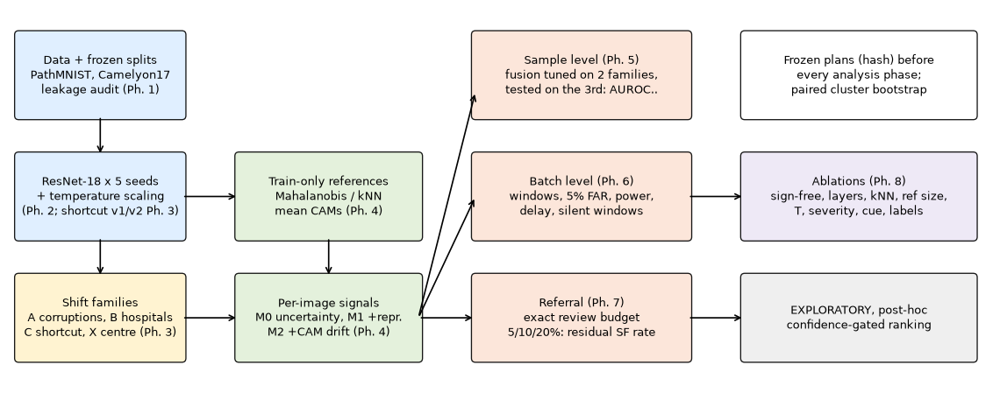

*Figure 1. Study pipeline. Phases (Ph.) are separate scripts; every analysis phase was pre-registered in a frozen plan before its numbers were computed.*  
**What to notice:** references and calibration use source data only; every detector is evaluated on a shift family it was not tuned on.

In [9]:
# ---------------------------------------------------------------- Figure 1: pipeline schematic --------------------
fig, ax = plt.subplots(figsize=(12, 4.6)); ax.set_axis_off(); ax.set_xlim(0, 12); ax.set_ylim(0, 4.6)
def box(x, y, w, h, text, c):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05", fc=c, ec="black", lw=0.8, alpha=0.9))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=8)
def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", lw=1.0))
box(0.1, 3.3, 2.0, 1.0, "Data + frozen splits\nPathMNIST, Camelyon17\nleakage audit (Ph. 1)", "#DDEEFF")
box(0.1, 1.8, 2.0, 1.0, "ResNet-18 x 5 seeds\n+ temperature scaling\n(Ph. 2; shortcut v1/v2 Ph. 3)", "#DDEEFF")
box(0.1, 0.3, 2.0, 1.0, "Shift families\nA corruptions, B hospitals\nC shortcut, X centre (Ph. 3)", "#FFF2CC")
box(2.8, 1.8, 2.2, 1.0, "Train-only references\nMahalanobis / kNN\nmean CAMs (Ph. 4)", "#E2F0D9")
box(2.8, 0.3, 2.2, 1.0, "Per-image signals\nM0 uncertainty, M1 +repr.\nM2 +CAM drift (Ph. 4)", "#E2F0D9")
box(5.7, 3.3, 2.6, 1.0, "Sample level (Ph. 5)\nfusion tuned on 2 families,\ntested on the 3rd: AUROC..", "#FCE4D6")
box(5.7, 1.8, 2.6, 1.0, "Batch level (Ph. 6)\nwindows, 5% FAR, power,\ndelay, silent windows", "#FCE4D6")
box(5.7, 0.3, 2.6, 1.0, "Referral (Ph. 7)\nexact review budget\n5/10/20%: residual SF rate", "#FCE4D6")
box(9.0, 1.8, 2.8, 1.0, "Ablations (Ph. 8)\nsign-free, layers, kNN, ref size,\nT, severity, cue, labels", "#EDE7F6")
box(9.0, 0.3, 2.8, 1.0, "EXPLORATORY, post-hoc\nconfidence-gated ranking", "#EEEEEE")
box(9.0, 3.3, 2.8, 1.0, "Frozen plans (hash) before\nevery analysis phase;\npaired cluster bootstrap", "#FFFFFF")
for a in [(1.1, 3.3, 1.1, 2.8), (1.1, 1.8, 1.1, 1.3), (2.1, 2.3, 2.8, 2.3), (2.1, 0.8, 2.8, 0.8), (3.9, 1.8, 3.9, 1.3),
          (5.0, 0.8, 5.7, 3.6), (5.0, 0.8, 5.7, 2.3), (5.0, 0.8, 5.7, 0.8), (8.3, 2.3, 9.0, 2.3), (8.3, 0.8, 9.0, 0.8)]:
    arrow(*a)
plt.show()
figcap(1, "Study pipeline. Phases (Ph.) are separate scripts; every analysis phase was pre-registered in a frozen plan before its numbers were computed.",
       "references and calibration use source data only; every detector is evaluated on a shift family it was not tuned on.")

<a id="s4"></a>
## 4. Classifier performance and calibration (Table 1)
Per-seed metrics on every split, before (`uncalibrated`) and after (`T_standard`) temperature scaling.

**Table 1 - classifier accuracy, AUROC, NLL, ECE, Brier per dataset, seed, split and calibration variant** - 90 rows

dataset,seed,split,variant,T,n,auroc,nll,ece,brier,acc
pathmnist,0,val_es,uncalibrated,1.0000,4999,1.0000,0.0089,0.0014,0.0038,0.9978
pathmnist,0,val_es,T_standard,0.8659,4999,1.0000,0.0088,0.0014,0.0037,0.9978
pathmnist,0,val_cal,uncalibrated,1.0000,4999,1.0000,0.0102,0.0016,0.0052,0.9962
pathmnist,0,val_cal,T_standard,0.8659,4999,1.0000,0.0100,0.0018,0.0051,0.9962
pathmnist,0,id_test,uncalibrated,1.0000,10247,1.0000,0.0141,0.0018,0.0065,0.9960
pathmnist,0,id_test,T_standard,0.8659,10247,1.0000,0.0139,0.0016,0.0064,0.9960
pathmnist,0,nct7k_test,uncalibrated,1.0000,7180,0.9978,0.1649,0.0213,0.0749,0.9536
pathmnist,0,nct7k_test,T_standard,0.8659,7180,0.9978,0.1800,0.0250,0.0764,0.9536
pathmnist,1,val_es,uncalibrated,1.0000,4999,1.0000,0.0087,0.0018,0.0033,0.9978
pathmnist,1,val_es,T_standard,0.9618,4999,1.0000,0.0086,0.0018,0.0033,0.9978


**Table 1 summary - mean and SD over 5 seeds (calibrated)** - 9 rows

dataset,split,acc_mean,acc_sd,ece_mean,ece_sd
camelyon17,id_test,0.9111,0.0442,0.0410,0.0385
camelyon17,ood_c1,0.8309,0.0341,0.0832,0.0296
camelyon17,ood_c2,0.6726,0.0397,0.2727,0.0425
camelyon17,val_cal,0.9582,0.0125,0.0057,0.0008
camelyon17,val_es,0.8933,0.0212,0.0448,0.0158
pathmnist,id_test,0.9956,0.0006,0.0015,0.0004
pathmnist,nct7k_test,0.9520,0.0040,0.0253,0.0036
pathmnist,val_cal,0.9964,0.0007,0.0015,0.0003
pathmnist,val_es,0.9976,0.0006,0.0017,0.0002


**What this shows:** PathMNIST is almost solved in distribution (id_test accuracy 0.9956 +- 0.0006, ECE 0.0015); Camelyon is harder and seed-dependent (id_test 0.911 +- 0.044) and degrades on hospital 2 (accuracy 0.673, ECE 0.273): the held-out hospitals are a real shift.

**Temperatures and training length per seed (outputs/stage2/calibration_*.csv)** - 10 rows

dataset,seed,T_standard,T_prior_reweighted,best_epoch,epochs_run,train_seconds
pathmnist,0,0.8659,,8,8,1202.2
pathmnist,1,0.9618,,8,8,1545.2
pathmnist,2,0.9370,,5,7,449.5
pathmnist,3,0.8868,,8,8,1516.1
pathmnist,4,0.9393,,8,8,1500.9
camelyon17,0,1.1832,,2,4,229.8
camelyon17,1,1.3425,,2,4,193.9
camelyon17,2,1.1356,,3,5,243.6
camelyon17,3,1.4000,,2,4,197.1
camelyon17,4,1.2328,,3,5,245.2


**What this shows:** fitted temperatures are 0.87-0.96 (PathMNIST) and 1.14-1.40 (Camelyon); Camelyon early-stopped after 2-3 epochs.

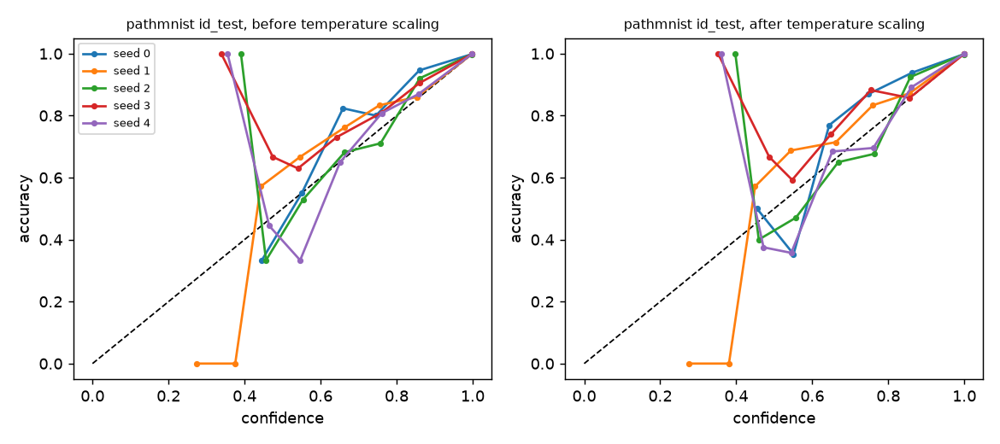

*Figure S3. Reliability diagrams, PathMNIST (saved Phase 2 figure).*  
**What to notice:** the in-distribution model is close to the diagonal.

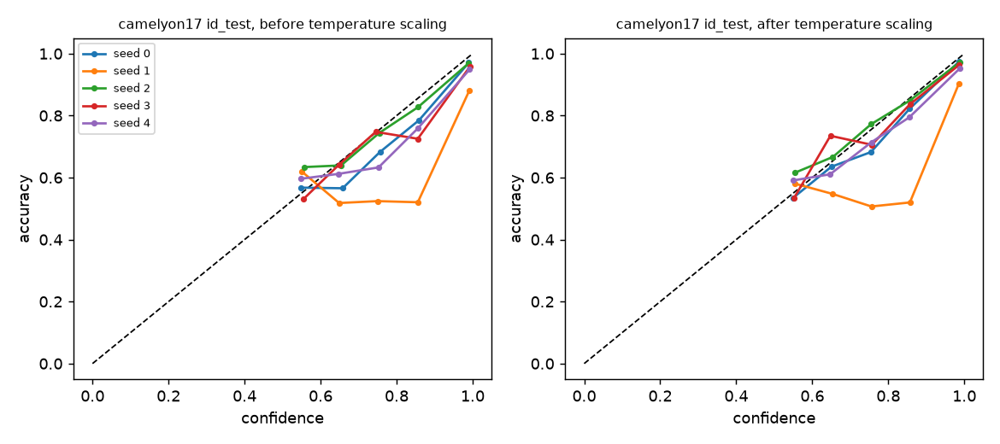

*Figure S4. Reliability diagrams, Camelyon17 (saved Phase 2 figure).*  
**What to notice:** over-confidence grows on the held-out hospitals.

In [10]:
mps = pd.concat([rd("stage2/metrics_per_seed_pathmnist.csv"), rd("stage2/metrics_per_seed_camelyon17.csv")], ignore_index=True)
for c in ("acc", "auroc", "nll", "ece", "brier", "T"):
    mps[c] = mps[c].round(4)
show(mps, "Table 1 - classifier accuracy, AUROC, NLL, ECE, Brier per dataset, seed, split and calibration variant")
summ = mps[mps.variant == "T_standard"].groupby(["dataset", "split"]).agg(acc_mean=("acc", "mean"), acc_sd=("acc", "std"),
                                                                           ece_mean=("ece", "mean"), ece_sd=("ece", "std")).round(4).reset_index()
show(summ, "Table 1 summary - mean and SD over 5 seeds (calibrated)")
pmid = one(summ, dataset="pathmnist", split="id_test"); cmid = one(summ, dataset="camelyon17", split="id_test")
c2 = one(summ, dataset="camelyon17", split="ood_c2")
say(f"**What this shows:** PathMNIST is almost solved in distribution (id_test accuracy {pmid.acc_mean:.4f} +- {pmid.acc_sd:.4f}, ECE "
    f"{pmid.ece_mean:.4f}); Camelyon is harder and seed-dependent (id_test {cmid.acc_mean:.3f} +- {cmid.acc_sd:.3f}) and degrades on "
    f"hospital 2 (accuracy {c2.acc_mean:.3f}, ECE {c2.ece_mean:.3f}): the held-out hospitals are a real shift.")
cal = pd.concat([rd("stage2/calibration_pathmnist.csv"), rd("stage2/calibration_camelyon17.csv")], ignore_index=True)
show(cal, "Temperatures and training length per seed (outputs/stage2/calibration_*.csv)")
say(f"**What this shows:** fitted temperatures are {cal[cal.dataset=='pathmnist'].T_standard.min():.2f}-"
    f"{cal[cal.dataset=='pathmnist'].T_standard.max():.2f} (PathMNIST) and {cal[cal.dataset=='camelyon17'].T_standard.min():.2f}-"
    f"{cal[cal.dataset=='camelyon17'].T_standard.max():.2f} (Camelyon); Camelyon early-stopped after 2-3 epochs.")
png("stage2/figures/reliability_pathmnist.png", width=700)
figcap("S3", "Reliability diagrams, PathMNIST (saved Phase 2 figure).", "the in-distribution model is close to the diagonal.")
png("stage2/figures/reliability_camelyon17.png", width=700)
figcap("S4", "Reliability diagrams, Camelyon17 (saved Phase 2 figure).", "over-confidence grows on the held-out hospitals.")

<a id="s5"></a>
## 5. Behaviour under shift (Figure 2)
Accuracy, mean calibrated confidence and the silent-failure rate (`sf_090`) per condition, mean over 5 seeds (seed SD in the tables).

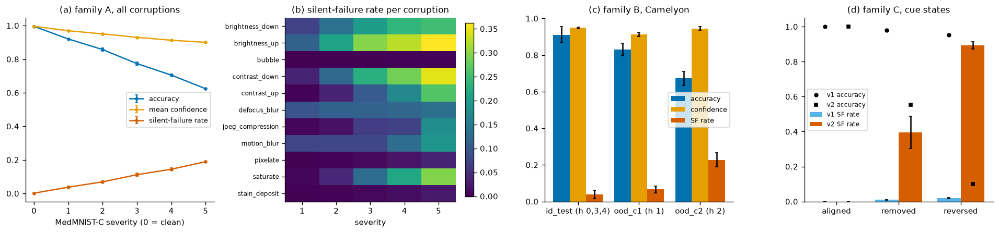

*Figure 2. Behaviour under shift: (a) family A by severity (error bars = seed SD); (b) silent-failure rate per corruption and severity; (c) family B per hospital; (d) family C cue states for the weak (v1) and strong (v2) shortcut.*  
**What to notice:** confidence falls far more slowly than accuracy, so silent failures grow with severity (severity 5: accuracy 0.624, confidence 0.901, SF rate 0.189); under a reversed v2 cue the model is almost always wrong yet confident (accuracy 0.100, SF rate 0.892).

**Family-level summary (outputs/stage3/family_summary.csv)** - 17 rows

family,condition,severity,dataset,model_kind,acc,acc_std,conf,conf_std,ece,ece_std,sf_rate,sf_rate_std,n_seeds
B,ood_c1,0,camelyon17,standard,0.830900,0.034051,0.912987,0.011236,0.083210,0.029568,0.066400,0.019389,5
B,ood_c2,0,camelyon17,standard,0.672600,0.039631,0.945265,0.009782,0.272729,0.042522,0.227350,0.038290,5
ID,id_test,0,camelyon17,standard,0.911080,0.044220,0.948881,0.005388,0.041057,0.038494,0.039160,0.023144,5
A,clean,0,pathmnist,standard,0.995800,0.000558,0.996071,0.000341,0.002472,0.000739,0.001933,0.000279,5
A,all corruptions,1,pathmnist,standard,0.920745,0.003927,0.969800,0.002582,0.050811,0.002550,0.037630,0.005714,5
A,all corruptions,2,pathmnist,standard,0.857527,0.008292,0.950953,0.002896,0.094571,0.006278,0.069218,0.007151,5
A,all corruptions,3,pathmnist,standard,0.773921,0.009194,0.930558,0.001808,0.157368,0.008970,0.112097,0.008627,5
A,all corruptions,4,pathmnist,standard,0.705782,0.006264,0.913309,0.001706,0.208417,0.007561,0.144479,0.008745,5
A,all corruptions,5,pathmnist,standard,0.624152,0.003177,0.900701,0.001988,0.277245,0.002274,0.189309,0.004571,5
C,aligned,0,pathmnist,shortcut,0.999733,0.000279,0.999445,0.000244,0.000530,0.000213,0.000000,0.000000,5


**Accuracy per corruption (rows) and severity (columns) (outputs/stage3/per_corruption_accuracy.csv)** - 12 rows

condition,0,1,2,3,4,5
brightness_down,,0.8369,0.7117,0.5791,0.4999,0.4592
brightness_up,,0.7531,0.5763,0.4232,0.3861,0.3414
bubble,,0.9942,0.9930,0.9914,0.9892,0.9851
clean,0.9958,,,,,
contrast_down,,0.9133,0.7732,0.6055,0.5126,0.4064
contrast_up,,0.9889,0.9231,0.7900,0.6626,0.5077
defocus_blur,,0.8432,0.7813,0.7179,0.6700,0.6138
jpeg_compression,,0.9837,0.9591,0.8605,0.8031,0.6359
motion_blur,,0.8445,0.8376,0.8423,0.7271,0.5995
pixelate,,0.9942,0.9910,0.9773,0.9535,0.9045


**Silent-failure rate per corruption and severity (outputs/stage3/per_corruption_sf_rate.csv)** - 12 rows

condition,0,1,2,3,4,5
brightness_down,,0.0739,0.1345,0.2005,0.2385,0.2516
brightness_up,,0.1130,0.2100,0.2965,0.3242,0.3619
bubble,,0.0024,0.0025,0.0027,0.0035,0.0040
clean,0.0019,,,,,
contrast_down,,0.0347,0.1231,0.2302,0.2853,0.3471
contrast_up,,0.0037,0.0355,0.1037,0.1700,0.2642
defocus_blur,,0.0948,0.1124,0.1136,0.1193,0.1331
jpeg_compression,,0.0054,0.0183,0.0656,0.0703,0.1775
motion_blur,,0.0753,0.0764,0.0765,0.1297,0.1882
pixelate,,0.0021,0.0036,0.0092,0.0189,0.0361


**Shortcut cue states (outputs/stage3/shortcut_states.csv)** - 6 rows

model_kind,condition,acc,acc_std,conf,ece,sf_rate,sf_rate_std
shortcut,aligned,0.999733,0.000279,0.999445,0.000530,0.000000,0.000000
shortcutv2,aligned,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000
shortcut,removed,0.978267,0.003677,0.989024,0.012057,0.010800,0.001366
shortcutv2,removed,0.554200,0.096169,0.975953,0.422501,0.395667,0.091719
shortcut,reversed,0.954267,0.004663,0.974908,0.023596,0.019600,0.003252
shortcutv2,reversed,0.100400,0.022011,0.995897,0.896235,0.892400,0.020259


**What this shows:** corruptions differ widely (brightness_up severity 5 SF rate 0.362 vs bubble 0.004); hospital 2 is the harder hospital (SF rate 0.227 vs 0.066); the weak shortcut v1 barely fails (reversed SF rate 0.020), which is why v2 is the primary family C.

In [11]:
fs = rd("stage3/family_summary.csv"); pca = rd("stage3/per_corruption_accuracy.csv"); psf = rd("stage3/per_corruption_sf_rate.csv")
ss = rd("stage3/shortcut_states.csv")
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
a = fs[(fs.family == "A")].sort_values("severity")
for m, lab, c in (("acc", "accuracy", OI["blue"]), ("conf", "mean confidence", OI["orange"]), ("sf_rate", "silent-failure rate", OI["vermillion"])):
    ax[0].errorbar(a.severity, a[m], yerr=a[m + "_std"], marker="o", ms=3, color=c, label=lab, capsize=2)
ax[0].set_xlabel("MedMNIST-C severity (0 = clean)"); ax[0].set_title("(a) family A, all corruptions"); ax[0].legend()
mat = psf.set_index("condition")[[str(s) for s in range(1, 6)]].drop(index="clean")
im = ax[1].imshow(mat.values, cmap="viridis", aspect="auto", vmin=0)
ax[1].set_yticks(range(len(mat))); ax[1].set_yticklabels(mat.index, fontsize=7); ax[1].set_xticks(range(5)); ax[1].set_xticklabels(range(1, 6))
ax[1].set_xlabel("severity"); ax[1].set_title("(b) silent-failure rate per corruption"); plt.colorbar(im, ax=ax[1], fraction=0.046)
b = fs[(fs.dataset == "camelyon17")].set_index("condition").loc[["id_test", "ood_c1", "ood_c2"]]
x = np.arange(3); w = 0.27
for i, (m, lab, c) in enumerate((("acc", "accuracy", OI["blue"]), ("conf", "confidence", OI["orange"]), ("sf_rate", "SF rate", OI["vermillion"]))):
    ax[2].bar(x + (i - 1) * w, b[m], w, yerr=b[m + "_std"], color=c, label=lab, capsize=2)
ax[2].set_xticks(x); ax[2].set_xticklabels(["id_test (h 0,3,4)", "ood_c1 (h 1)", "ood_c2 (h 2)"]); ax[2].set_title("(c) family B, Camelyon"); ax[2].legend()
for i, (k, lab) in enumerate((("shortcut", "v1"), ("shortcutv2", "v2"))):
    s = ss[ss.model_kind == k].set_index("condition").loc[["aligned", "removed", "reversed"]]
    ax[3].bar(np.arange(3) + (i - 0.5) * 0.38, s.sf_rate, 0.38, yerr=s.sf_rate_std, label=f"{lab} SF rate", color=[OI["sky"], OI["vermillion"]][i], capsize=2)
    ax[3].plot(np.arange(3) + (i - 0.5) * 0.38, s.acc, "k" + ["o", "s"][i], ms=4, label=f"{lab} accuracy")
ax[3].set_xticks(range(3)); ax[3].set_xticklabels(["aligned", "removed", "reversed"]); ax[3].set_title("(d) family C, cue states"); ax[3].legend(fontsize=7)
plt.tight_layout(); plt.show()
a5 = one(fs, family="A", severity=5); r2 = one(ss, model_kind="shortcutv2", condition="reversed")
figcap(2, "Behaviour under shift: (a) family A by severity (error bars = seed SD); (b) silent-failure rate per corruption and severity; "
          "(c) family B per hospital; (d) family C cue states for the weak (v1) and strong (v2) shortcut.",
       f"confidence falls far more slowly than accuracy, so silent failures grow with severity (severity 5: accuracy {a5.acc:.3f}, "
       f"confidence {a5.conf:.3f}, SF rate {a5.sf_rate:.3f}); under a reversed v2 cue the model is almost always wrong yet confident "
       f"(accuracy {r2.acc:.3f}, SF rate {r2.sf_rate:.3f}).")
show(fs, "Family-level summary (outputs/stage3/family_summary.csv)")
show(pca, "Accuracy per corruption (rows) and severity (columns) (outputs/stage3/per_corruption_accuracy.csv)")
show(psf, "Silent-failure rate per corruption and severity (outputs/stage3/per_corruption_sf_rate.csv)")
show(ss, "Shortcut cue states (outputs/stage3/shortcut_states.csv)")
say(f"**What this shows:** corruptions differ widely (brightness_up severity 5 SF rate {float(one(psf, condition='brightness_up')['5']):.3f} vs "
    f"bubble {float(one(psf, condition='bubble')['5']):.3f}); hospital 2 is the harder hospital (SF rate {one(fs, condition='ood_c2').sf_rate:.3f} vs "
    f"{one(fs, condition='ood_c1').sf_rate:.3f}); the weak shortcut v1 barely fails (reversed SF rate "
    f"{one(ss, model_kind='shortcut', condition='reversed').sf_rate:.3f}), which is why v2 is the primary family C.")

<a id="s6"></a>
## 6. Sample-level detection (Phase 5; plan `docs/analysis_plan_frozen.md`, commit e388dd6)
Can a per-image score rank silent failures above other cases on a family it was not tuned on? Pools: A = clean + all 55 corrupted
conditions; B = Camelyon id_test + ood_c1 + ood_c2; C = aligned + removed + reversed (v2); X = PathMNIST id_test + nct7k_test.

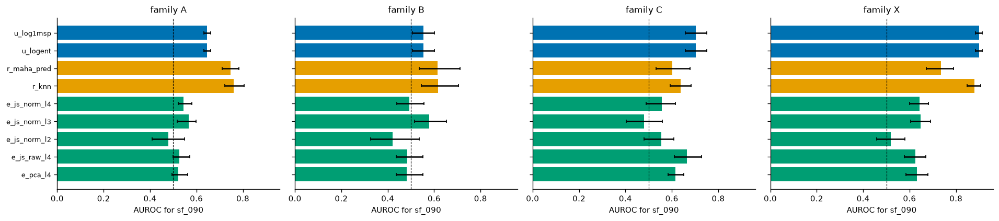

*Figure 3. Single-signal detection AUROC of silent failures per family (blue = uncertainty, orange = representation, green = explanation; 95% cluster-bootstrap CIs, 1,000 resamples, no fitting). SECONDARY (descriptive).*  
**What to notice:** pooled C AUROCs look moderate (log(1-MSP) 0.704, Mahalanobis 0.601) only because aligned and removed images are pooled with reversed ones; within the reversed state every signal is inverted (inversion diagnosis below).

**Figure 3 data (outputs/stage5/fig3_data.csv)** - 72 rows

family,signal,metric,estimate [95% CI]
A,u_log1msp,AUROC,"0.646 [0.632, 0.661]"
A,u_log1msp,AUPRC,"0.136 [0.117, 0.148]"
A,u_logent,AUROC,"0.646 [0.632, 0.662]"
A,u_logent,AUPRC,"0.136 [0.117, 0.149]"
A,r_maha_pred,AUROC,"0.746 [0.712, 0.783]"
A,r_maha_pred,AUPRC,"0.223 [0.192, 0.252]"
A,r_knn,AUROC,"0.760 [0.723, 0.805]"
A,r_knn,AUPRC,"0.200 [0.180, 0.241]"
A,e_js_norm_l4,AUROC,"0.544 [0.521, 0.579]"
A,e_js_norm_l4,AUPRC,"0.115 [0.104, 0.127]"


**What this shows:** on A, Mahalanobis alone reaches AUROC 0.746 [0.712, 0.783] vs 0.646 [0.632, 0.661] for log(1-MSP); the CAM signals stay near 0.5-0.6 everywhere.

In [12]:
f3 = rd("stage5/fig3_data.csv")
sig_order = ["u_log1msp", "u_logent", "r_maha_pred", "r_knn", "e_js_norm_l4", "e_js_norm_l3", "e_js_norm_l2", "e_js_raw_l4", "e_pca_l4"]
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6), sharex=True)
for a_, H in zip(ax, "ABCX"):
    d = f3[(f3.family == H) & (f3.metric == "AUROC")].set_index("signal").loc[sig_order]
    cols = [OI["blue"]] * 2 + [OI["orange"]] * 2 + [OI["green"]] * 5
    a_.barh(range(len(d)), d.estimate, xerr=[d.estimate - d.ci_low, d.ci_high - d.estimate], color=cols, capsize=2)
    a_.axvline(0.5, color="k", lw=0.7, ls="--"); a_.set_yticks(range(len(d))); a_.set_yticklabels(d.index if H == "A" else [], fontsize=8)
    a_.invert_yaxis(); a_.set_title(f"family {H}"); a_.set_xlabel("AUROC for sf_090")
plt.tight_layout(); plt.show()
figcap(3, "Single-signal detection AUROC of silent failures per family (blue = uncertainty, orange = representation, green = explanation; "
          "95% cluster-bootstrap CIs, 1,000 resamples, no fitting). SECONDARY (descriptive).",
       f"pooled C AUROCs look moderate (log(1-MSP) {one(f3, family='C', signal='u_log1msp', metric='AUROC').estimate:.3f}, "
       f"Mahalanobis {one(f3, family='C', signal='r_maha_pred', metric='AUROC').estimate:.3f}) only because aligned and removed images are pooled "
       "with reversed ones; within the reversed state every signal is inverted (inversion diagnosis below).")
show(fmt(f3, d=3, keep=["family", "signal", "metric"]), "Figure 3 data (outputs/stage5/fig3_data.csv)")
say(f"**What this shows:** on A, Mahalanobis alone reaches AUROC {rc(one(f3, family='A', signal='r_maha_pred', metric='AUROC'), signed=False)} vs "
    f"{rc(one(f3, family='A', signal='u_log1msp', metric='AUROC'), signed=False)} for log(1-MSP); the CAM signals stay near 0.5-0.6 everywhere.")

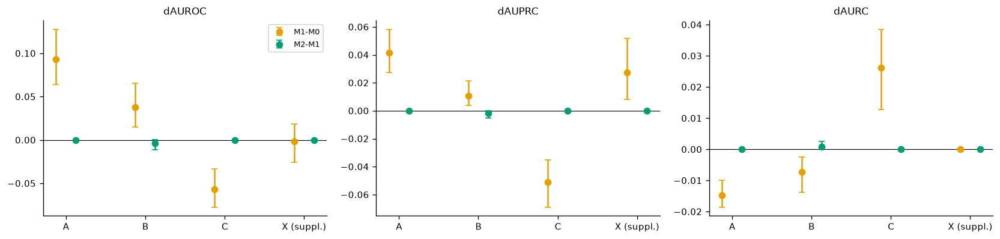

*Figure 4. Incremental value of adding representation (M1-M0) and explanation drift (M2-M1), held-out family, 95% paired CIs (lower dAURC is better). PRE-REGISTERED PRIMARY.*  
**What to notice:** M1 helps on A and B and hurts on C; M2-M1 sits exactly on zero because the non-negative fusion gave the CAM weight 0.

**Table 2 - M0 / M1 / M2 AUROC, AUPRC, AURC and primary contrasts (outputs/stage5/table2.csv)** - 60 rows

heldout,analysis,label,quantity,metric,n_per_seed,sf_rate,p_boot,jackknife_min,jackknife_max,verdict,estimate [95% CI]
A,primary,sf_090,M0,AUROC,168000,0.108608,,,,,"0.6458 [0.6315, 0.6614]"
A,primary,sf_090,M0,AUPRC,168000,0.108608,,,,,"0.1354 [0.1159, 0.1476]"
A,primary,sf_090,M0,AURC,168000,0.108608,,,,,"0.0550 [0.0476, 0.0628]"
A,primary,sf_090,M1,AUROC,168000,0.108608,,,,,"0.7392 [0.7137, 0.7698]"
A,primary,sf_090,M1,AUPRC,168000,0.108608,,,,,"0.1768 [0.1641, 0.1890]"
A,primary,sf_090,M1,AURC,168000,0.108608,,,,,"0.0402 [0.0307, 0.0492]"
A,primary,sf_090,M2,AUROC,168000,0.108608,,,,,"0.7392 [0.7137, 0.7698]"
A,primary,sf_090,M2,AUPRC,168000,0.108608,,,,,"0.1768 [0.1641, 0.1890]"
A,primary,sf_090,M2,AURC,168000,0.108608,,,,,"0.0402 [0.0307, 0.0492]"
A,primary,sf_090,M1-M0,dAUROC,168000,0.108608,0.000,8.739796e-02,9.843047e-02,improves,"0.0934 [0.0642, 0.1275]"


**What this shows:** primary contrasts (verdict rule: 'improves' only if the 95% CI excludes 0): M1-M0 dAUROC A +0.093 [+0.064, +0.127] (improves), B +0.038 [+0.015, +0.065] (improves), C -0.057 [-0.077, -0.033] (worse). M2-M1 dAUROC is -8.0e-06 (A), -0.0038 (B), -1.3e-06 (C): A's formal 'worse' verdict reflects a CI around -1e-6, i.e. no practical effect.

**Fusion weights (mean over seeds) per held-out family and detector (outputs/stage5/fusion_weights.csv; per-seed rows in Appendix A)** - 12 rows

heldout,model,w_intercept,w_u_log1msp,w_u_logent,w_r_maha_pred,w_e_js_norm_l4
A,M0,-3.879,1.863,1.863,,
A,M1,-4.614,1.545,1.544,1.706,
A,M2,-4.614,1.545,1.545,1.706,0.000
B,M0,-5.291,2.448,2.424,,
B,M1,-5.608,2.208,2.193,0.892,
B,M2,-5.623,2.177,2.160,0.872,0.114
C,M0,-2.997,0.665,0.664,,
C,M1,-3.998,0.574,0.574,1.516,
C,M2,-3.998,0.574,0.574,1.516,0.000
X,M0,-3.954,1.677,1.665,,


**What this shows:** the CAM weight is exactly 0 when A, C or X is held out and small (about 0.11) when B is held out - the non-negative fusion cannot use CAM drift.

**Incremental logistic regression on the held-out family (descriptive; outputs/stage5/incremental_logit.csv)** - 15 rows

heldout,seed,LR_M1_vs_M0,wald_p_maha,coef_maha,LR_M2_vs_M1,wald_p_cam,coef_cam
A,0,4444.2420,0.0000,4.1025,1090.8815,0.0,-1.0158
A,1,11333.8893,0.0000,7.7267,330.7064,0.0,-0.5472
A,2,6728.0687,0.0000,5.0286,32.0395,0.0,-0.1665
A,3,6844.4675,0.0000,4.4526,130.8128,0.0,-0.3725
A,4,9337.5881,0.0000,5.6827,190.7798,0.0,-0.4301
B,0,675.3830,0.0000,2.5844,123.6345,0.0,-1.1484
B,1,376.8242,0.0000,1.7984,101.4957,0.0,-1.0165
B,2,434.5387,0.0000,1.9097,371.7564,0.0,-1.8432
B,3,1197.8782,0.0000,3.2716,263.3542,0.0,-1.6233
B,4,429.7025,0.0000,1.6804,1075.7775,0.0,-2.6399


**What this shows:** given M0 + Mahalanobis, the unconstrained CAM coefficient is negative in every held-out family (median -0.43 A, -1.62 B, -1.86 C): confident errors have *typical-looking* explanations - the reason the pre-registered monotone M2 adds nothing (and the motivation of the Phase 8 sign-free ablation). The p-values ignore clustering and are descriptive.

In [13]:
# Figure 4 + Table 2 (PRE-REGISTERED PRIMARY)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
for a_, met in zip(ax, ("dAUROC", "dAUPRC", "dAURC")):
    for j, q in enumerate(("M1-M0", "M2-M1")):
        d = t2[(t2.quantity == q) & (t2.metric == met)].set_index("heldout").loc[list("ABCX")]
        a_.errorbar(np.arange(4) + (j - 0.5) * 0.25, d.estimate, yerr=[d.estimate - d.ci_low, d.ci_high - d.estimate], fmt="o",
                    color=[OI["orange"], OI["green"]][j], capsize=3, label=q)
    a_.axhline(0, color="k", lw=0.7); a_.set_xticks(range(4)); a_.set_xticklabels(["A", "B", "C", "X (suppl.)"]); a_.set_title(met)
ax[0].legend(); plt.tight_layout(); plt.show()
figcap(4, "Incremental value of adding representation (M1-M0) and explanation drift (M2-M1), held-out family, 95% paired CIs "
          "(lower dAURC is better). PRE-REGISTERED PRIMARY.",
       "M1 helps on A and B and hurts on C; M2-M1 sits exactly on zero because the non-negative fusion gave the CAM weight 0.")
t2f = fmt(t2, d=4, signed=False, keep=["heldout", "analysis", "label", "quantity", "metric", "n_per_seed", "sf_rate", "p_boot", "jackknife_min", "jackknife_max", "verdict"])
show(t2f, "Table 2 - M0 / M1 / M2 AUROC, AUPRC, AURC and primary contrasts (outputs/stage5/table2.csv)")
say(f"**What this shows:** primary contrasts (verdict rule: 'improves' only if the 95% CI excludes 0): M1-M0 dAUROC "
    f"A {rc(t2r('A','M1-M0','dAUROC'))} ({t2r('A','M1-M0','dAUROC').verdict}), B {rc(t2r('B','M1-M0','dAUROC'))} "
    f"({t2r('B','M1-M0','dAUROC').verdict}), C {rc(t2r('C','M1-M0','dAUROC'))} ({t2r('C','M1-M0','dAUROC').verdict}). "
    f"M2-M1 dAUROC is {t2r('A','M2-M1','dAUROC').estimate:+.1e} (A), {t2r('B','M2-M1','dAUROC').estimate:+.4f} (B), "
    f"{t2r('C','M2-M1','dAUROC').estimate:+.1e} (C): A's formal 'worse' verdict reflects a CI around -1e-6, i.e. no practical effect.")
fw = rd("stage5/fusion_weights.csv")
fwm = fw.groupby(["heldout", "model"])[[c for c in fw.columns if c.startswith("w_")]].mean().round(3).reset_index()
show(fwm, "Fusion weights (mean over seeds) per held-out family and detector (outputs/stage5/fusion_weights.csv; per-seed rows in Appendix A)")
say("**What this shows:** the CAM weight is exactly 0 when A, C or X is held out and small (about 0.11) when B is held out - the "
    "non-negative fusion cannot use CAM drift.")
il = rd("stage5/incremental_logit.csv")
show(il.round(4), "Incremental logistic regression on the held-out family (descriptive; outputs/stage5/incremental_logit.csv)")
say(f"**What this shows:** given M0 + Mahalanobis, the unconstrained CAM coefficient is negative in every held-out family (median "
    f"{il[il.heldout=='A'].coef_cam.median():.2f} A, {il[il.heldout=='B'].coef_cam.median():.2f} B, {il[il.heldout=='C'].coef_cam.median():.2f} C): "
    "confident errors have *typical-looking* explanations - the reason the pre-registered monotone M2 adds nothing (and the motivation of the "
    "Phase 8 sign-free ablation). The p-values ignore clustering and are descriptive.")

In [14]:
sst = rd("stage5/seed_stability_per_seed.csv")
show(sst.round(4), "Seed stability of M0 / M1 / M2 per held-out family and seed (outputs/stage5/seed_stability_per_seed.csv)")
rng_ = sst.groupby(["heldout", "model"]).AUROC.agg(["min", "max"]).round(3)
say(f"**What this shows:** per-seed AUROC ranges are narrow, e.g. A M1 {rng_.loc[('A','M1'),'min']}-{rng_.loc[('A','M1'),'max']}, "
    f"C M0 {rng_.loc[('C','M0'),'min']}-{rng_.loc[('C','M0'),'max']}; the conclusions do not hinge on one seed.")
sens5 = rd("stage5/sensitivity.csv")
v = sens5[sens5.quantity.str.contains("-") & (sens5.metric == "dAUROC")]
show(fmt(v, d=4, signed=True, keep=["variant", "heldout", "quantity", "metric", "p_boot", "q_bh", "jackknife_min", "jackknife_max"]),
     "Phase 5 sensitivity analyses: dAUROC contrasts per variant (filtered view of outputs/stage5/sensitivity.csv; full table in Appendix A)")
mx = v[v.quantity == "M2-M1"]
say(f"**What this shows:** no sensitivity variant makes M2 beat M1 (largest M2-M1 dAUROC {mx.estimate.max():+.4f}); the M1-M0 gain on A "
    f"survives kNN ({rc(one(v, variant='kNN instead of Mahalanobis', heldout='A', quantity='M1-M0'))}) and sf_095 "
    f"({rc(one(v, variant='label sf_095', heldout='A', quantity='M1-M0'))}) and shrinks under the degenerate sf_tau label "
    f"({rc(one(v, variant='label sf_tau', heldout='A', quantity='M1-M0'))}).")
sb = rd("stage5/secondary_breakdowns.csv")
v = sb[sb.quantity.str.contains("-") & (sb.metric == "dAUROC")]
show(fmt(v, d=4, signed=True, keep=["analysis", "heldout", "level", "quantity", "n_per_seed", "sf_rate", "p_boot", "q_bh"]),
     "Phase 5 secondary breakdowns: dAUROC per corruption, severity and condition (filtered view of outputs/stage5/secondary_breakdowns.csv; full in Appendix A)")
say(f"**What this shows:** SECONDARY (BH within each breakdown). M1-M0 grows with severity on A (severity 1 "
    f"{rc(one(v, analysis='A by severity', level='1', quantity='M1-M0'))}, severity 5 {rc(one(v, analysis='A by severity', level='5', quantity='M1-M0'))}) "
    f"and is negative in C removed ({rc(one(v, analysis='C by condition', level='removed', quantity='M1-M0'))}).")

**Seed stability of M0 / M1 / M2 per held-out family and seed (outputs/stage5/seed_stability_per_seed.csv)** - 45 rows

heldout,model,seed,AUROC,AUPRC,AURC
A,M0,0,0.6671,0.1416,0.0502
A,M0,1,0.6331,0.1316,0.0576
A,M0,2,0.6268,0.1300,0.0592
A,M0,3,0.6552,0.1282,0.0485
A,M0,4,0.6467,0.1455,0.0594
A,M1,0,0.7405,0.1770,0.0398
A,M1,1,0.7507,0.1847,0.0386
A,M1,2,0.7131,0.1633,0.0448
A,M1,3,0.7464,0.1667,0.0353
A,M1,4,0.7453,0.1923,0.0427


**What this shows:** per-seed AUROC ranges are narrow, e.g. A M1 0.713-0.751, C M0 0.673-0.73; the conclusions do not hinge on one seed.

**Phase 5 sensitivity analyses: dAUROC contrasts per variant (filtered view of outputs/stage5/sensitivity.csv; full table in Appendix A)** - 60 rows

variant,heldout,quantity,metric,p_boot,q_bh,jackknife_min,jackknife_max,estimate [95% CI]
kNN instead of Mahalanobis,A,M1-M0,dAUROC,0.000,0.000000,2.639454e-02,3.484350e-02,"+0.0308 [+0.0136, +0.0542]"
kNN instead of Mahalanobis,A,M2-M1,dAUROC,0.309,0.388951,1.011792e-07,2.051644e-06,"+0.0000 [-0.0000, +0.0000]"
kNN instead of Mahalanobis,B,M1-M0,dAUROC,0.000,0.000000,1.163278e-02,1.996555e-02,"+0.0160 [+0.0038, +0.0340]"
kNN instead of Mahalanobis,B,M2-M1,dAUROC,0.257,0.345224,-2.645883e-03,-4.317478e-05,"-0.0021 [-0.0064, +0.0002]"
kNN instead of Mahalanobis,C,M1-M0,dAUROC,0.000,0.000000,-4.148166e-02,-3.591971e-02,"-0.0388 [-0.0532, -0.0256]"
kNN instead of Mahalanobis,C,M2-M1,dAUROC,0.131,0.212034,3.360479e-06,8.470118e-06,"+0.0000 [-0.0000, +0.0000]"
layer3 CAM,A,M1-M0,dAUROC,0.000,0.000000,8.739796e-02,9.843047e-02,"+0.0934 [+0.0642, +0.1275]"
layer3 CAM,A,M2-M1,dAUROC,0.084,0.152727,-5.854551e-06,-2.616167e-06,"-0.0000 [-0.0000, +0.0000]"
layer3 CAM,B,M1-M0,dAUROC,0.000,0.000000,3.159387e-02,4.757460e-02,"+0.0381 [+0.0150, +0.0651]"
layer3 CAM,B,M2-M1,dAUROC,0.367,0.440400,-8.656233e-06,-4.239141e-07,"-0.0000 [-0.0000, +0.0000]"


**What this shows:** no sensitivity variant makes M2 beat M1 (largest M2-M1 dAUROC +0.0043); the M1-M0 gain on A survives kNN (+0.031 [+0.014, +0.054]) and sf_095 (+0.109 [+0.073, +0.153]) and shrinks under the degenerate sf_tau label (+0.009 [+0.001, +0.021]).

**Phase 5 secondary breakdowns: dAUROC per corruption, severity and condition (filtered view of outputs/stage5/secondary_breakdowns.csv; full in Appendix A)** - 48 rows

analysis,heldout,level,quantity,n_per_seed,sf_rate,p_boot,q_bh,estimate [95% CI]
A by corruption,A,brightness_down,M1-M0,15000,0.179787,0.000,0.000000,"+0.1120 [+0.0741, +0.1730]"
A by corruption,A,brightness_down,M2-M1,15000,0.179787,0.022,0.044757,"-0.0000 [-0.0000, -0.0000]"
A by corruption,A,brightness_up,M1-M0,15000,0.261120,0.000,0.000000,"+0.1219 [+0.0871, +0.1716]"
A by corruption,A,brightness_up,M2-M1,15000,0.261120,0.025,0.046154,"-0.0000 [-0.0000, -0.0000]"
A by corruption,A,bubble,M1-M0,15000,0.003013,0.012,0.032000,"-0.0568 [-0.0923, -0.0127]"
A by corruption,A,bubble,M2-M1,15000,0.003013,0.097,0.136941,"+0.0000 [-0.0000, +0.0000]"
A by corruption,A,clean,M1-M0,3000,0.001933,0.032,0.052364,"-0.0560 [-0.0983, -0.0063]"
A by corruption,A,clean,M2-M1,3000,0.001933,1.000,1.000000,"+0.0000 [+0.0000, +0.0000]"
A by corruption,A,contrast_down,M1-M0,15000,0.204093,0.000,0.000000,"+0.1659 [+0.0778, +0.2754]"
A by corruption,A,contrast_down,M2-M1,15000,0.204093,0.029,0.049714,"-0.0000 [-0.0000, -0.0000]"


**What this shows:** SECONDARY (BH within each breakdown). M1-M0 grows with severity on A (severity 1 +0.045 [+0.024, +0.064], severity 5 +0.109 [+0.067, +0.162]) and is negative in C removed (-0.176 [-0.261, -0.107]).

In [15]:
inv = rd("stage5/inversion_diagnosis.json")
au = pd.DataFrame(inv["auroc_sf090"]).T.reset_index().rename(columns={"index": "cue state"})
show(au.round(4), "Family C (v2) inversion diagnosis: single-signal AUROC pooled and within each cue state (outputs/stage5/inversion_diagnosis.json)")
prof = pd.DataFrame({k: {kk: (json.dumps(vv) if isinstance(vv, dict) else vv) for kk, vv in d.items()} for k, d in inv["reversed_profile"].items()}).T
show(prof.reset_index().rename(columns={"index": "group (reversed state)"}), "Profile of correct vs silently wrong predictions under the reversed cue")
say(f"**What this shows:** within the reversed state every signal is far below 0.5 (log(1-MSP) {inv['auroc_sf090']['reversed']['u_log1msp']:.3f}, "
    f"Mahalanobis {inv['auroc_sf090']['reversed']['r_maha_pred']:.3f}), so the inversion is **not** a pooling artefact "
    f"({inv['reading']}). The few correct predictions are almost all tumour-epithelium images whose tissue overrides the cue; they are the most "
    "atypical cases on every signal, whereas the confident errors look like normal members of the cue's class.")

**Family C (v2) inversion diagnosis: single-signal AUROC pooled and within each cue state (outputs/stage5/inversion_diagnosis.json)** - 4 rows

cue state,n_per_seed,sf_rate,acc,u_log1msp,r_maha_pred,r_knn,e_js_norm_l4
pooled,9000.0,0.4294,0.5516,0.7038,0.6007,0.6386,0.5567
aligned,3000.0,0.0000,1.0000,,,,
removed,3000.0,0.3957,0.5543,0.6150,0.4239,0.6646,0.5185
reversed,3000.0,0.8924,0.1004,0.1225,0.0521,0.0393,0.2002


**Profile of correct vs silently wrong predictions under the reversed cue** - 3 rows

group (reversed state),n_per_seed,mean_confidence,class_counts,median_pct_u_log1msp,median_pct_r_maha_pred,median_pct_r_knn,median_pct_e_js_norm_l4
correct,301.2,0.982671,"{""0"": 15, ""1"": 14, ""8"": 1477}",0.999969,0.9994,0.999961,0.968794
wrong_confident (sf_090),2677.2,0.99963,"{""0"": 1507, ""1"": 1880, ""2"": 1685, ""3"": 1690, ""4"": 1305, ""5"": 1980, ""6"": 1284, ""7"": 1530, ""8"": 525}",0.9994,0.912382,0.965793,0.876975
wrong_low_conf,21.6,0.717525,"{""0"": 3, ""1"": 11, ""6"": 1, ""8"": 93}",0.99998,0.9986,0.999969,0.999974


**What this shows:** within the reversed state every signal is far below 0.5 (log(1-MSP) 0.122, Mahalanobis 0.052), so the inversion is **not** a pooling artefact (inversion holds WITHIN the reversed state (not a pooling artefact)). The few correct predictions are almost all tumour-epithelium images whose tissue overrides the cue; they are the most atypical cases on every signal, whereas the confident errors look like normal members of the cue's class.

<a id="s7"></a>
## 7. Batch (window) monitoring (Phase 6; plan `docs/batch_plan_frozen.md`, commit 931fb36; amendment A1, commit 4ea78c3)
Can a monitor that looks at a *window* of 100 deployed images raise an alarm when the window is silently failing? The pre-registered
FAR check is shown first, because it **failed**.

In [16]:
def far_pivot(t):
    d = t[t["size"] == 100].copy(); d["cell"] = d.H + " / " + d.kind
    p = d.pivot(index="cell", columns="stat", values="far").round(3)
    f = d.pivot(index="cell", columns="stat", values="flag_outside_3_7pct")
    return p.astype(str) + np.where(f.astype(str) == "True", " *", "")
show(far_pivot(far6).reset_index(), "Actual FAR on held-out id_test windows, PRE-REGISTERED thresholds (val_cal); * = outside 3-7%")
show(far_pivot(far6a).reset_index(), "Actual FAR, amendment A1 (thresholds from a disjoint row-hash half of the ID pool); * = outside 3-7%")
say(f"**What this shows:** with the pre-registered val_cal thresholds {nfar_pre} of {ncell} (statistic x family) cells are outside "
    f"the 3-7% tolerance (e.g. mean uncertainty on A: {one(far6, H='A', kind='standard', size=100, stat='u_mean').far:.3f}; combined monitor on A: "
    f"{one(far6, H='A', kind='standard', size=100, stat='comb').far:.3f}). Diagnosis (before any power was inspected): fresh val_cal windows "
    "alarm at 4.6-6.2% (docs/batch_plan_amendment_1.md), so the pipeline is unbiased, but val_cal and id_test are not exchangeable at window level: a ~0.1 SD row-level "
    "difference becomes ~1 SD for a mean over 100 images. Powers at such different FARs cannot be ranked. Amendment A1 (committed before "
    f"computing it) draws thresholds and evaluation windows from two halves of the same ID pool; {nfar_a1}/{ncell} cells remain outside "
    f"(mean uncertainty A {one(far6a, H='A', kind='standard', size=100, stat='u_mean').far:.3f}, B {one(far6a, H='B', kind='standard', size=100, stat='u_mean').far:.3f}).")

**Actual FAR on held-out id_test windows, PRE-REGISTERED thresholds (val_cal); * = outside 3-7%** - 5 rows

stat,cell,comb,e_cam_l2,e_cam_l3,e_cam_l4,e_img_mean,r_knn_mean,r_maha_mean,r_mmd,u_ks,u_mean,u_p90
,A / standard,0.563 *,0.647 *,0.303 *,0.066,0.059,0.161 *,0.11 *,0.26 *,0.354 *,0.37 *,0.384 *
,B / standard,0.288 *,0.126 *,0.109 *,0.086 *,0.141 *,0.453 *,0.793 *,0.409 *,0.266 *,0.253 *,0.22 *
,C / shortcut,0.25 *,0.747 *,0.232 *,0.838 *,0.37 *,0.022 *,0.032,0.15 *,0.114 *,0.054,0.008 *
,C / shortcutv2,0.343 *,0.493 *,0.247 *,0.684 *,0.695 *,0.035,0.051,0.132 *,0.263 *,0.277 *,0.053
,X / standard,0.556 *,0.647 *,0.303 *,0.066,0.059,0.161 *,0.11 *,0.26 *,0.354 *,0.37 *,0.384 *


**Actual FAR, amendment A1 (thresholds from a disjoint row-hash half of the ID pool); * = outside 3-7%** - 5 rows

stat,cell,comb,e_cam_l2,e_cam_l3,e_cam_l4,e_img_mean,r_knn_mean,r_maha_mean,r_mmd,u_ks,u_mean,u_p90
,A / standard,0.073 *,0.051,0.052,0.056,0.054,0.068,0.028 *,0.054,0.07 *,0.082 *,0.099 *
,B / standard,0.046,0.067,0.041,0.042,0.054,0.026 *,0.036,0.052,0.06,0.044,0.052
,C / shortcut,0.016 *,0.027 *,0.035,0.017 *,0.02 *,0.045,0.049,0.027 *,0.029 *,0.01 *,0.046
,C / shortcutv2,0.04,0.026 *,0.028 *,0.009 *,0.02 *,0.037,0.043,0.024 *,0.055,0.044,0.052
,X / standard,0.079 *,0.051,0.052,0.056,0.054,0.068,0.028 *,0.054,0.07 *,0.082 *,0.099 *


**What this shows:** with the pre-registered val_cal thresholds 46 of 55 (statistic x family) cells are outside the 3-7% tolerance (e.g. mean uncertainty on A: 0.369; combined monitor on A: 0.563). Diagnosis (before any power was inspected): fresh val_cal windows alarm at 4.6-6.2% (docs/batch_plan_amendment_1.md), so the pipeline is unbiased, but val_cal and id_test are not exchangeable at window level: a ~0.1 SD row-level difference becomes ~1 SD for a mean over 100 images. Powers at such different FARs cannot be ranked. Amendment A1 (committed before computing it) draws thresholds and evaluation windows from two halves of the same ID pool; 23/55 cells remain outside (mean uncertainty A 0.083, B 0.044).

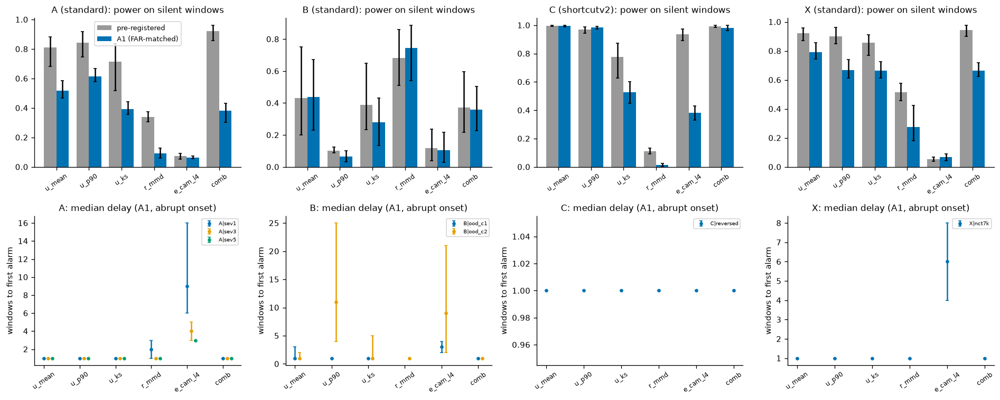

*Figure 5. Batch monitoring. Top: power (share of silently failed windows that alarm) at nominal 5% FAR, pre-registered thresholds vs FAR-matched A1, window size 100, 95% CIs. Bottom: Kaplan-Meier median detection delay after an abrupt full shift (A1; missing points = median not reached within 30 windows).*  
**What to notice:** pre-registered powers are inflated wherever the FAR is inflated; at matched FAR (A1) MMD beats mean uncertainty only for the new hospitals (B), and window CAM drift beats MMD only on the shortcut, where MMD is blind.

**Declared primary contrasts (power on silent windows), pre-registered vs amendment A1, side by side** - 12 rows

held-out,model,contrast,pre-registered (unequal FAR),A1 FAR-matched,silent windows
A,standard,comb - u_mean,"+0.114 [+0.076, +0.176] improves","-0.135 [-0.229, -0.046] worse",1629
A,standard,r_mmd - u_mean,"-0.469 [-0.570, -0.342] worse","-0.428 [-0.493, -0.380] worse",1629
A,standard,e_cam_l4 - r_mmd,"-0.266 [-0.311, -0.221] worse","-0.027 [-0.064, +0.007] inconclusive",1629
B,standard,comb - u_mean,"-0.061 [-0.232, +0.072] inconclusive","-0.081 [-0.289, +0.081] inconclusive",3689
B,standard,r_mmd - u_mean,"+0.249 [+0.078, +0.379] improves","+0.306 [+0.191, +0.448] improves",3689
B,standard,e_cam_l4 - r_mmd,"-0.563 [-0.739, -0.396] worse","-0.640 [-0.844, -0.408] worse",3689
C,shortcutv2,comb - u_mean,"-0.005 [-0.011, +0.000] inconclusive","-0.012 [-0.036, +0.007] inconclusive",664
C,shortcutv2,r_mmd - u_mean,"-0.887 [-0.908, -0.860] worse","-0.980 [-0.992, -0.967] worse",664
C,shortcutv2,e_cam_l4 - r_mmd,"+0.827 [+0.780, +0.864] improves","+0.369 [+0.323, +0.414] improves",664
X,standard,comb - u_mean,"+0.022 [-0.001, +0.070] inconclusive","-0.130 [-0.189, -0.093] worse",376


**What this shows:** at matched FAR the combined monitor never beats mean uncertainty (A -0.135 [-0.229, -0.046]); MMD beats mean uncertainty only on B (+0.306 [+0.191, +0.448]); window CAM drift beats MMD only on C v2 (+0.369 [+0.323, +0.414]), where MMD is blind. The pre-registered column ranks statistics at different FARs and must not be read as a comparison.

In [17]:
pp = rd("stage6/power_pooled.csv"); ppa = rd("stage6/a1/power_pooled.csv")
dl = rd("stage6/detection_delay.csv"); dla = rd("stage6/a1/detection_delay.csv")
stats_ = ["u_mean", "u_p90", "u_ks", "r_mmd", "e_cam_l4", "comb"]
fams = [("A", "standard"), ("B", "standard"), ("C", "shortcutv2"), ("X", "standard")]
fig, ax = plt.subplots(2, 4, figsize=(16, 6.4))
for j, (H, k) in enumerate(fams):
    for i, (tab, lab, c) in enumerate(((pp, "pre-registered", OI["grey"]), (ppa, "A1 (FAR-matched)", OI["blue"]))):
        d = tab[(tab.H == H) & (tab.kind == k) & (tab["size"] == 100) & (tab["mask"] == "silent_pooled")].set_index("stat").loc[stats_]
        ax[0, j].bar(np.arange(6) + (i - 0.5) * 0.38, d.power, 0.38, yerr=[d.power - d.ci_low, d.ci_high - d.power], color=c, label=lab, capsize=2)
    ax[0, j].set_xticks(range(6)); ax[0, j].set_xticklabels(stats_, rotation=35, fontsize=7); ax[0, j].set_title(f"{H} ({k}): power on silent windows")
    d = dla[(dla.H == H) & (dla.kind == k) & (dla.onset.astype(str) == "1.0")]
    for i, (cell, g) in enumerate(d.groupby("cell")):
        g = g.set_index("stat").reindex(stats_)
        ax[1, j].errorbar(np.arange(6) + i * 0.12, g.median_delay, yerr=[g.median_delay - g.ci_low, g.ci_high - g.median_delay], fmt="o", ms=3, capsize=2, label=cell)
    ax[1, j].set_xticks(range(6)); ax[1, j].set_xticklabels(stats_, rotation=35, fontsize=7); ax[1, j].set_title(f"{H}: median delay (A1, abrupt onset)")
    ax[1, j].set_ylabel("windows to first alarm"); ax[1, j].legend(fontsize=6)
ax[0, 0].legend(); plt.tight_layout(); plt.show()
figcap(5, "Batch monitoring. Top: power (share of silently failed windows that alarm) at nominal 5% FAR, pre-registered thresholds vs "
          "FAR-matched A1, window size 100, 95% CIs. Bottom: Kaplan-Meier median detection delay after an abrupt full shift (A1; missing "
          "points = median not reached within 30 windows).",
       "pre-registered powers are inflated wherever the FAR is inflated; at matched FAR (A1) MMD beats mean uncertainty only for the new "
       "hospitals (B), and window CAM drift beats MMD only on the shortcut, where MMD is blind.")
cmp = []
for H, k in fams:
    for a_, b_ in (("comb", "u_mean"), ("r_mmd", "u_mean"), ("e_cam_l4", "r_mmd")):
        r0, r1 = c6r(c6, H, a_, b_, k), c6r(c6a, H, a_, b_, k)
        cmp.append({"held-out": H, "model": k, "contrast": f"{a_} - {b_}", "pre-registered (unequal FAR)": rc6(r0) + f" {r0.verdict}",
                    "A1 FAR-matched": rc6(r1) + f" {r1.verdict}", "silent windows": int(r1.n_windows)})
cmp = pd.DataFrame(cmp)
show(cmp, "Declared primary contrasts (power on silent windows), pre-registered vs amendment A1, side by side")
say(f"**What this shows:** at matched FAR the combined monitor never beats mean uncertainty (A {rc6(c6r(c6a,'A','comb','u_mean'))}); MMD beats "
    f"mean uncertainty only on B ({rc6(c6r(c6a,'B','r_mmd','u_mean'))}); window CAM drift beats MMD only on C v2 "
    f"({rc6(c6r(c6a,'C','e_cam_l4','r_mmd','shortcutv2'))}), where MMD is blind. The pre-registered column ranks statistics at different FARs and must not be "
    "read as a comparison.")

In [18]:
pc = rd("stage6/power_cells.csv"); pca1 = rd("stage6/a1/power_cells.csv")
def share(t):
    d = t[(t["size"] == 100) & ~t.cell.str.startswith("Acorr") & (t.fraction > 0)]
    return d.groupby(["H", "kind"]).apply(lambda g: pd.Series({"shifted windows": int(g.n_windows.sum()), "silent windows": int(g.n_silent.sum()),
                                                               "silent share": round(g.n_silent.sum() / g.n_windows.sum(), 4)})).reset_index()
sh = share(pc).merge(share(pca1), on=["H", "kind"], suffixes=(" (pre-reg.)", " (A1)"))
show(sh, "Share of shifted windows (f > 0, primary cells, size 100) that are silently failed (computed from outputs/stage6/*/power_cells.csv)")
say(f"**What this shows:** silently failed windows are rare except for the new hospitals (B: {one(sh, H='B', kind='standard')['silent share (A1)']:.1%} "
    f"under A1; share = silent windows / all windows with shifted fraction > 0, window size 100, summed over the primary cells and 5 seeds). **Plan-wording correction:** the plan expected uncertainty statistics to be blind to silent windows by construction; that "
    "holds for mean confidence, but the log-scale mean uncertainty still alarms on many silent windows because the silent definition constrains "
    "the mean confidence, not its tails (see the power figure).")
w = c6a[(c6a["set"] == "primary") & (c6a["mask"] == "silent_pooled")]
show(fmt(w, est="diff", d=3, signed=True, keep=["H", "kind", "size", "a", "b", "power_a", "power_b", "n_windows", "p_boot", "q_bh", "bh_family", "verdict"]),
     "Window-size sensitivity (50 / 100 / 200), A1 primary contrasts on silent windows (filtered view of outputs/stage6/a1/contrasts.csv)")
base = w[w["size"] == 100].set_index(["H", "kind", "a", "b"])
sig = base[(base.ci_low > 0) | (base.ci_high < 0)]
same = sum(int(np.sign(r["diff"]) == np.sign(base.loc[k, "diff"])) for k, r in w[w["size"] != 100].set_index(["H", "kind", "a", "b"]).iterrows() if k in sig.index)
nsz = sum(1 for k in w[w["size"] != 100].set_index(["H", "kind", "a", "b"]).index if k in sig.index)
say(f"**What this shows:** SECONDARY (BH within the window-size family). Of the {len(sig)} size-100 contrasts whose CI excludes 0, "
    f"{same} of {nsz} size-50 / size-200 counterparts keep the same sign; contrasts near zero can flip.")
d1 = dla[dla.onset.astype(str) == "1.0"]
show(d1.round(3), "Detection delay after an abrupt full shift, A1 (filtered view of outputs/stage6/a1/detection_delay.csv; all onsets in Appendix A)")
say(f"**What this shows:** {int((d1.median_delay == 1).sum())} of {len(d1)} (cell, statistic) medians equal one window; MMD on hospital 1 rarely alarms "
    f"(censored share {one(d1, cell='B|ood_c1', stat='r_mmd').censored_share:.0%}); layer4 CAM drift has median delays up to "
    f"{d1[d1.stat == 'e_cam_l4'].median_delay.max():.0f} windows and censored shares up to {d1[d1.stat == 'e_cam_l4'].censored_share.max():.0%}.")

**Share of shifted windows (f > 0, primary cells, size 100) that are silently failed (computed from outputs/stage6/*/power_cells.csv)** - 5 rows

H,kind,shifted windows (pre-reg.),silent windows (pre-reg.),silent share (pre-reg.),shifted windows (A1),silent windows (A1),silent share (A1)
A,standard,25000.0,1684.0,0.0674,25000.0,1649.0,0.0660
B,standard,10000.0,4838.0,0.4838,10000.0,3689.0,0.3689
C,shortcut,10000.0,420.0,0.0420,10000.0,921.0,0.0921
C,shortcutv2,10000.0,702.0,0.0702,10000.0,703.0,0.0703
X,standard,5000.0,368.0,0.0736,5000.0,376.0,0.0752


**What this shows:** silently failed windows are rare except for the new hospitals (B: 36.9% under A1; share = silent windows / all windows with shifted fraction > 0, window size 100, summed over the primary cells and 5 seeds). **Plan-wording correction:** the plan expected uncertainty statistics to be blind to silent windows by construction; that holds for mean confidence, but the log-scale mean uncertainty still alarms on many silent windows because the silent definition constrains the mean confidence, not its tails (see the power figure).

**Window-size sensitivity (50 / 100 / 200), A1 primary contrasts on silent windows (filtered view of outputs/stage6/a1/contrasts.csv)** - 45 rows

H,kind,size,a,b,power_a,power_b,n_windows,p_boot,q_bh,bh_family,verdict,estimate [95% CI]
A,standard,50,comb,u_mean,0.43441,0.51968,2592,0.000,0.00000,window size,worse,"-0.085 [-0.164, -0.033]"
A,standard,50,r_mmd,u_mean,0.08295,0.51968,2592,0.000,0.00000,window size,worse,"-0.437 [-0.467, -0.409]"
A,standard,50,e_cam_l4,r_mmd,0.06829,0.08295,2592,0.081,0.10452,window size,inconclusive,"-0.015 [-0.030, +0.001]"
A,standard,100,comb,u_mean,0.38306,0.51811,1629,0.000,,,worse,"-0.135 [-0.229, -0.046]"
A,standard,100,r_mmd,u_mean,0.09024,0.51811,1629,0.000,,,worse,"-0.428 [-0.493, -0.380]"
A,standard,100,e_cam_l4,r_mmd,0.06323,0.09024,1629,0.113,,,inconclusive,"-0.027 [-0.064, +0.007]"
A,standard,200,comb,u_mean,0.35344,0.58718,1061,0.000,0.00000,window size,worse,"-0.234 [-0.297, -0.169]"
A,standard,200,r_mmd,u_mean,0.11876,0.58718,1061,0.000,0.00000,window size,worse,"-0.468 [-0.492, -0.454]"
A,standard,200,e_cam_l4,r_mmd,0.06032,0.11876,1061,0.000,0.00000,window size,worse,"-0.058 [-0.085, -0.031]"
B,standard,50,comb,u_mean,0.29763,0.32101,3165,0.795,0.83137,window size,inconclusive,"-0.023 [-0.167, +0.109]"


**What this shows:** SECONDARY (BH within the window-size family). Of the 12 size-100 contrasts whose CI excludes 0, 24 of 24 size-50 / size-200 counterparts keep the same sign; contrasts near zero can flip.

**Detection delay after an abrupt full shift, A1 (filtered view of outputs/stage6/a1/detection_delay.csv; all onsets in Appendix A)** - 42 rows

H,kind,cell,onset,stat,median_delay,ci_low,ci_high,censored_share,pre_onset_alarm_rate,n_streams,horizon
A,standard,A|sev1,1.0,u_mean,1.0,1.0,1.0,0.000,0.147,500,30
A,standard,A|sev1,1.0,u_p90,1.0,1.0,1.0,0.000,0.142,500,30
A,standard,A|sev1,1.0,u_ks,1.0,1.0,1.0,0.000,0.119,500,30
A,standard,A|sev1,1.0,r_mmd,2.0,1.0,3.0,0.000,0.076,500,30
A,standard,A|sev1,1.0,e_cam_l4,9.0,6.0,16.0,0.158,0.067,500,30
A,standard,A|sev1,1.0,comb,1.0,1.0,1.0,0.000,0.104,500,30
A,standard,A|sev3,1.0,u_mean,1.0,1.0,1.0,0.000,0.146,500,30
A,standard,A|sev3,1.0,u_p90,1.0,1.0,1.0,0.000,0.138,500,30
A,standard,A|sev3,1.0,u_ks,1.0,1.0,1.0,0.000,0.116,500,30
A,standard,A|sev3,1.0,r_mmd,1.0,1.0,1.0,0.000,0.076,500,30


**What this shows:** 33 of 42 (cell, statistic) medians equal one window; MMD on hospital 1 rarely alarms (censored share 80%); layer4 CAM drift has median delays up to 9 windows and censored shares up to 21%.

<a id="s8"></a>
## 8. Referral policy under a fixed review budget (Phase 7; plan `docs/referral_plan_frozen.md`, commit aa962a9)
The top B% of each held-out pool by monitor score leaves automatic acceptance (exact budget, no threshold transfer). Endpoint: the
residual silent-failure rate among accepted cases. Random referral leaves the prevalence; the oracle (silent failures first) is a ceiling.

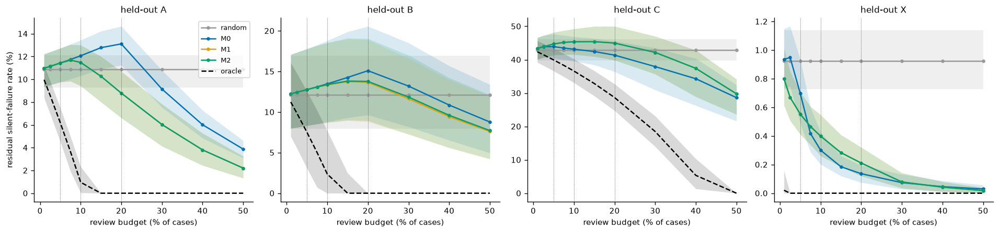

*Figure 6. Residual silent-failure rate among accepted cases vs review budget (exact budget; 95% paired CIs). Dotted lines: the pre-registered budgets 5 / 10 / 20%. PRE-REGISTERED PRIMARY.*  
**What to notice:** on A and B the uncertainty-based curves first RISE above random (the budget is spent on visible, low-confidence errors) and only fall once the low-confidence cases are exhausted; M1 and M2 overlap; the oracle shows how much is achievable.

**Table 3 (referral part) - residual SF rate, residual error rate, SF capture, AURC and contrasts for every family, budget and method (outputs/stage7/table3_referral.csv; rates in %, differences in points)** - 400 rows

heldout,analysis,budget,quantity,metric,prevalence,n_per_seed,p_boot,jackknife_min,jackknife_max,verdict,estimate [95% CI] (% or pt)
A,primary,5.0,M0,resid_sf,0.108608,168000,,,,,"11.43 [9.76, 12.73]"
A,primary,5.0,M0,resid_err,0.108608,168000,,,,,"19.70 [18.43, 21.06]"
A,primary,5.0,M0,capture,0.108608,168000,,,,,"0.00 [0.00, 0.00]"
A,primary,10.0,M0,resid_sf,0.108608,168000,,,,,"12.07 [10.31, 13.44]"
A,primary,10.0,M0,resid_err,0.108608,168000,,,,,"17.47 [15.98, 18.94]"
A,primary,10.0,M0,capture,0.108608,168000,,,,,"0.00 [0.00, 0.00]"
A,primary,20.0,M0,resid_sf,0.108608,168000,,,,,"13.11 [11.24, 14.66]"
A,primary,20.0,M0,resid_err,0.108608,168000,,,,,"13.14 [11.33, 14.76]"
A,primary,20.0,M0,capture,0.108608,168000,,,,,"3.48 [1.80, 6.02]"
A,primary,,M0,aurc,0.108608,168000,,,,,"5.50 [4.76, 6.28]"


**What this shows:** M1-M0: A 10% -0.59 [-0.99, -0.32] pt, 20% -4.32 [-5.15, -3.43] pt; B 20% -1.43 [-2.47, -0.45] pt; C 5/10/20% +0.80 / +2.21 / +3.61 pt (increases). M2-M1 is 0.00 pt on A and C and at most +0.11 pt on B. M0 captures 0.0% of silent failures at 5% on A (oracle 46.1%), while lowering the residual ERROR rate (13.1% vs 22.0% random at 20%).

In [19]:
f6 = rd("stage7/fig6_data.csv")
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
for a_, H in zip(ax, "ABCX"):
    for m in ("random", "M0", "M1", "M2", "oracle"):
        g = f6[(f6.heldout == H) & (f6.quantity == m) & (f6.metric == "resid_sf")].sort_values("budget")
        a_.plot(100 * g.budget, 100 * g.estimate, "--" if m == "oracle" else "-o", ms=3, color=COL[m], label=m)
        a_.fill_between(100 * g.budget, 100 * g.ci_low, 100 * g.ci_high, color=COL[m], alpha=0.15, lw=0)
    for b in (5, 10, 20):
        a_.axvline(b, color="k", lw=0.4, ls=":")
    a_.set_title(f"held-out {H}"); a_.set_xlabel("review budget (% of cases)")
ax[0].set_ylabel("residual silent-failure rate (%)"); ax[0].legend(); plt.tight_layout(); plt.show()
figcap(6, "Residual silent-failure rate among accepted cases vs review budget (exact budget; 95% paired CIs). Dotted lines: the "
          "pre-registered budgets 5 / 10 / 20%. PRE-REGISTERED PRIMARY.",
       "on A and B the uncertainty-based curves first RISE above random (the budget is spent on visible, low-confidence errors) and only fall "
       "once the low-confidence cases are exhausted; M1 and M2 overlap; the oracle shows how much is achievable.")
t3f = fmt(t3, d=2, scale=100, keep=["heldout", "analysis", "budget", "quantity", "metric", "prevalence", "n_per_seed", "p_boot", "jackknife_min", "jackknife_max", "verdict"],
          name="estimate [95% CI] (% or pt)")
t3f["budget"] = (100 * t3f.budget).round(1)
show(t3f, "Table 3 (referral part) - residual SF rate, residual error rate, SF capture, AURC and contrasts for every family, budget and method "
          "(outputs/stage7/table3_referral.csv; rates in %, differences in points)")
say(f"**What this shows:** M1-M0: A 10% {rc(t3r('A','M1-M0','dresid_sf',0.1),2,100)} pt, 20% {rc(t3r('A','M1-M0','dresid_sf',0.2),2,100)} pt; "
    f"B 20% {rc(t3r('B','M1-M0','dresid_sf',0.2),2,100)} pt; C 5/10/20% {t3r('C','M1-M0','dresid_sf',0.05).estimate*100:+.2f} / "
    f"{t3r('C','M1-M0','dresid_sf',0.1).estimate*100:+.2f} / {t3r('C','M1-M0','dresid_sf',0.2).estimate*100:+.2f} pt (increases). M2-M1 is "
    f"0.00 pt on A and C and at most {t3[(t3.quantity=='M2-M1')&(t3.metric=='dresid_sf')&(t3.heldout=='B')].estimate.max()*100:+.2f} pt on B. "
    f"M0 captures {t3r('A','M0','capture',0.05).estimate:.1%} of silent failures at 5% on A (oracle {t3r('A','oracle','capture',0.05).estimate:.1%}), "
    f"while lowering the residual ERROR rate ({t3r('A','M0','resid_err',0.2).estimate:.1%} vs {t3r('A','random','resid_err',0.2).estimate:.1%} random at 20%).")

In [20]:
tiers = rd("stage7/tiers.csv")
show(fmt(tiers, est="sf_share_captured", d=3, keep=["heldout", "analysis", "budget", "quantity", "tier", "workload_share"], name="share of all SF captured [95% CI]"),
     "Accept / review / refer tiers: share of all silent failures in the refer tier (top B/2) and review tier (next B/2) (outputs/stage7/tiers.csv)")
say(f"**What this shows:** at B = 5% the refer tier of M0 on A captures {one(tiers, heldout='A', budget=0.05, quantity='M0', tier='refer (top B/2)').sf_share_captured:.1%} "
    f"of silent failures vs {one(tiers, heldout='A', budget=0.05, quantity='oracle', tier='refer (top B/2)').sf_share_captured:.1%} for the oracle: "
    "the most suspicious cases by uncertainty are not the silent ones. No cost model is used; residual metrics depend only on B.")
ttw = tt[tt.metric == "realised_workload"].copy()
ttw["realised workload [95% CI] (%)"] = [ci(e, l, h, 1, 100) for e, l, h in zip(ttw.estimate, ttw.ci_low, ttw.ci_high)]
ttw["budget"] = (100 * ttw.budget).round(0)
show(ttw[["heldout", "label", "budget", "quantity", "realised workload [95% CI] (%)", "workload_flag"]],
     "Secondary (Blueprint-literal) threshold transfer: realised workload per held-out family, method and budget (outputs/stage7/threshold_transfer.csv)")
show(fmt(tt[tt.metric != "realised_workload"], d=2, scale=100, keep=["heldout", "label", "budget", "quantity", "metric", "random_resid_sf_same_workload", "workload_difference", "workload_matched", "verdict"]),
     "Threshold transfer: residual rates, capture and contrasts at the realised workloads (remaining rows of outputs/stage7/threshold_transfer.csv)")
say(f"**What this shows:** {n_tt} of {N_tt} cells miss the budget by more than 1 point (A: 0-9%, B: about 0%, C: 37-61% for nominal 5-20%). "
    "Score scales do not transfer between families - the same lesson as the Phase 6 FAR failure - which is why the primary protocol ranks within the "
    "deployment pool. Transferred-threshold residual rates are not comparable across methods.")
bt = rd("stage7/boundary_ties.csv")
btm = bt.groupby(["heldout", "method"]).boundary_tie_share.max().round(4).unstack()
show(btm.reset_index(), "Largest share of the pool in a tie group straddling a budget boundary (max over budgets; outputs/stage7/boundary_ties.csv, full in Appendix A)")
say(f"**What this shows:** for the detectors, ties at the boundary involve at most {btm[['M0','M1','M2']].max().max():.2%} of the pool "
    "(random and oracle are tied by construction and handled by the fractional rule).")

**Accept / review / refer tiers: share of all silent failures in the refer tier (top B/2) and review tier (next B/2) (outputs/stage7/tiers.csv)** - 120 rows

heldout,analysis,budget,quantity,tier,workload_share,share of all SF captured [95% CI]
A,primary,0.05,M0,refer (top B/2),0.025,"0.000 [0.000, 0.000]"
A,primary,0.05,M0,review (next B/2),0.025,"0.000 [0.000, 0.000]"
A,primary,0.05,M1,refer (top B/2),0.025,"0.000 [0.000, 0.000]"
A,primary,0.05,M1,review (next B/2),0.025,"0.000 [0.000, 0.000]"
A,primary,0.05,M2,refer (top B/2),0.025,"0.000 [0.000, 0.000]"
A,primary,0.05,M2,review (next B/2),0.025,"0.000 [0.000, 0.000]"
A,primary,0.05,random,refer (top B/2),0.025,"0.025 [0.025, 0.025]"
A,primary,0.05,random,review (next B/2),0.025,"0.025 [0.025, 0.025]"
A,primary,0.05,oracle,refer (top B/2),0.025,"0.231 [0.207, 0.271]"
A,primary,0.05,oracle,review (next B/2),0.025,"0.231 [0.207, 0.271]"


**What this shows:** at B = 5% the refer tier of M0 on A captures 0.0% of silent failures vs 23.1% for the oracle: the most suspicious cases by uncertainty are not the silent ones. No cost model is used; residual metrics depend only on B.

**Secondary (Blueprint-literal) threshold transfer: realised workload per held-out family, method and budget (outputs/stage7/threshold_transfer.csv)** - 36 rows

heldout,label,budget,quantity,realised workload [95% CI] (%),workload_flag
A,sf_090,5.0,M0,"0.0 [0.0, 0.0]",True
A,sf_090,10.0,M0,"0.0 [0.0, 0.0]",True
A,sf_090,20.0,M0,"0.7 [0.0, 2.1]",True
A,sf_090,5.0,M1,"0.1 [0.0, 0.2]",True
A,sf_090,10.0,M1,"0.4 [0.1, 0.7]",True
A,sf_090,20.0,M1,"9.0 [5.9, 12.8]",True
A,sf_090,5.0,M2,"0.1 [0.0, 0.2]",True
A,sf_090,10.0,M2,"0.4 [0.1, 0.7]",True
A,sf_090,20.0,M2,"9.0 [5.9, 12.8]",True
B,sf_090,5.0,M0,"0.0 [0.0, 0.0]",True


...

heldout,label,budget,quantity,metric,random_resid_sf_same_workload,workload_difference,workload_matched,verdict,estimate [95% CI]
A,sf_090,0.05,M0,resid_sf,0.108608,,,,"10.86 [9.28, 12.10]"
A,sf_090,0.05,M0,resid_err,0.108608,,,,"21.97 [20.64, 23.39]"
A,sf_090,0.05,M0,capture,0.108608,,,,"0.00 [0.00, 0.00]"
A,sf_090,0.10,M0,resid_sf,0.108608,,,,"10.86 [9.28, 12.10]"
A,sf_090,0.10,M0,resid_err,0.108608,,,,"21.97 [20.64, 23.39]"
A,sf_090,0.10,M0,capture,0.108608,,,,"0.00 [0.00, 0.00]"
A,sf_090,0.20,M0,resid_sf,0.108608,,,,"10.94 [9.30, 12.22]"
A,sf_090,0.20,M0,resid_err,0.108608,,,,"21.64 [20.33, 23.05]"
A,sf_090,0.20,M0,capture,0.108608,,,,"0.00 [0.00, 0.00]"
A,sf_090,0.05,M1,resid_sf,0.108608,,,,"10.87 [9.29, 12.12]"


**What this shows:** 36 of 36 cells miss the budget by more than 1 point (A: 0-9%, B: about 0%, C: 37-61% for nominal 5-20%). Score scales do not transfer between families - the same lesson as the Phase 6 FAR failure - which is why the primary protocol ranks within the deployment pool. Transferred-threshold residual rates are not comparable across methods.

**Largest share of the pool in a tie group straddling a budget boundary (max over budgets; outputs/stage7/boundary_ties.csv, full in Appendix A)** - 4 rows

method,heldout,M0,M1,M2,oracle,random
,A,0.0063,0.0001,0.0001,0.8914,1.0
,B,0.0014,0.0006,0.0000,0.8788,1.0
,C,0.0365,0.0003,0.0003,0.5706,1.0
,X,0.0004,0.0000,0.0000,0.9907,1.0


**What this shows:** for the detectors, ties at the boundary involve at most 3.65% of the pool (random and oracle are tied by construction and handled by the fractional rule).

<a id="s9"></a>
## 9. Ablations and sensitivity (Phase 8; plan `docs/ablation_plan_frozen.md`, commit f0553df)
Primary endpoint: residual silent-failure rate (`sf_090`) at exact budgets 5 / 10 / 20%; secondary: AUROC / AUPRC / AURC. Declared
primary contrasts (unadjusted): **P1** sign-free M1 - sign-free M0, **P2** sign-free M2 - sign-free M1, **P3** sign-free M1 - non-negative
M1. All other contrasts are SECONDARY with BH-FDR inside each group (`q_bh`). For each group the main text shows the **contrast rows**
(residual rate and AUROC); the complete table (levels and all metrics) is in Appendix A.

In [21]:
def ab_contrasts(g, extra=None):
    d = G[g]; d = d[(d.kind == "contrast") & d.metric.isin(["dresid_sf", "dauroc"])]
    if extra is not None:
        d = d[extra(d)]
    o = fmt(d, d=2, scale=1, keep=["heldout", "label", "c_kind", "level_col", "level", "quantity", "budget", "metric", "primary", "p_boot", "q_bh", "jackknife_min", "jackknife_max", "verdict"])
    m = o.metric == "dresid_sf"
    o.loc[m, "estimate [95% CI]"] = [ci(e, l, h, 2, 100, True) for e, l, h in zip(d.estimate[m.values], d.ci_low[m.values], d.ci_high[m.values])]
    o.loc[~m, "estimate [95% CI]"] = [ci(e, l, h, 3, 1, True) for e, l, h in zip(d.estimate[~m.values], d.ci_low[~m.values], d.ci_high[~m.values])]
    o["budget"] = (100 * o.budget).round(0)
    return o
def vc(g, q):
    d = G[g]; d = d[(d.kind == "contrast") & (d.metric == "dresid_sf") & d.quantity.isin(q)]
    return ", ".join(f"{k}: {v}" for k, v in d.verdict.value_counts().items())
names = {"G1": "signal groups", "G2": "fusion constraint (contains P1-P3)", "G3": "CAM layer / form", "G4": "Mahalanobis vs kNN",
         "G5": "reference size", "G6": "temperature scaling", "G7": "family A severity and corruption", "G8": "family C cue state (v2, v1)", "G9": "label variants"}

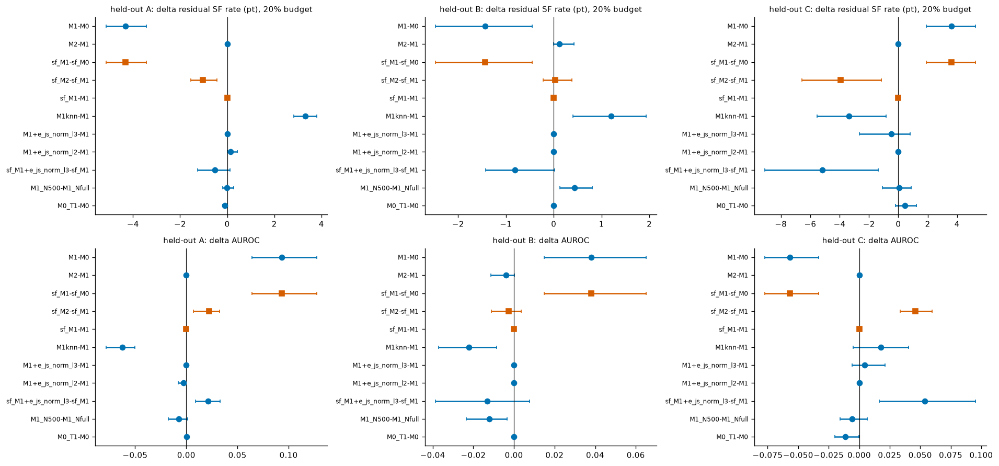

*Figure 8a. Incremental effect of each ablation (variant - reference), held-out family, 95% paired CIs; red squares = declared primary contrasts P1-P3, blue = secondary. Negative residual deltas and positive AUROC deltas are improvements.*  
**What to notice:** the only primary contrast that changes the picture is P2 (sign-free CAM drift); allowing a free sign changes nothing for M0 / M1 (P3 = 0).

In [22]:
# ---- Figure 8a: incremental deltas by ablation (regenerated from the saved tables)
sel = [("G1", "M1-M0"), ("G1", "M2-M1"), ("G2", "sf_M1-sf_M0"), ("G2", "sf_M2-sf_M1"), ("G2", "sf_M1-M1"), ("G4", "M1knn-M1"),
       ("G3", "M1+e_js_norm_l3-M1"), ("G3", "M1+e_js_norm_l2-M1"), ("G3", "sf_M1+e_js_norm_l3-sf_M1"), ("G5", "M1_N500-M1_Nfull"), ("G6", "M0_T1-M0")]
fig, ax = plt.subplots(2, 3, figsize=(16, 7.5))
for j, H in enumerate("ABC"):
    for row_, (met, bud, s, ttl) in enumerate((("dresid_sf", 0.2, 100, "delta residual SF rate (pt), 20% budget"), ("dauroc", None, 1, "delta AUROC"))):
        for i, (g, q) in enumerate(sel):
            d = G[g]; d = d[(d.kind == "contrast") & d.level_col.isna() & (d.heldout == H) & (d.quantity == q) & (d.metric == met)]
            if bud is not None:
                d = d[np.isclose(d.budget, bud)]
            if len(d):
                r = d.iloc[0]; prim = q in ("sf_M1-sf_M0", "sf_M2-sf_M1", "sf_M1-M1")
                ax[row_, j].errorbar(s * r.estimate, i, xerr=[[s * (r.estimate - r.ci_low)], [s * (r.ci_high - r.estimate)]], fmt="s" if prim else "o",
                                     color=OI["vermillion"] if prim else OI["blue"], capsize=2)
        ax[row_, j].axvline(0, color="k", lw=0.7); ax[row_, j].set_yticks(range(len(sel))); ax[row_, j].set_yticklabels([q for _, q in sel], fontsize=7)
        ax[row_, j].invert_yaxis(); ax[row_, j].set_title(f"held-out {H}: {ttl}", fontsize=9)
plt.tight_layout(); plt.show()
figcap("8a", "Incremental effect of each ablation (variant - reference), held-out family, 95% paired CIs; red squares = declared primary "
             "contrasts P1-P3, blue = secondary. Negative residual deltas and positive AUROC deltas are improvements.",
       "the only primary contrast that changes the picture is P2 (sign-free CAM drift); allowing a free sign changes nothing for M0 / M1 (P3 = 0).")

In [23]:
for g in ("G1", "G2", "G3", "G4", "G5", "G6"):
    show(ab_contrasts(g, lambda d: d.level_col.isna()), f"Ablation {g} - {names[g]}: contrast rows (residual SF in pt; AUROC) (outputs/stage8/tables/ablation_{g}.csv)")
    if g == "G1":
        say(f"**What this shows (G1, SECONDARY):** Mahalanobis alone beats log(1-MSP) alone at 20% on A ({rc(g8('A','s_r_maha_pred-s_u_log1msp',0.2,g='G1'),2,100)} pt) and B "
            f"({rc(g8('B','s_r_maha_pred-s_u_log1msp',0.2,g='G1'),2,100)} pt) but not on C ({rc(g8('C','s_r_maha_pred-s_u_log1msp',0.2,g='G1'),2,100)} pt); adding CAM to M0 "
            f"under the non-negative fusion changes nothing on A ({rc(g8('A','M0c-M0',0.2,g='G1'),2,100)} pt). Verdicts: {vc('G1', ['M1-M0','M0c-M0','M2-M1'])}.")
    if g == "G2":
        say(f"**What this shows (G2, contains the PRE-REGISTERED PRIMARY P1-P3):** P3 sf-M1 - M1 = 0.00 pt everywhere (A 20% {rc(g8('A','sf_M1-M1',0.2),2,100)}): "
            f"the optimal uncertainty and Mahalanobis weights are already non-negative, so P1 equals the Phase 7 M1-M0 result "
            f"(A 20% {rc(g8('A','sf_M1-sf_M0',0.2),2,100)}, C 20% {rc(g8('C','sf_M1-sf_M0',0.2),2,100)} pt). **P2 sf-M2 - sf-M1 reduces residual silent failures** on A "
            f"({rc(g8('A','sf_M2-sf_M1',0.05),2,100)} / {rc(g8('A','sf_M2-sf_M1',0.1),2,100)} / {rc(g8('A','sf_M2-sf_M1',0.2),2,100)} pt at 5/10/20%) and C "
            f"({rc(g8('C','sf_M2-sf_M1',0.05),2,100)} / {rc(g8('C','sf_M2-sf_M1',0.1),2,100)} / {rc(g8('C','sf_M2-sf_M1',0.2),2,100)} pt), not on B "
            f"({rc(g8('B','sf_M2-sf_M1',0.2),2,100)} pt at 20%). The fitted CAM weight is negative: confident errors have typical explanations. "
            "Conclusion: a non-negative detector is adequate for uncertainty and representation drift, but not for explanation drift.")
    if g == "G3":
        say(f"**What this shows (G3, SECONDARY):** under non-negative fusion no CAM variant helps; under sign-free fusion layer3 and layer2 CAM also reduce residual "
            f"silent failures on C (layer2 20% {rc(g8('C','sf_M1+e_js_norm_l2-sf_M1',0.2,g='G3'),2,100)} pt) and A at 5-10% (layer3 10% "
            f"{rc(g8('A','sf_M1+e_js_norm_l3-sf_M1',0.1,g='G3'),2,100)} pt). The sign of the weight matters more than the layer or the map distance used.")
    if g == "G4":
        say(f"**What this shows (G4, SECONDARY):** kNN is worse than Mahalanobis on A ({rc(g8('A','M1knn-M1',0.2,g='G4'),2,100)} pt at 20%) and B "
            f"({rc(g8('B','M1knn-M1',0.2,g='G4'),2,100)} pt) and better on C ({rc(g8('C','M1knn-M1',0.2,g='G4'),2,100)} pt): the pre-registered Mahalanobis is "
            "the better choice where representation drift helps at all.")
    if g == "G5":
        say(f"**What this shows (G5, SECONDARY):** a Mahalanobis reference of 500 training images is nearly as good as the full saved bank (A 20% "
            f"{rc(g8('A','M1_N500-M1_Nfull',0.2,g='G5'),2,100)} pt; B 20% {rc(g8('B','M1_N500-M1_Nfull',0.2,g='G5'),2,100)} pt, slightly worse); the full-bank "
            f"refit reproduces the stored Phase 4 reference ({rc(g8('A','M1_Nfull-M1',0.2,g='G5'),2,100)} pt). 'Full' = the saved bank (20,000 / 40,000 images), not the whole training set.")
    if g == "G6":
        say(f"**What this shows (G6, SECONDARY):** temperature scaling barely changes the ranking: before - after = {rc(g8('A','M0_T1-M0',0.2,g='G6'),2,100)} pt (A), "
            f"{rc(g8('B','M0_T1-M0',0.2,g='G6'),2,100)} pt (B), {rc(g8('C','M0_T1-M0',0.2,g='G6'),2,100)} pt (C) at 20% for M0. Calibration matters for the "
            "*label* (which errors count as silent), not for the ranking.")

**Ablation G1 - signal groups: contrast rows (residual SF in pt; AUROC) (outputs/stage8/tables/ablation_G1.csv)** - 84 rows

heldout,label,c_kind,level_col,level,quantity,budget,metric,primary,p_boot,q_bh,jackknife_min,jackknife_max,verdict,estimate [95% CI]
A,sf_090,shortcutv2,,,M1-M0,5.0,dresid_sf,False,1.000,1.000000,0.000000,0.000000,no practical difference,"+0.00 [-0.00, +0.00]"
A,sf_090,shortcutv2,,,M1-M0,10.0,dresid_sf,False,0.000,0.000000,-0.006192,-0.005451,reduces,"-0.59 [-0.99, -0.32]"
A,sf_090,shortcutv2,,,M1-M0,20.0,dresid_sf,False,0.000,0.000000,-0.044693,-0.041725,reduces,"-4.32 [-5.15, -3.43]"
A,sf_090,shortcutv2,,,M1-M0,,dauroc,False,0.000,,0.087398,0.098430,improves,"+0.093 [+0.064, +0.127]"
A,sf_090,shortcutv2,,,M0c-M0,5.0,dresid_sf,False,1.000,1.000000,0.000000,0.000000,no practical difference,"+0.00 [+0.00, +0.00]"
A,sf_090,shortcutv2,,,M0c-M0,10.0,dresid_sf,False,1.000,1.000000,0.000000,0.000000,no practical difference,"+0.00 [+0.00, +0.00]"
A,sf_090,shortcutv2,,,M0c-M0,20.0,dresid_sf,False,1.000,1.000000,0.000000,0.000000,no practical difference,"+0.00 [+0.00, +0.00]"
A,sf_090,shortcutv2,,,M0c-M0,,dauroc,False,1.000,,0.000000,0.000000,no practical difference,"+0.000 [+0.000, +0.000]"
A,sf_090,shortcutv2,,,M2-M1,5.0,dresid_sf,False,1.000,1.000000,0.000000,0.000000,no practical difference,"+0.00 [+0.00, +0.00]"
A,sf_090,shortcutv2,,,M2-M1,10.0,dresid_sf,False,0.683,1.000000,0.000000,0.000002,no practical difference,"+0.00 [+0.00, +0.00]"


**What this shows (G1, SECONDARY):** Mahalanobis alone beats log(1-MSP) alone at 20% on A (-5.46 [-6.23, -4.59] pt) and B (-2.97 [-5.42, -1.11] pt) but not on C (+3.79 [+2.13, +5.72] pt); adding CAM to M0 under the non-negative fusion changes nothing on A (+0.00 [+0.00, +0.00] pt). Verdicts: no practical difference: 15, inconclusive: 6, reduces: 3, increases: 3.

**Ablation G2 - fusion constraint (contains P1-P3): contrast rows (residual SF in pt; AUROC) (outputs/stage8/tables/ablation_G2.csv)** - 60 rows

heldout,label,c_kind,level_col,level,quantity,budget,metric,primary,p_boot,q_bh,jackknife_min,jackknife_max,verdict,estimate [95% CI]
A,sf_090,shortcutv2,,,sf_M0-M0,5.0,dresid_sf,False,1.000,1.000000,0.000000e+00,0.000000e+00,no practical difference,"+0.00 [+0.00, +0.00]"
A,sf_090,shortcutv2,,,sf_M0-M0,10.0,dresid_sf,False,1.000,1.000000,0.000000e+00,0.000000e+00,no practical difference,"+0.00 [+0.00, +0.00]"
A,sf_090,shortcutv2,,,sf_M0-M0,20.0,dresid_sf,False,1.000,1.000000,0.000000e+00,0.000000e+00,no practical difference,"+0.00 [+0.00, +0.00]"
A,sf_090,shortcutv2,,,sf_M0-M0,,dauroc,False,1.000,,0.000000e+00,0.000000e+00,no practical difference,"+0.000 [+0.000, +0.000]"
A,sf_090,shortcutv2,,,sf_M1-M1,5.0,dresid_sf,True,1.000,,0.000000e+00,0.000000e+00,no practical difference,"+0.00 [+0.00, +0.00]"
A,sf_090,shortcutv2,,,sf_M1-M1,10.0,dresid_sf,True,1.000,,0.000000e+00,1.653439e-06,no practical difference,"+0.00 [-0.00, +0.00]"
A,sf_090,shortcutv2,,,sf_M1-M1,20.0,dresid_sf,True,0.963,,1.860119e-06,3.720238e-06,no practical difference,"+0.00 [-0.00, +0.00]"
A,sf_090,shortcutv2,,,sf_M1-M1,,dauroc,True,0.159,,-5.870508e-06,-1.573682e-06,no practical difference,"-0.000 [-0.000, +0.000]"
A,sf_090,shortcutv2,,,sf_M2-M2,5.0,dresid_sf,False,0.000,0.000000,-1.308584e-02,-1.210526e-02,reduces,"-1.25 [-1.42, -1.01]"
A,sf_090,shortcutv2,,,sf_M2-M2,10.0,dresid_sf,False,0.000,0.000000,-2.116733e-02,-1.959160e-02,reduces,"-2.05 [-2.46, -1.44]"


...

heldout,label,c_kind,level_col,level,quantity,budget,metric,primary,p_boot,q_bh,jackknife_min,jackknife_max,verdict,estimate [95% CI]
A,sf_090,shortcutv2,,,M1_N500-M1_Nfull,5.0,dresid_sf,False,0.103,0.218118,-1.284461e-04,-1.096491e-05,no practical difference,"-0.01 [-0.07, +0.00]"
A,sf_090,shortcutv2,,,M1_N500-M1_Nfull,10.0,dresid_sf,False,0.001,0.003273,-3.680556e-03,-2.723214e-03,reduces,"-0.33 [-0.49, -0.13]"
A,sf_090,shortcutv2,,,M1_N500-M1_Nfull,20.0,dresid_sf,False,0.795,1.000000,-5.989583e-04,3.720238e-04,no practical difference,"-0.01 [-0.20, +0.28]"
A,sf_090,shortcutv2,,,M1_N500-M1_Nfull,,dauroc,False,0.217,,-8.831321e-03,-6.923050e-03,inconclusive,"-0.007 [-0.018, +0.001]"
A,sf_090,shortcutv2,,,M1_N1000-M1_Nfull,5.0,dresid_sf,False,0.814,1.000000,-7.832080e-06,0.000000e+00,no practical difference,"-0.00 [-0.01, +0.00]"
A,sf_090,shortcutv2,,,M1_N1000-M1_Nfull,10.0,dresid_sf,False,0.010,0.025714,-1.908069e-03,-1.448413e-03,reduces,"-0.16 [-0.22, -0.05]"
A,sf_090,shortcutv2,,,M1_N1000-M1_Nfull,20.0,dresid_sf,False,0.686,1.000000,1.822917e-04,1.158854e-03,no practical difference,"+0.08 [-0.08, +0.27]"
A,sf_090,shortcutv2,,,M1_N1000-M1_Nfull,,dauroc,False,0.424,,-5.498593e-03,-4.292712e-03,no practical difference,"-0.005 [-0.012, +0.001]"
A,sf_090,shortcutv2,,,M1_N2000-M1_Nfull,5.0,dresid_sf,False,1.000,1.000000,0.000000e+00,0.000000e+00,no practical difference,"+0.00 [-0.00, +0.00]"
A,sf_090,shortcutv2,,,M1_N2000-M1_Nfull,10.0,dresid_sf,False,0.031,0.072000,-1.442350e-03,-9.016755e-04,reduces,"-0.11 [-0.17, -0.02]"


**What this shows (G5, SECONDARY):** a Mahalanobis reference of 500 training images is nearly as good as the full saved bank (A 20% -0.01 [-0.20, +0.28] pt; B 20% +0.43 [+0.13, +0.81] pt, slightly worse); the full-bank refit reproduces the stored Phase 4 reference (+0.00 [+0.00, +0.00] pt). 'Full' = the saved bank (20,000 / 40,000 images), not the whole training set.

**Ablation G6 - temperature scaling: contrast rows (residual SF in pt; AUROC) (outputs/stage8/tables/ablation_G6.csv)** - 24 rows

heldout,label,c_kind,level_col,level,quantity,budget,metric,primary,p_boot,q_bh,jackknife_min,jackknife_max,verdict,estimate [95% CI]
A,sf_090,shortcutv2,,,M0_T1-M0,5.0,dresid_sf,False,1.000,1.000000,0.000000e+00,0.000000e+00,no practical difference,"+0.00 [+0.00, +0.00]"
A,sf_090,shortcutv2,,,M0_T1-M0,10.0,dresid_sf,False,1.000,1.000000,0.000000e+00,0.000000e+00,no practical difference,"+0.00 [+0.00, +0.00]"
A,sf_090,shortcutv2,,,M0_T1-M0,20.0,dresid_sf,False,0.000,0.000000,-1.266234e-03,-9.244642e-04,reduces,"-0.11 [-0.18, -0.02]"
A,sf_090,shortcutv2,,,M0_T1-M0,,dauroc,False,0.471,,1.238543e-04,2.624562e-04,no practical difference,"+0.000 [-0.000, +0.001]"
A,sf_090,shortcutv2,,,M1_T1-M1,5.0,dresid_sf,False,1.000,1.000000,0.000000e+00,0.000000e+00,no practical difference,"+0.00 [-0.01, +0.00]"
A,sf_090,shortcutv2,,,M1_T1-M1,10.0,dresid_sf,False,0.000,0.000000,-5.692555e-04,-4.728836e-04,no practical difference,"-0.05 [-0.07, -0.04]"
A,sf_090,shortcutv2,,,M1_T1-M1,20.0,dresid_sf,False,0.000,0.000000,-1.017485e-03,-8.426339e-04,no practical difference,"-0.09 [-0.12, -0.06]"
A,sf_090,shortcutv2,,,M1_T1-M1,,dauroc,False,0.000,,1.794309e-03,2.221482e-03,no practical difference,"+0.002 [+0.002, +0.003]"
B,sf_090,shortcutv2,,,M0_T1-M0,5.0,dresid_sf,False,1.000,1.000000,0.000000e+00,0.000000e+00,no practical difference,"+0.00 [+0.00, +0.00]"
B,sf_090,shortcutv2,,,M0_T1-M0,10.0,dresid_sf,False,1.000,1.000000,0.000000e+00,0.000000e+00,no practical difference,"+0.00 [+0.00, +0.00]"


**What this shows (G6, SECONDARY):** temperature scaling barely changes the ranking: before - after = -0.11 [-0.18, -0.02] pt (A), +0.00 [-0.00, +0.00] pt (B), +0.45 [-0.20, +1.23] pt (C) at 20% for M0. Calibration matters for the *label* (which errors count as silent), not for the ranking.

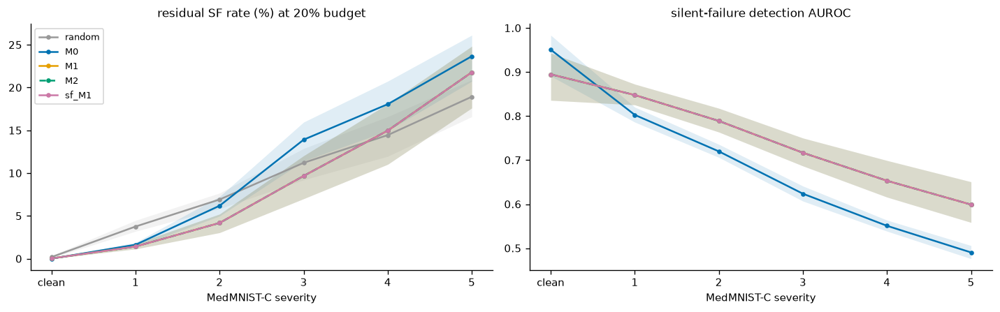

*Figure 8b. Family A by severity: residual silent-failure rate at a 20% budget (left) and detection AUROC (right) for M0, M1, M2 (dashed, identical to M1) and sign-free M1, policy re-applied inside each severity; 95% CIs. SECONDARY.*  
**What to notice:** M0's AUROC falls from 0.95 (clean) to 0.49 (severity 5), M1 degrades more slowly (0.89 to 0.60); at severity 5 both leave more residual silent failures than random review (23.7% / 21.8% vs 18.9%).

**Ablation G7 - family A by severity and corruption: contrast rows (outputs/stage8/tables/ablation_G7.csv)** - 216 rows

heldout,label,c_kind,level_col,level,quantity,budget,metric,primary,p_boot,q_bh,jackknife_min,jackknife_max,verdict,estimate [95% CI]
A,sf_090,shortcutv2,condition,brightness_down,M1-M0,5.0,dresid_sf,False,1.000,1.000000,0.000000e+00,0.000000e+00,no practical difference,"+0.00 [+0.00, +0.00]"
A,sf_090,shortcutv2,condition,brightness_down,M1-M0,10.0,dresid_sf,False,1.000,1.000000,0.000000e+00,0.000000e+00,no practical difference,"+0.00 [+0.00, +0.00]"
A,sf_090,shortcutv2,condition,brightness_down,M1-M0,20.0,dresid_sf,False,0.002,0.016200,-4.138889e-03,-3.263889e-03,reduces,"-0.38 [-1.19, -0.17]"
A,sf_090,shortcutv2,condition,brightness_down,M1-M0,,dauroc,False,0.000,,1.015827e-01,1.173393e-01,improves,"+0.112 [+0.074, +0.173]"
A,sf_090,shortcutv2,condition,brightness_down,M2-M1,5.0,dresid_sf,False,1.000,1.000000,0.000000e+00,0.000000e+00,no practical difference,"+0.00 [+0.00, +0.00]"
A,sf_090,shortcutv2,condition,brightness_down,M2-M1,10.0,dresid_sf,False,1.000,1.000000,0.000000e+00,0.000000e+00,no practical difference,"+0.00 [+0.00, +0.00]"
A,sf_090,shortcutv2,condition,brightness_down,M2-M1,20.0,dresid_sf,False,1.000,1.000000,0.000000e+00,3.472222e-05,no practical difference,"+0.00 [+0.00, +0.01]"
A,sf_090,shortcutv2,condition,brightness_down,M2-M1,,dauroc,False,0.022,,-2.060973e-05,-1.030845e-05,no practical difference,"-0.000 [-0.000, -0.000]"
A,sf_090,shortcutv2,condition,brightness_down,sf_M1-M1,5.0,dresid_sf,False,1.000,1.000000,0.000000e+00,0.000000e+00,no practical difference,"+0.00 [+0.00, +0.00]"
A,sf_090,shortcutv2,condition,brightness_down,sf_M1-M1,10.0,dresid_sf,False,1.000,1.000000,0.000000e+00,0.000000e+00,no practical difference,"+0.00 [+0.00, +0.00]"


**What this shows (G7, SECONDARY):** at 20% M1-M0 reduces residual silent failures for 8 of 11 corruption types (largest: saturate -4.3 pt, contrast_down -4.2 pt, motion_blur -4.0 pt); M2-M1 and sign-free M1 - M1 are 0 at every level.

In [24]:
# ---- G7: family A severity and corruption, Figure 8b
d7 = G["G7"]
def lvl(d, col, v, q, met, b=None):
    r = d[(d.kind == "level") & (d.level_col == col) & (d.level.astype(str) == str(v)) & (d.quantity == q) & (d.metric == met)]
    if b is not None:
        r = r[np.isclose(r.budget, b)]
    return r.iloc[0] if len(r) else None
sev = ["0", "1", "2", "3", "4", "5"]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for q in ("random", "M0", "M1", "M2", "sf_M1"):
    for a_, (met, b, s) in zip(ax, (("resid_sf", 0.2, 100), ("auroc", None, 1))):
        if met == "auroc" and q == "random":
            continue
        rr = [lvl(d7, "severity", v, q, met, b) for v in sev]
        y = np.array([r.estimate for r in rr]); lo = np.array([r.ci_low for r in rr]); hi = np.array([r.ci_high for r in rr])
        a_.plot(range(6), s * y, "-o", ms=3, color=COL[q], label=q, ls="--" if q == "M2" else "-")
        a_.fill_between(range(6), s * lo, s * hi, color=COL[q], alpha=0.12, lw=0)
ax[0].set_title("residual SF rate (%) at 20% budget"); ax[1].set_title("silent-failure detection AUROC")
for a_ in ax:
    a_.set_xticks(range(6)); a_.set_xticklabels(["clean"] + sev[1:]); a_.set_xlabel("MedMNIST-C severity")
ax[0].legend(); plt.tight_layout(); plt.show()
m0_5, m1_5, rnd_5 = (lvl(d7, "severity", 5, q, "resid_sf", 0.2) for q in ("M0", "M1", "random"))
figcap("8b", "Family A by severity: residual silent-failure rate at a 20% budget (left) and detection AUROC (right) for M0, M1, M2 (dashed, "
             "identical to M1) and sign-free M1, policy re-applied inside each severity; 95% CIs. SECONDARY.",
       f"M0's AUROC falls from {lvl(d7,'severity',0,'M0','auroc').estimate:.2f} (clean) to {lvl(d7,'severity',5,'M0','auroc').estimate:.2f} (severity 5), "
       f"M1 degrades more slowly ({lvl(d7,'severity',0,'M1','auroc').estimate:.2f} to {lvl(d7,'severity',5,'M1','auroc').estimate:.2f}); at severity 5 both "
       f"leave more residual silent failures than random review ({100*m0_5.estimate:.1f}% / {100*m1_5.estimate:.1f}% vs {100*rnd_5.estimate:.1f}%).")
show(ab_contrasts("G7"), "Ablation G7 - family A by severity and corruption: contrast rows (outputs/stage8/tables/ablation_G7.csv)")
v7 = d7[(d7.kind == "contrast") & (d7.metric == "dresid_sf") & (d7.quantity == "M1-M0") & np.isclose(d7.budget, 0.2) & (d7.level_col == "condition")]
say(f"**What this shows (G7, SECONDARY):** at 20% M1-M0 reduces residual silent failures for {int((v7.verdict == 'reduces').sum())} of "
    f"{int((v7.level != 'clean').sum())} corruption types (largest: {', '.join(f'{r.level} {100*r.estimate:+.1f} pt' for r in v7.nsmallest(3, 'estimate').itertuples())}); "
    "M2-M1 and sign-free M1 - M1 are 0 at every level.")

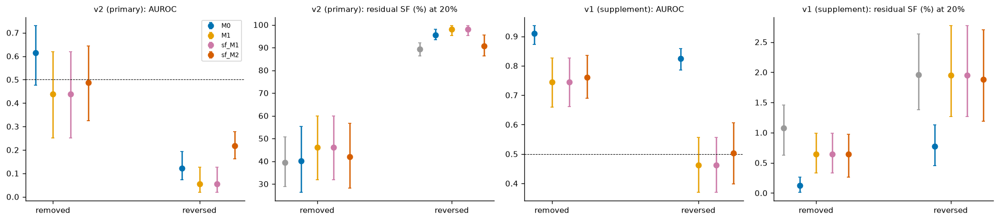

*Figure 8c. Family C by cue state (aligned has no silent failures and is omitted): detection AUROC and residual silent-failure rate at 20% for v2 and v1, 95% CIs. SECONDARY.*  
**What to notice:** with the strong cue (v2) reversed, every monitor is inverted (M0 AUROC 0.122, M1 0.056); sign-free M2 partly repairs it (0.218). With the weak cue (v1) M0 works well (removed AUROC 0.910) and M1 is worse.

**Ablation G8 - family C by cue state, v2 and v1: contrast rows (outputs/stage8/tables/ablation_G8.csv)** - 104 rows

heldout,label,c_kind,level_col,level,quantity,budget,metric,primary,p_boot,q_bh,jackknife_min,jackknife_max,verdict,estimate [95% CI]
C,sf_090,shortcutv2,condition,aligned,M1-M0,5.0,dresid_sf,False,1.000,1.000000,0.000000e+00,0.000000e+00,no practical difference,"+0.00 [+0.00, +0.00]"
C,sf_090,shortcutv2,condition,aligned,M1-M0,10.0,dresid_sf,False,1.000,1.000000,0.000000e+00,0.000000e+00,no practical difference,"+0.00 [+0.00, +0.00]"
C,sf_090,shortcutv2,condition,aligned,M1-M0,20.0,dresid_sf,False,1.000,1.000000,0.000000e+00,0.000000e+00,no practical difference,"+0.00 [+0.00, +0.00]"
C,sf_090,shortcutv2,condition,aligned,M2-M1,5.0,dresid_sf,False,1.000,1.000000,0.000000e+00,0.000000e+00,no practical difference,"+0.00 [+0.00, +0.00]"
C,sf_090,shortcutv2,condition,aligned,M2-M1,10.0,dresid_sf,False,1.000,1.000000,0.000000e+00,0.000000e+00,no practical difference,"+0.00 [+0.00, +0.00]"
C,sf_090,shortcutv2,condition,aligned,M2-M1,20.0,dresid_sf,False,1.000,1.000000,0.000000e+00,0.000000e+00,no practical difference,"+0.00 [+0.00, +0.00]"
C,sf_090,shortcutv2,condition,aligned,sf_M1-M0,5.0,dresid_sf,False,1.000,1.000000,0.000000e+00,0.000000e+00,no practical difference,"+0.00 [+0.00, +0.00]"
C,sf_090,shortcutv2,condition,aligned,sf_M1-M0,10.0,dresid_sf,False,1.000,1.000000,0.000000e+00,0.000000e+00,no practical difference,"+0.00 [+0.00, +0.00]"
C,sf_090,shortcutv2,condition,aligned,sf_M1-M0,20.0,dresid_sf,False,1.000,1.000000,0.000000e+00,0.000000e+00,no practical difference,"+0.00 [+0.00, +0.00]"
C,sf_090,shortcutv2,condition,aligned,sf_M2-sf_M1,5.0,dresid_sf,False,1.000,1.000000,0.000000e+00,0.000000e+00,no practical difference,"+0.00 [+0.00, +0.00]"


**What this shows (G8, SECONDARY):** the shortcut hurts every monitor that relies on typicality; the damage is largest when the cue dominates the decision (v2), and adding representation drift makes it worse in both cue states.

**Ablation G9 - label variants sf_090 / sf_095 / sf_tau / sf_099: contrast rows (outputs/stage8/tables/ablation_G9.csv)** - 144 rows

heldout,label,c_kind,level_col,level,quantity,budget,metric,primary,p_boot,q_bh,jackknife_min,jackknife_max,verdict,estimate [95% CI]
A,sf_090,shortcutv2,,,M1-M0,5.0,dresid_sf,False,1.000,1.000000,0.000000e+00,0.000000e+00,no practical difference,"+0.00 [-0.00, +0.00]"
A,sf_090,shortcutv2,,,M1-M0,10.0,dresid_sf,False,0.000,0.000000,-6.192130e-03,-5.451389e-03,reduces,"-0.59 [-0.99, -0.32]"
A,sf_090,shortcutv2,,,M1-M0,20.0,dresid_sf,False,0.000,0.000000,-4.469283e-02,-4.172453e-02,reduces,"-4.32 [-5.15, -3.43]"
A,sf_090,shortcutv2,,,M1-M0,,dauroc,False,0.000,,8.739796e-02,9.843047e-02,improves,"+0.093 [+0.064, +0.127]"
A,sf_090,shortcutv2,,,M2-M1,5.0,dresid_sf,False,1.000,1.000000,0.000000e+00,0.000000e+00,no practical difference,"+0.00 [+0.00, +0.00]"
A,sf_090,shortcutv2,,,M2-M1,10.0,dresid_sf,False,0.683,1.000000,0.000000e+00,1.653439e-06,no practical difference,"+0.00 [+0.00, +0.00]"
A,sf_090,shortcutv2,,,M2-M1,20.0,dresid_sf,False,0.676,1.000000,0.000000e+00,1.860119e-06,no practical difference,"+0.00 [-0.00, +0.00]"
A,sf_090,shortcutv2,,,M2-M1,,dauroc,False,0.022,,-1.051037e-05,-5.378652e-06,no practical difference,"-0.000 [-0.000, -0.000]"
A,sf_090,shortcutv2,,,sf_M1-M0,5.0,dresid_sf,False,1.000,1.000000,0.000000e+00,0.000000e+00,no practical difference,"+0.00 [-0.00, +0.00]"
A,sf_090,shortcutv2,,,sf_M1-M0,10.0,dresid_sf,False,0.000,0.000000,-6.192130e-03,-5.449735e-03,reduces,"-0.59 [-0.99, -0.32]"


**What this shows (G9, SECONDARY):** the M1-M0 pattern holds for sf_095 (A -2.89 [-3.49, -2.37] pt, C +3.26 [+1.57, +5.16] pt at 20%) and shrinks with the degenerate labels (A sf_tau -0.43 [-1.13, -0.02] pt, sf_099 -0.41 [-1.24, +0.28] pt); M2-M1 is 0 for every label.

**G10 seed jackknife of the primary contrasts P1-P3 (filtered view of outputs/stage8/tables/seed_jackknife_G10.csv; full in Appendix A)** - 36 rows

group,heldout,quantity,budget,metric,estimate,jackknife_min,jackknife_max,sign flips
G2,A,sf_M1-M1,0.05,dresid_sf,0.00000,0.00000,0.00000,False
G2,A,sf_M1-M1,0.10,dresid_sf,0.00000,0.00000,0.00000,False
G2,A,sf_M1-M1,0.20,dresid_sf,0.00000,0.00000,0.00000,False
G2,A,sf_M1-sf_M0,0.05,dresid_sf,0.00000,0.00000,0.00000,False
G2,A,sf_M1-sf_M0,0.10,dresid_sf,-0.00587,-0.00619,-0.00545,False
G2,A,sf_M1-sf_M0,0.20,dresid_sf,-0.04323,-0.04469,-0.04172,False
G2,A,sf_M2-sf_M1,0.05,dresid_sf,-0.01251,-0.01309,-0.01211,False
G2,A,sf_M2-sf_M1,0.10,dresid_sf,-0.02054,-0.02117,-0.01959,False
G2,A,sf_M2-sf_M1,0.20,dresid_sf,-0.01026,-0.01114,-0.00935,False
E,A,sf_M1-M1,0.05,dresid_sf,0.00000,0.00000,0.00000,False


**What this shows:** leaving out any one seed changes the sign of 0 of 36 primary contrasts with |d| >= 0.1 pt.

In [25]:
# ---- G8: family C cue states, Figure 8c (also used in Section 11)
d8 = G["G8"]
def lv8(ck, st, q, met, b=None):
    r = d8[(d8.kind == "level") & (d8.c_kind == ck) & (d8.level.astype(str) == st) & (d8.quantity == q) & (d8.metric == met)]
    if b is not None:
        r = r[np.isclose(r.budget, b)]
    return r.iloc[0] if len(r) else None
def fig8c():
    fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
    for k, (ck, lab) in enumerate((("shortcutv2", "v2 (primary)"), ("shortcut", "v1 (supplement)"))):
        for jj, (met, b, s, t) in enumerate((("auroc", None, 1, "AUROC"), ("resid_sf", 0.2, 100, "residual SF (%) at 20%"))):
            a_ = ax[2 * k + jj]
            for i, q in enumerate(("random", "M0", "M1", "sf_M1", "sf_M2")):
                if met == "auroc" and q == "random":
                    continue
                for xi, st in enumerate(("removed", "reversed")):
                    r = lv8(ck, st, q, met, b)
                    if r is not None:
                        a_.errorbar(xi + (i - 2) * 0.12, s * r.estimate, yerr=[[s * (r.estimate - r.ci_low)], [s * (r.ci_high - r.estimate)]], fmt="o",
                                    color=COL[q], capsize=2, label=q if xi == 0 else None)
            if met == "auroc":
                a_.axhline(0.5, color="k", lw=0.6, ls="--")
            a_.set_xticks([0, 1]); a_.set_xticklabels(["removed", "reversed"]); a_.set_title(f"{lab}: {t}", fontsize=9)
    ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()
fig8c()
figcap("8c", "Family C by cue state (aligned has no silent failures and is omitted): detection AUROC and residual silent-failure rate at 20% "
             "for v2 and v1, 95% CIs. SECONDARY.",
       f"with the strong cue (v2) reversed, every monitor is inverted (M0 AUROC {lv8('shortcutv2','reversed','M0','auroc').estimate:.3f}, M1 "
       f"{lv8('shortcutv2','reversed','M1','auroc').estimate:.3f}); sign-free M2 partly repairs it ({lv8('shortcutv2','reversed','sf_M2','auroc').estimate:.3f}). "
       f"With the weak cue (v1) M0 works well (removed AUROC {lv8('shortcut','removed','M0','auroc').estimate:.3f}) and M1 is worse.")
show(ab_contrasts("G8"), "Ablation G8 - family C by cue state, v2 and v1: contrast rows (outputs/stage8/tables/ablation_G8.csv)")
say("**What this shows (G8, SECONDARY):** the shortcut hurts every monitor that relies on typicality; the damage is largest when the cue "
    "dominates the decision (v2), and adding representation drift makes it worse in both cue states.")
show(ab_contrasts("G9"), "Ablation G9 - label variants sf_090 / sf_095 / sf_tau / sf_099: contrast rows (outputs/stage8/tables/ablation_G9.csv)")
d9 = G["G9"]
def g9(H, lab, q):
    return one(d9[(d9.kind == "contrast")], heldout=H, label=lab, quantity=q, metric="dresid_sf", budget=0.2)
say(f"**What this shows (G9, SECONDARY):** the M1-M0 pattern holds for sf_095 (A {rc(g9('A','sf_095','M1-M0'),2,100)} pt, C {rc(g9('C','sf_095','M1-M0'),2,100)} pt "
    f"at 20%) and shrinks with the degenerate labels (A sf_tau {rc(g9('A','sf_tau','M1-M0'),2,100)} pt, sf_099 {rc(g9('A','sf_099','M1-M0'),2,100)} pt); "
    "M2-M1 is 0 for every label.")
jk = rd("stage8/tables/seed_jackknife_G10.csv")
pj = jk[(jk.metric == "dresid_sf") & jk.quantity.isin(["sf_M1-sf_M0", "sf_M2-sf_M1", "sf_M1-M1"])].copy()
pj["sign flips"] = (pj.jackknife_min * pj.jackknife_max < 0) & (pj.estimate.abs() > 1e-3)
show(pj.round(5), "G10 seed jackknife of the primary contrasts P1-P3 (filtered view of outputs/stage8/tables/seed_jackknife_G10.csv; full in Appendix A)")
say(f"**What this shows:** leaving out any one seed changes the sign of {int(pj['sign flips'].sum())} of {len(pj)} primary contrasts with |d| >= 0.1 pt.")

<a id="s10"></a>
## 10. EXPLORATORY, POST-HOC: targeted (confidence-gated) fusion
> **Status: EXPLORATORY-POST-HOC.** Motivated by the Phase 7 result (uncertainty-first ranking spends small budgets on visible errors).
> Reported only here; never a replacement for M0 / M1 / M2 and never in a main table.

**Gated ranking:** cases with calibrated confidence >= 0.90 are ranked first, ordered by a score refitted on the *gated tuning rows*
(G-M0, G-M1: non-negative; G-sf M1, G-sf M2: sign-free); if the gated pool is smaller than the budget, the rest is filled by the plain M0
rank (never needed here). **Limitation:** the gate reuses the 0.90 threshold of the label itself, so it encodes the label definition;
it only uses deployment-available quantities, but its advantage is partly by construction.

**Share of each pool inside the gate (calibrated confidence >= 0.90) (outputs/stage8/tables/gated_share.csv)** - 3 rows

heldout,metric,estimate
A,gated_share,0.806906
B,gated_share,0.792257
C,gated_share,0.970800


**EXPLORATORY, post-hoc - residual silent-failure rate (resid_sf) AND residual overall error rate (resid_err) among accepted cases, % [95% CI]** - 18 rows

quantity,heldout,B,metric,random,M0,M1,sf_M1,G_M0,G_M1,G_sfM1,G_sfM2,oracle
,A,5.0,resid_err,"21.97 [20.64, 23.39]","19.70 [18.43, 21.06]","19.52 [18.14, 20.98]","19.52 [18.14, 20.98]","20.75 [19.48, 22.18]","20.22 [18.87, 21.74]","20.22 [18.87, 21.74]","20.90 [19.53, 22.41]","17.86 [16.47, 19.36]"
,A,5.0,resid_sf,"10.86 [9.28, 12.10]","11.43 [9.76, 12.73]","11.43 [9.76, 12.73]","11.43 [9.76, 12.73]","9.06 [7.54, 10.31]","8.53 [6.93, 9.90]","8.53 [6.93, 9.90]","9.21 [7.53, 10.54]","6.17 [4.50, 7.47]"
,A,10.0,resid_err,"21.97 [20.64, 23.39]","17.47 [15.98, 18.94]","17.27 [15.92, 18.74]","17.27 [15.92, 18.74]","19.71 [18.51, 21.12]","18.85 [17.32, 20.41]","18.85 [17.32, 20.41]","19.74 [18.16, 21.43]","13.29 [12.53, 14.88]"
,A,10.0,resid_sf,"10.86 [9.28, 12.10]","12.07 [10.31, 13.44]","11.48 [9.42, 13.01]","11.48 [9.42, 13.01]","7.37 [6.02, 8.63]","6.51 [4.87, 7.94]","6.51 [4.87, 7.94]","7.40 [5.64, 8.96]","0.96 [0.04, 2.33]"
,A,20.0,resid_err,"21.97 [20.64, 23.39]","13.14 [11.33, 14.76]","12.74 [11.00, 14.40]","12.74 [11.00, 14.40]","18.58 [17.60, 19.68]","17.42 [16.21, 18.75]","17.42 [16.21, 18.75]","17.86 [16.55, 19.32]","12.46 [11.88, 13.02]"
,A,20.0,resid_sf,"10.86 [9.28, 12.10]","13.11 [11.24, 14.66]","8.79 [6.61, 10.69]","8.79 [6.61, 10.69]","4.70 [3.74, 5.67]","3.54 [2.34, 4.77]","3.54 [2.34, 4.77]","3.98 [2.76, 5.32]","0.00 [0.00, 0.00]"
,B,5.0,resid_err,"21.03 [15.29, 26.82]","19.67 [13.64, 25.72]","19.59 [13.69, 25.54]","19.59 [13.69, 25.54]","20.43 [14.94, 26.04]","19.79 [14.30, 25.45]","19.79 [14.30, 25.45]","19.83 [14.31, 25.51]","16.88 [10.84, 22.97]"
,B,5.0,resid_sf,"12.12 [7.91, 16.91]","12.76 [8.33, 17.80]","12.76 [8.33, 17.77]","12.76 [8.33, 17.77]","11.05 [7.04, 15.67]","10.41 [6.56, 14.92]","10.41 [6.56, 14.92]","10.45 [6.57, 14.98]","7.49 [3.06, 12.53]"
,B,10.0,resid_err,"21.03 [15.29, 26.82]","18.28 [12.30, 24.45]","17.92 [12.11, 24.00]","17.92 [12.11, 24.00]","19.83 [14.57, 25.21]","18.78 [13.63, 24.09]","18.78 [13.63, 24.09]","18.82 [13.67, 24.13]","12.26 [7.49, 18.69]"
,B,10.0,resid_sf,"12.12 [7.91, 16.91]","13.47 [8.79, 18.79]","13.34 [8.70, 18.49]","13.34 [8.70, 18.49]","9.92 [6.24, 14.40]","8.87 [5.40, 13.18]","8.87 [5.40, 13.18]","8.92 [5.41, 13.22]","2.35 [0.00, 7.68]"


**What this shows:** at 20% the gated M1 ranking leaves 3.54% silent failures on A (plain M1 8.79%, random 10.86%) and 6.67% on B (plain M1 13.66%). The price is visible errors: its residual ERROR rate on A is 17.42% vs 12.74% for plain M1, because low-confidence errors are no longer referred first.

**EXPLORATORY, post-hoc - contrasts of the targeted variants vs plain M0, plain M1 and random (residual SF rate, pt; unadjusted)** - 207 rows

table,heldout,budget,quantity,p_boot,jackknife_min,jackknife_max,verdict,difference in pt [95% CI]
"exploratory, post-hoc",A,0.05,G_M0-M0,0.000,-0.024083,-0.023153,reduces,"-2.37 [-2.51, -2.17]"
"exploratory, post-hoc",A,0.10,G_M0-M0,0.000,-0.047787,-0.045710,reduces,"-4.69 [-5.05, -4.16]"
"exploratory, post-hoc",A,0.20,G_M0-M0,0.000,-0.085856,-0.081696,reduces,"-8.41 [-9.20, -7.29]"
"exploratory, post-hoc",A,0.05,G_M0-M1,0.000,-0.024083,-0.023153,reduces,"-2.37 [-2.51, -2.17]"
"exploratory, post-hoc",A,0.10,G_M0-M1,0.000,-0.042320,-0.039876,reduces,"-4.11 [-4.53, -3.27]"
"exploratory, post-hoc",A,0.20,G_M0-M1,0.000,-0.042858,-0.039918,reduces,"-4.09 [-5.20, -2.75]"
"exploratory, post-hoc",A,0.05,G_M0-random,0.000,-0.018379,-0.017423,reduces,"-1.80 [-1.95, -1.65]"
"exploratory, post-hoc",A,0.10,G_M0-random,0.000,-0.035744,-0.033861,reduces,"-3.49 [-3.87, -3.09]"
"exploratory, post-hoc",A,0.20,G_M0-random,0.000,-0.062757,-0.059952,reduces,"-6.16 [-6.71, -5.31]"
"exploratory, post-hoc",A,0.05,G_M1-M0,0.000,-0.029947,-0.028020,reduces,"-2.90 [-3.27, -2.61]"


**What this shows:** gated M1 - plain M1 = A -2.90 [-3.27, -2.61] / -5.25 [-6.04, -4.25] pt (5% / 20%), B -2.34 [-3.04, -1.61] / -6.99 [-9.48, -4.40] pt, C -0.23 [-0.52, -0.06] / -1.72 [-2.32, -1.04] pt. On C only the gated uncertainty ranking beats random (-3.85 [-6.39, -1.54] pt at 20%); gated M1 does not (+0.32 [-3.49, +3.76] pt). Ungated sign-free M1 equals M1 (+0.00 [-0.00, +0.00] pt).

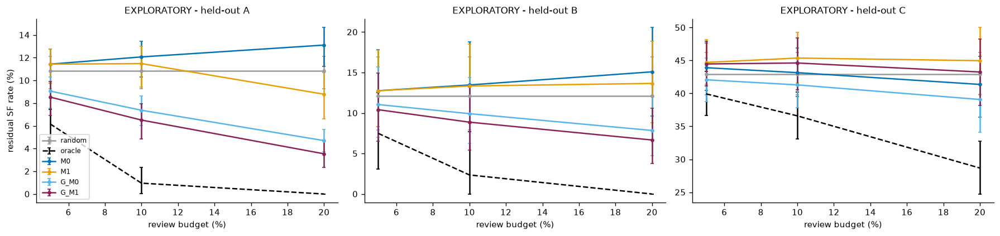

*Figure 8d. EXPLORATORY, post-hoc: residual silent-failure rate of plain vs confidence-gated rankings at 5 / 10 / 20%, with random and oracle references, 95% CIs.*  
**What to notice:** gating closes much of the gap to the oracle on A and B; on the strong shortcut C nothing gets close to the oracle.

In [26]:
gs = rd("stage8/tables/gated_share.csv")
show(gs, "Share of each pool inside the gate (calibrated confidence >= 0.90) (outputs/stage8/tables/gated_share.csv)")
lev = EX[(EX.kind == "level") & EX.metric.isin(["resid_sf", "resid_err"])]
piv = lev.assign(val=[ci(e, l, h, 2, 100, False) for e, l, h in zip(lev.estimate, lev.ci_low, lev.ci_high)], B=(100 * lev.budget).round(0))
piv = piv.pivot_table(index=["heldout", "B", "metric"], columns="quantity", values="val", aggfunc="first").reset_index()
piv = piv[["heldout", "B", "metric", "random", "M0", "M1", "sf_M1", "G_M0", "G_M1", "G_sfM1", "G_sfM2", "oracle"]]
show(piv, "EXPLORATORY, post-hoc - residual silent-failure rate (resid_sf) AND residual overall error rate (resid_err) among accepted cases, % [95% CI]")
say(f"**What this shows:** at 20% the gated M1 ranking leaves {ex('A','G_M1',0.2,'resid_sf').estimate:.2%} silent failures on A "
    f"(plain M1 {ex('A','M1',0.2,'resid_sf').estimate:.2%}, random {ex('A','random',0.2,'resid_sf').estimate:.2%}) and {ex('B','G_M1',0.2,'resid_sf').estimate:.2%} on B "
    f"(plain M1 {ex('B','M1',0.2,'resid_sf').estimate:.2%}). The price is visible errors: its residual ERROR rate on A is {ex('A','G_M1',0.2,'resid_err').estimate:.2%} vs "
    f"{ex('A','M1',0.2,'resid_err').estimate:.2%} for plain M1, because low-confidence errors are no longer referred first.")
exc = EX[(EX.kind == "contrast") & (EX.metric == "dresid_sf")]
show(fmt(exc, d=2, scale=100, signed=True, keep=["table", "heldout", "budget", "quantity", "p_boot", "jackknife_min", "jackknife_max", "verdict"], name="difference in pt [95% CI]"),
     "EXPLORATORY, post-hoc - contrasts of the targeted variants vs plain M0, plain M1 and random (residual SF rate, pt; unadjusted)")
say(f"**What this shows:** gated M1 - plain M1 = A {rc(ex('A','G_M1-M1',0.05),2,100)} / {rc(ex('A','G_M1-M1',0.2),2,100)} pt (5% / 20%), "
    f"B {rc(ex('B','G_M1-M1',0.05),2,100)} / {rc(ex('B','G_M1-M1',0.2),2,100)} pt, C {rc(ex('C','G_M1-M1',0.05),2,100)} / {rc(ex('C','G_M1-M1',0.2),2,100)} pt. "
    f"On C only the gated uncertainty ranking beats random ({rc(ex('C','G_M0-random',0.2),2,100)} pt at 20%); gated M1 does not "
    f"({rc(ex('C','G_M1-random',0.2),2,100)} pt). Ungated sign-free M1 equals M1 ({rc(ex('A','sf_M1-M1',0.2),2,100)} pt).")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a_, H in zip(ax, "ABC"):
    for q in ("random", "oracle", "M0", "M1", "G_M0", "G_M1"):
        g = EX[(EX.kind == "level") & (EX.heldout == H) & (EX.quantity == q) & (EX.metric == "resid_sf")].sort_values("budget")
        a_.errorbar(100 * g.budget, 100 * g.estimate, yerr=[100 * (g.estimate - g.ci_low), 100 * (g.ci_high - g.estimate)], fmt="--" if q == "oracle" else "-o",
                    ms=3, capsize=2, color=COL[q], label=q)
    a_.set_title(f"EXPLORATORY - held-out {H}"); a_.set_xlabel("review budget (%)")
ax[0].set_ylabel("residual SF rate (%)"); ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()
figcap("8d", "EXPLORATORY, post-hoc: residual silent-failure rate of plain vs confidence-gated rankings at 5 / 10 / 20%, with random and oracle references, 95% CIs.",
       "gating closes much of the gap to the oracle on A and B; on the strong shortcut C nothing gets close to the oracle.")

<a id="sx"></a>
## 10b. Extensions (post-hoc): deep-ensemble baseline (E1) and in-family vs out-of-family (E2)
> **Status: EXTENSION (post-hoc).** Plan `docs/extension_plan_frozen.md`, commit 6e6f05c, written before any result below. Never a replacement
> for M0 / M1 / M2; no retraining, no GPU, no new image extraction.

### E1. Deep-ensemble uncertainty baseline
The 5 seeds of each model kind were evaluated on IDENTICAL rows in identical order (checked). Per-seed calibrated probability vectors were not
saved, so they are **reconstructed from the saved penultimate features and the frozen final layer** (check: 99.9th percentile of the confidence
error < 1e-3, asserted). For seed unit *s* the ensemble is the **leave-seed-*s*-out ensemble of the other 4 seeds** (`E`), so the seed-level
bootstrap stays valid; the 5-member ensemble including *s* (`E5`) is a sensitivity. The target is unchanged: silent failures (`sf_090`) of the
single seed-*s* classifier. Signals: log(1 - max mean-probability) (`E-msp`), log predictive entropy (`E-ent`), log mutual information (`E-mi`);
`E-fuse` = non-negative fusion of the first two (the ensemble analogue of M0); `E-M1` = `E-fuse` + Mahalanobis. Everything else (rotation, percentile
standardisation, paired cluster bootstrap, exact-budget referral) is as in Sections 6 and 8.
**Limitation:** variability due to which seeds form the ensemble is only partly captured by the seed-level bootstrap.

In [27]:
t10 = rd("stage10/e1_ensemble_baseline.csv"); rd("stage10/ens_reconstruction_checks.csv")
def e10(H, q, m, b=None, kind="level"):
    d = t10[(t10.kind == kind)]
    return one(d, heldout=H, quantity=q, metric=m) if b is None else one(d, heldout=H, quantity=q, metric=m, budget=float(b))
names10 = ["M0", "E_msp", "E_ent", "E_mi", "E_fuse", "M1", "E_M1", "E5_fuse", "E5_M1", "M2"]
lvl = t10[(t10.kind == "level") & t10.metric.isin(["auroc", "auprc", "aurc"])].copy()
lvl["val"] = [ci(e, l, h, 3, 1, False) for e, l, h in zip(lvl.estimate, lvl.ci_low, lvl.ci_high)]
show(lvl.pivot_table(index=["heldout", "metric"], columns="quantity", values="val", aggfunc="first")[names10].reset_index(),
     "E1 - detection of silent failures (sf_090): AUROC, AUPRC, AURC, held-out-family rotation, mean over 5 seed units [95% CI] (outputs/stage10/e1_ensemble_baseline.csv)")
dA = lambda H, m: e10(H, "E_fuse", m).estimate - e10(H, "M0", m).estimate
say(f"**What this shows (EXTENSION):** the ensemble improves on a single model's uncertainty: AUROC E-fuse - M0 = {dA('A','auroc'):+.3f} (A), {dA('B','auroc'):+.3f} (B), "
    f"{dA('C','auroc'):+.3f} (C; point estimates, paired CIs in the contrast table below). On A, M1 ({e10('A','M1','auroc').estimate:.3f}) and E-fuse ({e10('A','E_fuse','auroc').estimate:.3f}) "
    f"are similar, and E-M1 reaches {e10('A','E_M1','auroc').estimate:.3f}; on C the representation signal lowers AUROC even on top of the ensemble "
    f"(E-M1 {e10('C','E_M1','auroc').estimate:.3f} vs E-fuse {e10('C','E_fuse','auroc').estimate:.3f}).")

**E1 - detection of silent failures (sf_090): AUROC, AUPRC, AURC, held-out-family rotation, mean over 5 seed units [95% CI] (outputs/stage10/e1_ensemble_baseline.csv)** - 9 rows

quantity,heldout,metric,M0,E_msp,E_ent,E_mi,E_fuse,M1,E_M1,E5_fuse,E5_M1,M2
,A,auprc,"0.135 [0.116, 0.148]","0.196 [0.169, 0.218]","0.193 [0.166, 0.215]","0.209 [0.188, 0.230]","0.193 [0.166, 0.215]","0.177 [0.164, 0.189]","0.241 [0.215, 0.267]","0.179 [0.154, 0.199]","0.228 [0.205, 0.251]","0.177 [0.164, 0.189]"
,A,aurc,"0.055 [0.048, 0.063]","0.039 [0.034, 0.044]","0.040 [0.034, 0.044]","0.039 [0.033, 0.044]","0.040 [0.034, 0.044]","0.040 [0.031, 0.049]","0.032 [0.025, 0.039]","0.041 [0.035, 0.046]","0.033 [0.025, 0.040]","0.040 [0.031, 0.049]"
,A,auroc,"0.646 [0.632, 0.661]","0.751 [0.738, 0.762]","0.749 [0.738, 0.760]","0.757 [0.745, 0.766]","0.749 [0.738, 0.760]","0.739 [0.714, 0.770]","0.796 [0.770, 0.821]","0.736 [0.726, 0.747]","0.790 [0.765, 0.816]","0.739 [0.714, 0.770]"
,B,auprc,"0.122 [0.081, 0.172]","0.147 [0.100, 0.214]","0.147 [0.100, 0.214]","0.144 [0.099, 0.208]","0.147 [0.100, 0.214]","0.133 [0.088, 0.189]","0.163 [0.111, 0.233]","0.139 [0.096, 0.200]","0.156 [0.106, 0.221]","0.131 [0.088, 0.185]"
,B,aurc,"0.081 [0.050, 0.120]","0.073 [0.043, 0.110]","0.073 [0.043, 0.110]","0.078 [0.044, 0.118]","0.073 [0.043, 0.110]","0.074 [0.045, 0.110]","0.068 [0.038, 0.102]","0.075 [0.044, 0.112]","0.070 [0.039, 0.105]","0.075 [0.045, 0.111]"
,B,auroc,"0.554 [0.510, 0.600]","0.605 [0.547, 0.669]","0.605 [0.547, 0.669]","0.594 [0.535, 0.661]","0.605 [0.547, 0.669]","0.592 [0.545, 0.644]","0.637 [0.575, 0.704]","0.593 [0.536, 0.655]","0.624 [0.565, 0.691]","0.588 [0.543, 0.637]"
,C,auprc,"0.524 [0.474, 0.569]","0.489 [0.427, 0.559]","0.549 [0.471, 0.624]","0.478 [0.417, 0.546]","0.549 [0.471, 0.624]","0.473 [0.419, 0.530]","0.472 [0.412, 0.535]","0.553 [0.475, 0.627]","0.471 [0.411, 0.534]","0.473 [0.419, 0.530]"
,C,aurc,"0.239 [0.203, 0.266]","0.383 [0.322, 0.431]","0.235 [0.205, 0.258]","0.390 [0.333, 0.437]","0.235 [0.205, 0.258]","0.265 [0.230, 0.290]","0.269 [0.227, 0.299]","0.234 [0.204, 0.257]","0.271 [0.228, 0.300]","0.265 [0.230, 0.290]"
,C,auroc,"0.704 [0.657, 0.749]","0.595 [0.514, 0.684]","0.704 [0.644, 0.762]","0.578 [0.496, 0.665]","0.704 [0.644, 0.762]","0.647 [0.588, 0.705]","0.643 [0.573, 0.719]","0.705 [0.646, 0.762]","0.641 [0.571, 0.718]","0.647 [0.588, 0.705]"


**What this shows (EXTENSION):** the ensemble improves on a single model's uncertainty: AUROC E-fuse - M0 = +0.103 (A), +0.051 (B), +0.000 (C; point estimates, paired CIs in the contrast table below). On A, M1 (0.739) and E-fuse (0.749) are similar, and E-M1 reaches 0.796; on C the representation signal lowers AUROC even on top of the ensemble (E-M1 0.643 vs E-fuse 0.704).

**E1 - exact-budget referral: residual silent-failure rate (resid_sf) and residual overall error rate (resid_err), % [95% CI]** - 18 rows

quantity,heldout,B,metric,random,M0,E_msp,E_ent,E_mi,E_fuse,M1,E_M1,E5_fuse,E5_M1,M2,oracle
,A,5.0,resid_err,"21.97 [20.64, 23.39]","19.70 [18.43, 21.06]","19.71 [18.44, 21.00]","19.66 [18.43, 20.95]","20.01 [18.72, 21.30]","19.66 [18.43, 20.95]","19.52 [18.14, 20.98]","19.51 [18.24, 20.82]","19.51 [18.26, 20.83]","19.47 [18.13, 20.76]","19.52 [18.14, 20.98]","17.86 [16.47, 19.36]"
,A,5.0,resid_sf,"10.86 [9.28, 12.10]","11.43 [9.76, 12.73]","10.54 [8.96, 11.77]","10.62 [9.06, 11.86]","10.27 [8.67, 11.49]","10.62 [9.06, 11.86]","11.43 [9.76, 12.73]","10.22 [8.60, 11.47]","10.83 [9.24, 12.08]","10.41 [8.80, 11.69]","11.43 [9.76, 12.73]","6.17 [4.50, 7.47]"
,A,10.0,resid_err,"21.97 [20.64, 23.39]","17.47 [15.98, 18.94]","17.55 [16.40, 18.73]","17.44 [16.36, 18.57]","17.93 [16.72, 19.12]","17.44 [16.36, 18.57]","17.27 [15.92, 18.74]","17.06 [15.64, 18.39]","17.23 [16.15, 18.35]","16.97 [15.54, 18.29]","17.27 [15.92, 18.74]","13.29 [12.53, 14.88]"
,A,10.0,resid_sf,"10.86 [9.28, 12.10]","12.07 [10.31, 13.44]","9.99 [8.47, 11.19]","10.17 [8.63, 11.35]","9.67 [8.05, 10.87]","10.17 [8.63, 11.35]","11.48 [9.42, 13.01]","9.31 [7.56, 10.60]","10.54 [8.98, 11.76]","9.62 [7.87, 10.86]","11.48 [9.42, 13.01]","0.96 [0.04, 2.33]"
,A,20.0,resid_err,"21.97 [20.64, 23.39]","13.14 [11.33, 14.76]","12.92 [11.81, 13.97]","12.84 [11.88, 13.82]","13.57 [12.54, 14.43]","12.84 [11.88, 13.82]","12.74 [11.00, 14.40]","12.41 [10.84, 13.76]","12.44 [11.34, 13.50]","12.31 [10.80, 13.64]","12.74 [11.00, 14.40]","12.46 [11.88, 13.02]"
,A,20.0,resid_sf,"10.86 [9.28, 12.10]","13.11 [11.24, 14.66]","8.51 [7.16, 9.66]","8.54 [7.19, 9.69]","8.34 [6.93, 9.37]","8.54 [7.19, 9.69]","8.79 [6.61, 10.69]","7.01 [5.25, 8.45]","9.16 [7.80, 10.31]","7.26 [5.39, 8.74]","8.79 [6.61, 10.69]","0.00 [0.00, 0.00]"
,B,5.0,resid_err,"21.03 [15.29, 26.82]","19.67 [13.64, 25.72]","19.61 [13.89, 25.45]","19.61 [13.89, 25.45]","20.36 [14.64, 26.10]","19.61 [13.89, 25.45]","19.59 [13.69, 25.54]","19.82 [14.11, 25.55]","19.48 [13.71, 25.37]","19.64 [13.79, 25.32]","19.59 [13.69, 25.57]","16.88 [10.84, 22.97]"
,B,5.0,resid_sf,"12.12 [7.91, 16.91]","12.76 [8.33, 17.80]","12.17 [7.82, 17.10]","12.17 [7.82, 17.10]","12.17 [7.82, 16.98]","12.17 [7.82, 17.10]","12.76 [8.33, 17.77]","12.05 [7.66, 16.89]","12.30 [7.88, 17.20]","12.14 [7.73, 17.04]","12.75 [8.33, 17.77]","7.49 [3.06, 12.53]"
,B,10.0,resid_err,"21.03 [15.29, 26.82]","18.28 [12.30, 24.45]","18.28 [12.56, 24.08]","18.28 [12.56, 24.08]","19.20 [13.56, 24.93]","18.28 [12.56, 24.08]","17.92 [12.11, 24.00]","18.37 [12.70, 24.03]","18.02 [12.27, 23.78]","18.03 [12.30, 23.80]","17.95 [12.11, 24.02]","12.26 [7.49, 18.69]"
,B,10.0,resid_sf,"12.12 [7.91, 16.91]","13.47 [8.79, 18.79]","12.17 [7.70, 17.11]","12.17 [7.70, 17.11]","12.13 [7.70, 17.04]","12.17 [7.70, 17.11]","13.34 [8.70, 18.49]","11.85 [7.41, 16.81]","12.41 [7.89, 17.55]","12.06 [7.55, 17.12]","13.39 [8.71, 18.56]","2.35 [0.00, 7.68]"


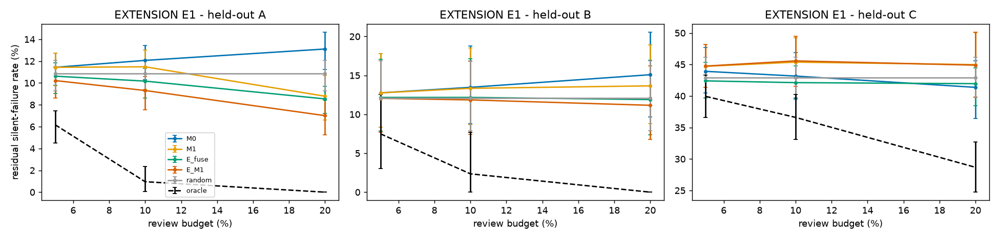

*Figure 10. EXTENSION E1: residual silent-failure rate vs review budget for single-model M0 / M1, the leave-seed-out ensemble E-fuse and E-M1, with random and oracle references (95% paired CIs).*  
**What to notice:** on A and B the ensemble alone reproduces most of the 20%-budget gain that M1 had over M0 (A residual: M0 13.1%, M1 8.8%, E-fuse 8.5%, E-M1 7.0%); on C no ranking comes close to the oracle and Mahalanobis again hurts.

**E1 - paired contrasts (EXTENSION, unadjusted; E-fuse vs M0, M1 vs E-fuse, E-M1 vs E-fuse, variants)** - 198 rows

heldout,quantity,metric,B,difference [95% CI] (pt for dresid_sf),p_boot,jackknife_min,jackknife_max,verdict
A,E_fuse-M0,dresid_sf,5.0,"-0.81 [-0.93, -0.68]",0.000,-0.008481,-0.007820,reduces
A,E_fuse-M0,dresid_sf,10.0,"-1.90 [-2.19, -1.61]",0.000,-0.019537,-0.018283,reduces
A,E_fuse-M0,dresid_sf,20.0,"-4.57 [-5.13, -3.85]",0.000,-0.048133,-0.044372,reduces
A,E_fuse-M0,dauroc,,"+0.103 [+0.081, +0.119]",0.000,0.098507,0.109796,improves
A,E_fuse-M0,dauprc,,"+0.058 [+0.047, +0.069]",0.000,0.054574,0.062211,improves
A,E_fuse-M0,daurc,,"-0.0153 [-0.0193, -0.0110]",0.000,-0.016617,-0.014248,
A,M1-E_fuse,dresid_sf,5.0,"+0.81 [+0.68, +0.93]",0.000,0.007820,0.008481,increases
A,M1-E_fuse,dresid_sf,10.0,"+1.31 [+0.71, +1.78]",0.001,0.012832,0.013550,increases
A,M1-E_fuse,dresid_sf,20.0,"+0.24 [-0.71, +1.12]",0.508,0.000336,0.003640,inconclusive
A,M1-E_fuse,dauroc,,"-0.010 [-0.037, +0.022]",0.447,-0.015794,-0.003283,inconclusive


**E1 - does the ensemble baseline change a conclusion? (rule fixed in the plan: the verdict class of 'M1 vs ensemble' differs from that of 'M1 vs M0')** - 12 rows

held-out,metric,budget %,M1 vs M0,M1 vs ensemble E-fuse,verdict class,Mahalanobis added to the ensemble (E-M1 - E-fuse)
A,dresid_sf,5.0,"+0.00 [-0.00, +0.00] no practical difference","+0.81 [+0.68, +0.93] increases",CHANGES,"-0.40 [-0.62, -0.22] reduces"
A,dresid_sf,10.0,"-0.59 [-0.99, -0.32] reduces","+1.31 [+0.71, +1.78] increases",CHANGES,"-0.86 [-1.21, -0.53] reduces"
A,dresid_sf,20.0,"-4.32 [-5.15, -3.43] reduces","+0.24 [-0.71, +1.12] inconclusive",CHANGES,"-1.53 [-2.13, -1.03] reduces"
A,dauroc,,"+0.093 [+0.064, +0.127] improves","-0.010 [-0.037, +0.022] inconclusive",CHANGES,"+0.046 [+0.028, +0.071] improves"
B,dresid_sf,5.0,"-0.00 [-0.06, +0.00] no practical difference","+0.59 [+0.29, +0.96] increases",CHANGES,"-0.12 [-0.47, +0.09] inconclusive"
B,dresid_sf,10.0,"-0.12 [-0.49, +0.00] inconclusive","+1.17 [+0.65, +1.87] increases",CHANGES,"-0.32 [-0.83, +0.11] inconclusive"
B,dresid_sf,20.0,"-1.43 [-2.47, -0.45] reduces","+1.76 [+0.48, +2.98] increases",CHANGES,"-0.74 [-1.34, -0.15] reduces"
B,dauroc,,"+0.038 [+0.015, +0.065] improves","-0.013 [-0.056, +0.026] inconclusive",CHANGES,"+0.031 [+0.013, +0.055] improves"
C,dresid_sf,5.0,"+0.80 [+0.31, +1.25] increases","+2.31 [+1.55, +3.02] increases",same,"+2.35 [+1.59, +3.05] increases"
C,dresid_sf,10.0,"+2.21 [+1.30, +3.06] increases","+3.25 [+1.61, +5.01] increases",same,"+3.45 [+1.63, +5.27] increases"


**What this shows (EXTENSION):** the verdict class changes in 8 of 12 (family, metric, budget) cells. Residual silent failures at 20%: E-fuse - M0 = -4.57 [-5.13, -3.85] pt (A), -3.19 [-4.82, -1.59] pt (B); M1 - E-fuse = +0.24 [-0.71, +1.12] pt (A) and +1.76 [+0.48, +2.98] pt (B). So much of the apparent benefit of representation drift over one model's uncertainty is a benefit of any better uncertainty estimate. Mahalanobis on top of the ensemble still helps on A (-1.53 [-2.13, -1.03] pt at 20%) and B (-0.74 [-1.34, -0.15] pt) but hurts on C (+2.94 [+0.64, +6.18] pt). Mutual information is not better than the maximum-probability signal (E-mi - E-msp at 20%: A -0.18 [-0.42, +0.27], C +0.33 [+0.05, +0.64] pt). The ensemble still leaves 10.6% residual silent failures at 5% on A (random 10.9%): uncertainty-first ranking, even from an ensemble, does not reach silent failures at small budgets.

In [28]:
lv = t10[(t10.kind == "level") & t10.metric.isin(["resid_sf", "resid_err"]) & t10.quantity.isin(names10 + ["random", "oracle"])].copy()
lv["val"] = [ci(e, l, h, 2, 100, False) for e, l, h in zip(lv.estimate, lv.ci_low, lv.ci_high)]; lv["B"] = (100 * lv.budget).round(0)
show(lv.pivot_table(index=["heldout", "B", "metric"], columns="quantity", values="val", aggfunc="first")[["random"] + names10 + ["oracle"]].reset_index(),
     "E1 - exact-budget referral: residual silent-failure rate (resid_sf) and residual overall error rate (resid_err), % [95% CI]")
png("stage10/figures/fig10_e1_referral.png", width=1000)
figcap("10", "EXTENSION E1: residual silent-failure rate vs review budget for single-model M0 / M1, the leave-seed-out ensemble E-fuse and E-M1, with random and oracle references (95% paired CIs).",
       f"on A and B the ensemble alone reproduces most of the 20%-budget gain that M1 had over M0 (A residual: M0 {100*e10('A','M0','resid_sf',0.2).estimate:.1f}%, M1 {100*e10('A','M1','resid_sf',0.2).estimate:.1f}%, "
       f"E-fuse {100*e10('A','E_fuse','resid_sf',0.2).estimate:.1f}%, E-M1 {100*e10('A','E_M1','resid_sf',0.2).estimate:.1f}%); on C no ranking comes close to the oracle and Mahalanobis again hurts.")
cx = t10[(t10.kind == "contrast") & t10.metric.isin(["dresid_sf", "dauroc", "dauprc", "daurc"]) &
         t10.quantity.isin(["E_fuse-M0", "M1-E_fuse", "E_M1-E_fuse", "E_M1-M1", "E_mi-E_msp", "E_ent-E_msp", "E_msp-M0", "E5_fuse-M0", "M1-E5_fuse", "E5_M1-E5_fuse", "M1-M0"])]
o = cx.assign(est=[ci(e, l, h, 2, 100, True) if m == "dresid_sf" else ci(e, l, h, 4 if m == "daurc" else 3, 1, True) for e, l, h, m in zip(cx.estimate, cx.ci_low, cx.ci_high, cx.metric)],
              B=(100 * cx.budget).round(0))
show(o[["heldout", "quantity", "metric", "B", "est", "p_boot", "jackknife_min", "jackknife_max", "verdict"]].rename(columns={"est": "difference [95% CI] (pt for dresid_sf)"}),
     "E1 - paired contrasts (EXTENSION, unadjusted; E-fuse vs M0, M1 vs E-fuse, E-M1 vs E-fuse, variants)")
def cls(v):
    return "better" if v in ("reduces", "improves") else "worse" if v in ("increases", "worse") else "no difference" if v == "no practical difference" else "inconclusive"
rows_ = []
for H in "ABC":
    for m, bs in (("dresid_sf", (0.05, 0.1, 0.2)), ("dauroc", (None,))):
        for b in bs:
            def g(q):
                d = cx[(cx.heldout == H) & (cx.quantity == q) & (cx.metric == m)]
                d = d[np.isclose(d.budget, b)] if b is not None else d
                return d.iloc[0]
            dd, sc_ = (2, 100) if m == "dresid_sf" else (3, 1)
            a_, e_, f_ = g("M1-M0"), g("M1-E_fuse"), g("E_M1-E_fuse")
            rows_.append({"held-out": H, "metric": m, "budget %": (None if b is None else int(100 * b)), "M1 vs M0": f"{rc(a_, dd, sc_)} {a_.verdict}",
                          "M1 vs ensemble E-fuse": f"{rc(e_, dd, sc_)} {e_.verdict}",
                          "verdict class": "same" if cls(a_.verdict) == cls(e_.verdict) else "CHANGES",
                          "Mahalanobis added to the ensemble (E-M1 - E-fuse)": f"{rc(f_, dd, sc_)} {f_.verdict}"})
rr = pd.DataFrame(rows_)
show(rr, "E1 - does the ensemble baseline change a conclusion? (rule fixed in the plan: the verdict class of 'M1 vs ensemble' differs from that of 'M1 vs M0')")
cx20 = lambda H, q: rc(e10(H, q, "dresid_sf", 0.2, "contrast"), 2, 100)
say(f"**What this shows (EXTENSION):** the verdict class changes in {int((rr['verdict class'] == 'CHANGES').sum())} of {len(rr)} (family, metric, budget) cells. "
    f"Residual silent failures at 20%: E-fuse - M0 = {cx20('A','E_fuse-M0')} pt (A), {cx20('B','E_fuse-M0')} pt (B); M1 - E-fuse = {cx20('A','M1-E_fuse')} pt (A) and {cx20('B','M1-E_fuse')} pt (B). "
    "So much of the apparent benefit of representation drift over one model's uncertainty is a benefit of any better uncertainty estimate. Mahalanobis on top of the "
    f"ensemble still helps on A ({cx20('A','E_M1-E_fuse')} pt at 20%) and B ({cx20('B','E_M1-E_fuse')} pt) but hurts on C ({cx20('C','E_M1-E_fuse')} pt). Mutual information is not better "
    f"than the maximum-probability signal (E-mi - E-msp at 20%: A {cx20('A','E_mi-E_msp')}, C {cx20('C','E_mi-E_msp')} pt). The ensemble still leaves "
    f"{100*e10('A','E_fuse','resid_sf',0.05).estimate:.1f}% residual silent failures at 5% on A (random {100*e10('A','random','resid_sf',0.05).estimate:.1f}%): "
    "uncertainty-first ranking, even from an ensemble, does not reach silent failures at small budgets.")

### E2. In-family (source) vs out-of-family detection - saved tables only
Source-distribution rows (family A `clean`, severity 0; family B `id_test`; family C `aligned`) versus shifted rows of the same family, using the
Phase 5 breakdown tables (AUROC / AUPRC with saved CIs) and the Phase 7 breakdowns (residual rate at a 20% budget). The fusion weights are the
held-out-family rotation weights, so "in-family" here means **source-distribution evaluation**, not a fusion tuned inside the same family. The
Phase 5 incremental logistic regression (fitted and evaluated in the same family, in-sample, descriptive) supplies in-family information.

In [29]:
sbk = rd("stage5/secondary_breakdowns.csv"); b7 = rd("stage7/breakdowns.csv")
spec = [("A by severity", "A", ["0", "1", "2", "3", "4", "5"], "A severity (0 = clean = source)"),
        ("B by condition", "B", ["id_test", "ood_c1", "ood_c2"], "B condition (id_test = source)"),
        ("C by condition", "C", ["aligned", "removed", "reversed"], "C cue state (aligned = source)")]
rows = []
for an, H, lvls, lab in spec:
    for l in lvls:
        r = {"family / level": f"{lab}: {l}"}
        for q in ("M0", "M1", "M2"):
            for m in ("AUROC", "AUPRC"):
                d = sbk[(sbk.analysis == an) & (sbk.level.astype(str) == l) & (sbk.quantity == q) & (sbk.metric == m)].iloc[0]
                r[f"{q} {m}"] = ci(d.estimate, d.ci_low, d.ci_high, 3, 1, False) if pd.notna(d.estimate) else "not estimable (no silent failures)"
            d7 = b7[(b7.analysis == an) & (b7.level.astype(str) == l) & (b7.quantity == q) & (b7.metric == "resid_sf") & np.isclose(b7.budget, 0.2)].iloc[0]
            r[f"{q} resid. SF @20% (%)"] = ci(d7.estimate, d7.ci_low, d7.ci_high, 2, 100, False)
        r["SF prevalence"] = round(float(d.sf_rate), 4)
        rows.append(r)
e2 = pd.DataFrame(rows)
show(e2, "E2 - detection (AUROC, AUPRC) and residual silent-failure rate at a 20% budget, source vs shifted rows (outputs/stage5/secondary_breakdowns.csv, outputs/stage7/breakdowns.csv)")
a0, a5 = e2.iloc[0], e2.iloc[5]
say(f"**What this shows (EXTENSION):** M0's detection AUROC is highest on source data and falls with shift on A (clean {a0['M0 AUROC']} -> severity 5 {a5['M0 AUROC']}), "
    f"whereas M1 starts lower on clean data ({a0['M1 AUROC']}) and degrades more slowly ({a5['M1 AUROC']}): representation drift helps where the shift is strong, not in-distribution. "
    "On B the source split has few silent failures and wide CIs; on C the aligned state has none. M2 equals M1 in every row of A and C.")
il = rd("stage5/incremental_logit.csv")
inl = il.groupby("heldout").agg(LR_M1_vs_M0=("LR_M1_vs_M0", "median"), coef_maha=("coef_maha", "median"), LR_M2_vs_M1=("LR_M2_vs_M1", "median"),
                                coef_cam=("coef_cam", "median"), max_p_cam=("wald_p_cam", "max")).round(4).reset_index()
inl["out-of-family M2-M1 dAUROC (monotone fusion)"] = [rc(t2r(H, "M2-M1", "dAUROC"), 4) for H in inl.heldout]
show(inl, "E2 - in-sample (in-family) information: unconstrained logistic regression fitted and evaluated on the held-out family itself, median over seeds, vs the out-of-family monotone result")
pword = 'all Wald p < 1e-30' if inl.max_p_cam.max() < 1e-30 else 'largest Wald p = %.1e' % inl.max_p_cam.max()
say(f"**What this shows (EXTENSION):** inside the family, CAM drift carries significant information given M0 + Mahalanobis (likelihood-ratio statistics "
    f"{inl.LR_M2_vs_M1.min():.0f}-{inl.LR_M2_vs_M1.max():.0f}, {pword}) but with a NEGATIVE coefficient ({inl.coef_cam.min():.2f} to {inl.coef_cam.max():.2f}); "
    "out-of-family, the pre-registered monotone fusion cannot use it (M2-M1 = 0). So the information exists in-sample but does not transfer as a positive-weight alarm; "
    "with a free sign it does help out-of-family (P2, Section 9). **Limitation:** no fusion tuned and tested on disjoint clusters inside the same family was run, so this is "
    "evidence about information content, not a within-family generalisation estimate.")

**E2 - detection (AUROC, AUPRC) and residual silent-failure rate at a 20% budget, source vs shifted rows (outputs/stage5/secondary_breakdowns.csv, outputs/stage7/breakdowns.csv)** - 12 rows

family / level,M0 AUROC,M0 AUPRC,M0 resid. SF @20% (%),M1 AUROC,M1 AUPRC,M1 resid. SF @20% (%),M2 AUROC,M2 AUPRC,M2 resid. SF @20% (%),SF prevalence
A severity (0 = clean = source): 0,"0.951 [0.891, 0.984]","0.039 [0.017, 0.105]","0.01 [0.00, 0.05]","0.895 [0.836, 0.943]","0.014 [0.007, 0.036]","0.03 [0.00, 0.12]","0.895 [0.836, 0.943]","0.014 [0.007, 0.036]","0.03 [0.00, 0.12]",0.0019
A severity (0 = clean = source): 1,"0.803 [0.786, 0.820]","0.090 [0.074, 0.115]","1.64 [1.37, 1.91]","0.848 [0.825, 0.872]","0.127 [0.100, 0.181]","1.43 [1.14, 1.77]","0.848 [0.825, 0.872]","0.127 [0.100, 0.181]","1.43 [1.14, 1.77]",0.0376
A severity (0 = clean = source): 2,"0.720 [0.706, 0.736]","0.110 [0.093, 0.120]","6.19 [4.98, 7.27]","0.789 [0.764, 0.818]","0.147 [0.130, 0.173]","4.18 [3.04, 5.22]","0.789 [0.764, 0.818]","0.147 [0.130, 0.173]","4.18 [3.04, 5.21]",0.0692
A severity (0 = clean = source): 3,"0.624 [0.607, 0.641]","0.132 [0.108, 0.149]","13.91 [11.42, 15.96]","0.717 [0.687, 0.750]","0.169 [0.152, 0.184]","9.68 [7.01, 12.03]","0.717 [0.687, 0.750]","0.169 [0.152, 0.184]","9.68 [7.01, 12.03]",0.1121
A severity (0 = clean = source): 4,"0.551 [0.539, 0.564]","0.145 [0.120, 0.164]","18.06 [14.95, 20.75]","0.653 [0.616, 0.699]","0.179 [0.165, 0.193]","14.97 [11.03, 18.09]","0.653 [0.616, 0.699]","0.179 [0.165, 0.193]","14.97 [11.03, 18.09]",0.1445
A severity (0 = clean = source): 5,"0.490 [0.476, 0.506]","0.170 [0.148, 0.186]","23.66 [20.74, 26.12]","0.599 [0.558, 0.651]","0.205 [0.195, 0.214]","21.79 [17.61, 24.82]","0.599 [0.558, 0.651]","0.205 [0.195, 0.214]","21.79 [17.61, 24.83]",0.1893
B condition (id_test = source): id_test,"0.637 [0.546, 0.792]","0.050 [0.010, 0.091]","4.30 [0.27, 9.36]","0.672 [0.582, 0.807]","0.058 [0.012, 0.106]","3.59 [0.24, 8.90]","0.673 [0.584, 0.810]","0.058 [0.012, 0.106]","3.60 [0.24, 8.91]",0.0392
B condition (id_test = source): ood_c1,"0.517 [0.443, 0.560]","0.063 [0.044, 0.084]","8.30 [5.72, 10.88]","0.556 [0.487, 0.598]","0.067 [0.048, 0.088]","8.01 [5.43, 10.48]","0.555 [0.485, 0.599]","0.067 [0.048, 0.088]","8.03 [5.49, 10.54]",0.0664
B condition (id_test = source): ood_c2,"0.592 [0.536, 0.685]","0.246 [0.175, 0.369]","25.70 [17.64, 32.93]","0.606 [0.550, 0.705]","0.252 [0.179, 0.388]","25.18 [17.20, 32.14]","0.604 [0.549, 0.701]","0.251 [0.179, 0.385]","25.19 [17.20, 32.17]",0.2273
C cue state (aligned = source): aligned,not estimable (no silent failures),not estimable (no silent failures),"0.00 [0.00, 0.00]",not estimable (no silent failures),not estimable (no silent failures),"0.00 [0.00, 0.00]",not estimable (no silent failures),not estimable (no silent failures),"0.00 [0.00, 0.00]",0.0000


**What this shows (EXTENSION):** M0's detection AUROC is highest on source data and falls with shift on A (clean 0.951 [0.891, 0.984] -> severity 5 0.490 [0.476, 0.506]), whereas M1 starts lower on clean data (0.895 [0.836, 0.943]) and degrades more slowly (0.599 [0.558, 0.651]): representation drift helps where the shift is strong, not in-distribution. On B the source split has few silent failures and wide CIs; on C the aligned state has none. M2 equals M1 in every row of A and C.

**E2 - in-sample (in-family) information: unconstrained logistic regression fitted and evaluated on the held-out family itself, median over seeds, vs the out-of-family monotone result** - 3 rows

heldout,LR_M1_vs_M0,coef_maha,LR_M2_vs_M1,coef_cam,max_p_cam,out-of-family M2-M1 dAUROC (monotone fusion)
A,6844.4675,5.0286,190.7798,-0.4301,0.0,"-0.0000 [-0.0000, -0.0000]"
B,434.5387,1.9097,263.3542,-1.6233,0.0,"-0.0038 [-0.0114, +0.0002]"
C,26.0678,-0.0247,271.1696,-1.8564,0.0,"-0.0000 [-0.0000, +0.0000]"


**What this shows (EXTENSION):** inside the family, CAM drift carries significant information given M0 + Mahalanobis (likelihood-ratio statistics 191-271, all Wald p < 1e-30) but with a NEGATIVE coefficient (-1.86 to -0.43); out-of-family, the pre-registered monotone fusion cannot use it (M2-M1 = 0). So the information exists in-sample but does not transfer as a positive-weight alarm; with a free sign it does help out-of-family (P2, Section 9). **Limitation:** no fusion tuned and tested on disjoint clusters inside the same family was run, so this is evidence about information content, not a within-family generalisation estimate.

<a id="s11"></a>
## 11. Shortcut case study (Figure 7)
Does Grad-CAM *see* the shortcut cue, and why do all monitors fail on it? Inputs: the share of CAM mass on the cue patch (Phase 4), the
inversion diagnosis (Phase 5) and the cue-state results (Phase 8). No per-image Grad-CAM example PNGs were saved in the pipeline, so no
qualitative CAM overlays are shown (a limitation).

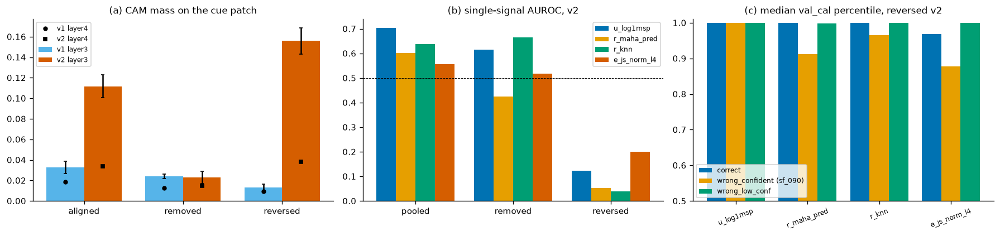

*Figure 7. Shortcut case study: (a) share of Grad-CAM mass on the cue patch per cue state (v1, v2); (b) single-signal detection AUROC pooled and within each cue state (v2); (c) how atypical correct predictions vs silent failures look under the reversed cue (median val_cal percentile).*  
**What to notice:** layer3 CAM concentrates on the cue for v2 when it is present (aligned 0.112, reversed 0.156, removed 0.023) - the explanation does see the cue (validity check passed) - yet the silently wrong cases are the TYPICAL ones, so typicality monitors invert.

**CAM mass on the cue patch (outputs/stage4/cue_mass.csv)** - 6 rows

model_kind,condition,cue_mass_l4_mean,cue_mass_l4_std,cue_mass_l3_mean,cue_mass_l3_std
shortcut,aligned,0.0186,0.0003,0.0328,0.0059
shortcut,removed,0.0126,0.0002,0.0240,0.0022
shortcut,reversed,0.0091,0.0006,0.0132,0.0030
shortcutv2,aligned,0.0338,0.0009,0.1116,0.0112
shortcutv2,removed,0.0147,0.0003,0.0231,0.0059
shortcutv2,reversed,0.0383,0.0003,0.1559,0.0127


**What this shows:** Grad-CAM is a valid detector of the cue's *use* (mass moves with the cue), but cue-driven errors are confident and typical; post-hoc monitoring cannot flag them unless the monitor is allowed to treat typicality as suspicious (sign-free CAM, Section 9).

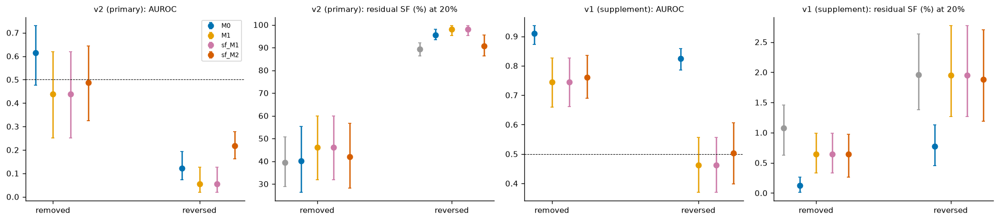

*Figure 7b. Cue-state results repeated from Figure 8c for the case study.*  
**What to notice:** the inversion persists for every detector; sign-free M2 recovers part of it.

**Dose response of every signal over severity per corruption (outputs/stage4/dose_response.csv)** - 132 rows

corruption,signal,sev0,sev1,sev2,sev3,sev4,sev5,monotone_nondecreasing
brightness_down,u_1msp,0.5266,0.8089,0.8614,0.8957,0.9145,0.9269,True
brightness_down,u_entropy,0.5268,0.8091,0.8618,0.8963,0.9152,0.9277,True
brightness_down,u_energy,0.5272,0.7901,0.8406,0.8746,0.8930,0.9053,True
brightness_down,r_maha_pred,0.5055,0.8705,0.9257,0.9544,0.9663,0.9705,True
brightness_down,r_maha_min,0.5055,0.8694,0.9244,0.9529,0.9651,0.9695,True
brightness_down,r_knn,0.5103,0.8932,0.9389,0.9645,0.9750,0.9796,True
brightness_down,e_js_norm_l4,0.5000,0.6425,0.6846,0.7089,0.7211,0.7263,True
brightness_down,e_js_raw_l4,0.4975,0.6402,0.6815,0.7021,0.7103,0.7112,True
brightness_down,e_pca_l4,0.5153,0.6534,0.6993,0.7176,0.7247,0.7254,True
brightness_down,e_js_norm_l3,0.5331,0.7293,0.7618,0.7704,0.7674,0.7590,True


**What this shows:** 130 of 132 (corruption, signal) curves are monotone non-decreasing in severity; the signals respond to shift magnitude as intended.

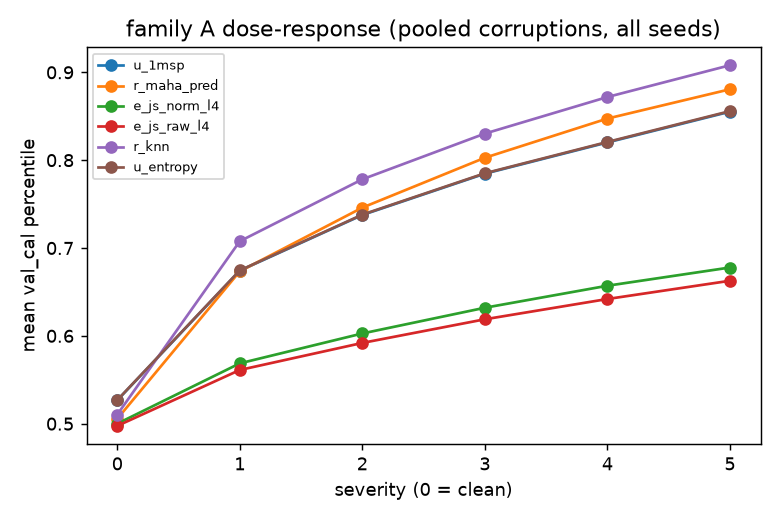

*Figure S5. Saved Phase 4 dose-response figure for family A.*  
**What to notice:** signals rise with severity for most corruptions.

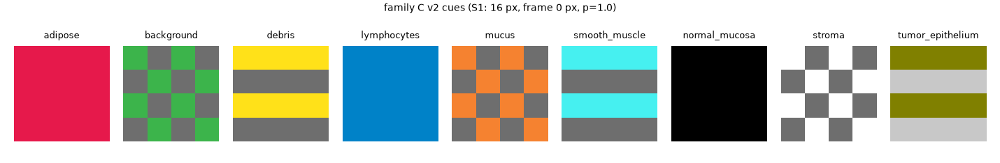

*Figure S6. The v2 shortcut cue palette (one colour per class).*  
**What to notice:** the cue is a small corner patch, invisible to a pathologist's diagnosis.

In [30]:
cm = rd("stage4/cue_mass.csv")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for i, (k, lab) in enumerate((("shortcut", "v1"), ("shortcutv2", "v2"))):
    d = cm[cm.model_kind == k].set_index("condition").loc[["aligned", "removed", "reversed"]]
    ax[0].bar(np.arange(3) + (i - 0.5) * 0.38, d.cue_mass_l3_mean, 0.38, yerr=d.cue_mass_l3_std, color=[OI["sky"], OI["vermillion"]][i], label=f"{lab} layer3", capsize=2)
    ax[0].plot(np.arange(3) + (i - 0.5) * 0.38, d.cue_mass_l4_mean, "k" + ["o", "s"][i], ms=4, label=f"{lab} layer4")
ax[0].set_xticks(range(3)); ax[0].set_xticklabels(["aligned", "removed", "reversed"]); ax[0].set_title("(a) CAM mass on the cue patch"); ax[0].legend(fontsize=7)
au_ = pd.DataFrame(inv["auroc_sf090"]).T.loc[["pooled", "removed", "reversed"], ["u_log1msp", "r_maha_pred", "r_knn", "e_js_norm_l4"]].astype(float)
for i, c in enumerate(au_.columns):
    ax[1].bar(np.arange(3) + (i - 1.5) * 0.2, au_[c], 0.2, label=c)
ax[1].axhline(0.5, color="k", lw=0.6, ls="--"); ax[1].set_xticks(range(3)); ax[1].set_xticklabels(au_.index); ax[1].set_title("(b) single-signal AUROC, v2"); ax[1].legend(fontsize=7)
rp_ = inv["reversed_profile"]
grp = list(rp_)
vals = pd.DataFrame({g: {k.replace("median_pct_", ""): rp_[g][k] for k in rp_[g] if k.startswith("median_pct_")} for g in grp})
for i, g in enumerate(grp):
    ax[2].bar(np.arange(len(vals)) + (i - 1) * 0.27, vals[g], 0.27, label=g)
ax[2].set_xticks(range(len(vals))); ax[2].set_xticklabels(vals.index, rotation=20, fontsize=7); ax[2].set_ylim(0.5, 1.01)
ax[2].set_title("(c) median val_cal percentile, reversed v2"); ax[2].legend(fontsize=7, loc="lower left")
plt.tight_layout(); plt.show()
figcap(7, "Shortcut case study: (a) share of Grad-CAM mass on the cue patch per cue state (v1, v2); (b) single-signal detection AUROC pooled and within "
          "each cue state (v2); (c) how atypical correct predictions vs silent failures look under the reversed cue (median val_cal percentile).",
       f"layer3 CAM concentrates on the cue for v2 when it is present (aligned {one(cm, model_kind='shortcutv2', condition='aligned').cue_mass_l3_mean:.3f}, "
       f"reversed {one(cm, model_kind='shortcutv2', condition='reversed').cue_mass_l3_mean:.3f}, removed {one(cm, model_kind='shortcutv2', condition='removed').cue_mass_l3_mean:.3f}) - "
       "the explanation does see the cue (validity check passed) - yet the silently wrong cases are the TYPICAL ones, so typicality monitors invert.")
show(cm, "CAM mass on the cue patch (outputs/stage4/cue_mass.csv)")
say("**What this shows:** Grad-CAM is a valid detector of the cue's *use* (mass moves with the cue), but cue-driven errors are confident and "
    "typical; post-hoc monitoring cannot flag them unless the monitor is allowed to treat typicality as suspicious (sign-free CAM, Section 9).")
fig8c()
figcap("7b", "Cue-state results repeated from Figure 8c for the case study.", "the inversion persists for every detector; sign-free M2 recovers part of it.")
dr = rd("stage4/dose_response.csv")
show(dr.round(4), "Dose response of every signal over severity per corruption (outputs/stage4/dose_response.csv)")
say(f"**What this shows:** {int(dr.monotone_nondecreasing.astype(str).eq('True').sum())} of {len(dr)} (corruption, signal) curves are monotone "
    "non-decreasing in severity; the signals respond to shift magnitude as intended.")
png("stage4/figures/dose_response_A.png", width=850)
figcap("S5", "Saved Phase 4 dose-response figure for family A.", "signals rise with severity for most corruptions.")
png("stage3/figures/cue_palette_v2.png", width=500)
figcap("S6", "The v2 shortcut cue palette (one colour per class).", "the cue is a small corner patch, invisible to a pathologist's diagnosis.")

<a id="s12"></a>
## 12. Blueprint compliance checklist and deviations
Status: **PASS** (done as specified), **DEVIATION** (done differently, failed a pre-registered check, or not done), **N-A** (not
applicable). Every evidence path is checked for existence when the notebook runs.

In [31]:
C = [
 ("0 Reproducibility", "single YAML config, no hard-coded paths", "PASS", "configs/full.yaml"),
 ("0 Reproducibility", "environment record (versions, GPU, seed)", "PASS", "outputs/env_record.json"),
 ("0 Reproducibility", "resumable stage scripts + smoke config", "PASS", "configs/smoke.yaml"),
 ("0 Reproducibility", "short + sustained GPU benchmark", "PASS", "outputs/bench_sustained.json"),
 ("1 Data", "PathMNIST 128 px, Camelyon17-WILDS v1.0 96 px, MedMNIST-C v0.1.0", "PASS", "outputs/stage1/table1.csv"),
 ("1 Data", "Camelyon17 from the official source", "DEVIATION", "outputs/stage1/table1.csv"),
 ("1 Data", "frozen splits with uid and group / patient", "PASS", "outputs/stage1/splits.parquet"),
 ("1 Data", "exact + near-duplicate audit", "PASS", "outputs/stage1/dedup_report.csv"),
 ("1 Data", "automated no-overlap assertions (patient, slide, hospital)", "PASS", "outputs/stage1/leakage_audit.json"),
 ("1 Data", "file checksums", "PASS", "outputs/stage1/checksums.sha256"),
 ("1 Data", "sub-dataset manifest (group-aware, fixed seed)", "PASS", "outputs/stage1/subset_manifest.parquet"),
 ("2 Classifier", "ResNet-18 (ImageNet init, documented), 5 seeds", "PASS", "outputs/stage2/metrics_per_seed_pathmnist.csv"),
 ("2 Classifier", "early stopping on source val; temperature scaling on val_cal", "PASS", "outputs/stage2/calibration_camelyon17.csv"),
 ("2 Classifier", "ECE / NLL / Brier before and after; reliability diagrams", "PASS", "outputs/stage2/figures/reliability_pathmnist.png"),
 ("2 Classifier", "second architecture supplement", "DEVIATION", "README.md"),
 ("3 Shifts", "A MedMNIST-C severities 1-5 (11 corruptions)", "PASS", "outputs/stage3/per_corruption_accuracy.csv"),
 ("3 Shifts", "B held-out hospitals", "PASS", "outputs/stage3/family_summary.csv"),
 ("3 Shifts", "C synthetic shortcut, 5 seeds, present / removed / reversed", "PASS", "outputs/stage3/shortcut_states.csv"),
 ("3 Shifts", "X CRC-VAL-HE-7K supplement", "PASS", "outputs/stage3/family_summary.csv"),
 ("3 Shifts", "monotone accuracy drop with severity; shortcut reliance measured", "PASS", "outputs/stage3/sanity_stage3.json"),
 ("4 Signals", "MSP, entropy, energy", "PASS", "outputs/stage4/per_signal_auroc.csv"),
 ("4 Signals", "deep-ensemble uncertainty baseline (leave-seed-out ensemble, EXTENSION Section 10b)", "PASS", "outputs/stage10/e1_ensemble_baseline.csv"),
 ("4 Signals", "MC-dropout uncertainty", "DEVIATION", "README.md"),
 ("4 Signals", "class-conditional Mahalanobis, kNN, batch MMD", "PASS", "outputs/stage6/power_pooled.csv"),
 ("4 Signals", "Grad-CAM layer3 + layer2 / layer4 sensitivity", "PASS", "outputs/stage4/refs_l2_checksums.csv"),
 ("4 Signals", "Grad-CAM++ / ScoreCAM / Integrated Gradients alternatives", "DEVIATION", "README.md"),
 ("4 Signals", "normalisation by benign-transform variability", "PASS", "outputs/stage4/transform_variability.csv"),
 ("4 Signals", "validity check of the explanation on family C (cue mass, randomisation)", "PASS", "outputs/stage4/cue_mass.csv"),
 ("4 Signals", "references from source train / val_cal only (asserted, checksummed)", "PASS", "outputs/stage4/refs_checksums.csv"),
 ("5 Sample level", "silent-failure label by the 95%-precision rule", "DEVIATION", "outputs/stage4/frozen_tau.csv"),
 ("5 Sample level", "nested M0 < M1 < M2 with monotone fusion", "PASS", "outputs/stage5/fusion_weights.csv"),
 ("5 Sample level", "held-out-family rotation A / B / C", "PASS", "outputs/stage5/table2.csv"),
 ("5 Sample level", "AUROC / AUPRC / AURC, two-level bootstrap >= 2,000, paired deltas", "PASS", "outputs/stage5/table2.csv"),
 ("5 Sample level", "verdict generated from the numbers; jackknife", "PASS", "outputs/stage5/summary_stage5.md"),
 ("5 Sample level", "in-family vs out-of-family comparison (EXTENSION Section 10b: source-vs-shifted + in-sample information only; no within-family disjoint-cluster tuning, so it stays DEVIATION)", "DEVIATION", "outputs/stage5/secondary_breakdowns.csv"),
 ("6 Batch", "windows of 100 with shifted fractions 0.1-1", "PASS", "outputs/stage6/power_cells.csv"),
 ("6 Batch", "5% FAR thresholds from the source null", "PASS", "outputs/stage6/thresholds_silent_bounds.csv"),
 ("6 Batch", "actual FAR within 3-7% on held-out source windows", "DEVIATION", "outputs/stage6/far_table.csv"),
 ("6 Batch", "power and detection delay (Figure 5)", "PASS", "outputs/stage6/a1/detection_delay.csv"),
 ("7 Referral", "budgets 5 / 10 / 20%; residual SF rate vs random, M0, M1, M2", "PASS", "outputs/stage7/table3_referral.csv"),
 ("7 Referral", "thresholds tuned on two families give a realised workload near the budget", "DEVIATION", "outputs/stage7/threshold_transfer.csv"),
 ("8 Ablation", "severity, corruption type, cue present / removed / reversed", "PASS", "outputs/stage8/tables/ablation_G7.csv"),
 ("8 Ablation", "raw vs temperature-scaled", "PASS", "outputs/stage8/tables/ablation_G6.csv"),
 ("8 Ablation", "Grad-CAM sensitivity (layer, PCA, resolution)", "PASS", "outputs/stage8/tables/ablation_G3.csv"),
 ("8 Ablation", "removal of artefact (non-tissue) patches in Camelyon", "DEVIATION", "outputs/stage1/subset_manifest.parquet"),
 ("8 Ablation", "seed stability; BH-FDR in secondary families", "PASS", "outputs/stage8/tables/seed_jackknife_G10.csv"),
 ("9 Synthesis", "Figure 1 study schematic; evidence map; automated conclusions", "PASS", "silent_failure_report.ipynb"),
 ("9 Synthesis", "one self-contained final notebook + README + requirements", "PASS", "requirements.txt"),
]
comp = pd.DataFrame(C, columns=["stage", "Blueprint item", "status", "evidence"])
comp["evidence exists"] = [(ROOT / p).exists() for p in comp.evidence]
assert comp["evidence exists"].all(), comp[~comp["evidence exists"]]
show(comp, "Blueprint compliance checklist")
cnt = comp.status.value_counts()
say(f"**What this shows:** {cnt.get('PASS', 0)} PASS, {cnt.get('DEVIATION', 0)} DEVIATION, {cnt.get('N-A', 0)} N-A; every evidence file exists. "
    "Not-done items (second architecture, MC-dropout, alternative attribution methods, within-family in-family analysis, artefact-patch ablation) were "
    "dropped for time and are listed as deviations rather than hidden; the ensemble baseline was added afterwards as a post-hoc extension.")

**Blueprint compliance checklist** - 48 rows

stage,Blueprint item,status,evidence,evidence exists
0 Reproducibility,"single YAML config, no hard-coded paths",PASS,configs/full.yaml,True
0 Reproducibility,"environment record (versions, GPU, seed)",PASS,outputs/env_record.json,True
0 Reproducibility,resumable stage scripts + smoke config,PASS,configs/smoke.yaml,True
0 Reproducibility,short + sustained GPU benchmark,PASS,outputs/bench_sustained.json,True
1 Data,"PathMNIST 128 px, Camelyon17-WILDS v1.0 96 px, MedMNIST-C v0.1.0",PASS,outputs/stage1/table1.csv,True
1 Data,Camelyon17 from the official source,DEVIATION,outputs/stage1/table1.csv,True
1 Data,frozen splits with uid and group / patient,PASS,outputs/stage1/splits.parquet,True
1 Data,exact + near-duplicate audit,PASS,outputs/stage1/dedup_report.csv,True
1 Data,"automated no-overlap assertions (patient, slide, hospital)",PASS,outputs/stage1/leakage_audit.json,True
1 Data,file checksums,PASS,outputs/stage1/checksums.sha256,True


**What this shows:** 39 PASS, 9 DEVIATION, 0 N-A; every evidence file exists. Not-done items (second architecture, MC-dropout, alternative attribution methods, within-family in-family analysis, artefact-patch ablation) were dropped for time and are listed as deviations rather than hidden; the ensemble baseline was added afterwards as a post-hoc extension.

### Deviations from the plan (all disclosed in the frozen plans or the README)
| # | deviation | why | consequence |
|---|---|---|---|
| 1 | Primary label `sf_090` instead of the Blueprint `sf_tau` | 19/20 classifiers already exceed 95% precision on val_cal, so `sf_tau` labels nearly every error (Section 1) | fixed before any Phase 5 result; `sf_tau`, `sf_095`, `sf_099` reported as sensitivities |
| 2 | Camelyon17-WILDS read from the unofficial HF mirror `wltjr1007/Camelyon17-WILDS` | official download not feasible on this machine | counts verified against WILDS v1.0 metadata; TLS never disabled |
| 3 | Phase 6 amendment A1 (FAR-matched thresholds) | pre-registered FAR check failed (val_cal vs id_test not exchangeable at window level) | committed (4ea78c3) before any A1 number; pre-registered results kept and shown side by side |
| 4 | Relaxed logit-reconstruction check in Phase 8 | fp16 feature storage amplified by 1/T for saturated v2 models (max error 1.4e-3) | check = 99.9th percentile < 1e-3 and max < 1e-2; see `outputs/stage8/augment_checks.csv` |
| 5 | Family C strength chosen by a pre-registered pilot on `val_es` | the weak v1 shortcut produced too few silent failures | v2 (100% cue, 16 px) primary; v1 supplement; strength is a tuned dial (limitation) |
| 6 | Reference bank sizes | Mahalanobis / kNN references use 20,000 PathMNIST / 40,000 Camelyon training images; Phase 8 "full" = this bank | not the full training set |
| 7 | Phase 6 plan wording | log-scale mean uncertainty is not blind to silent windows | wording corrected in README; definitions unchanged |
| 8 | X not re-analysed in Phase 8 | supplement already covered in Phases 5 and 7 | none for primary results |

In [32]:
aug = rd("stage8/augment_checks.csv")
show(aug, "Phase 8 augmentation checks: Mahalanobis refit vs stored reference and logit reconstruction (outputs/stage8/augment_checks.csv)")
say(f"**What this shows:** the full-bank refit matches the stored reference (minimum rank correlation {aug.spearman_full_refit_vs_stored.min():.6f}); "
    f"the largest confidence reconstruction error is {aug.logit_conf_max_abs_diff.max():.4f} and the largest 99.9th percentile {aug.logit_conf_p999_abs_diff.max():.5f}.")

**Phase 8 augmentation checks: Mahalanobis refit vs stored reference and logit reconstruction (outputs/stage8/augment_checks.csv)** - 20 rows

model,min_class_rows_N500,min_class_rows_N1000,min_class_rows_N2000,min_class_rows_Nfull,spearman_full_refit_vs_stored,logit_conf_max_abs_diff,logit_conf_p999_abs_diff
pathmnist_standard_seed0,45,93,177,1758,1.0,0.000449,0.000250
camelyon17_standard_seed0,235,496,989,20000,1.0,0.000270,0.000146
pathmnist_shortcut_seed0,45,93,177,1758,1.0,0.000494,0.000178
pathmnist_shortcutv2_seed0,45,93,177,1758,1.0,0.000984,0.000520
pathmnist_standard_seed1,45,93,177,1758,1.0,0.000450,0.000250
camelyon17_standard_seed1,235,496,989,20000,1.0,0.000181,0.000114
pathmnist_shortcut_seed1,45,93,177,1758,1.0,0.000363,0.000185
pathmnist_shortcutv2_seed1,45,93,177,1758,1.0,0.000916,0.000666
pathmnist_standard_seed2,45,93,177,1758,1.0,0.000430,0.000236
camelyon17_standard_seed2,235,496,989,20000,1.0,0.000293,0.000165


**What this shows:** the full-bank refit matches the stored reference (minimum rank correlation 1.000000); the largest confidence reconstruction error is 0.0014 and the largest 99.9th percentile 0.00079.

<a id="s13"></a>
## 13. Honest limitations
1. **Few Camelyon patients.** Source splits contain 10 / 4 / 6 / 6 patients (train / val_es / val_cal / id_test); the patient-level
   bootstrap therefore resamples few units, and Camelyon CIs are wide (e.g. Table 3 random residual on B spans about 8-17%).
2. **Tumour-prior gap.** Camelyon train is balanced (50% tumour) while val_cal / id_test / held-out hospitals are about 42%; temperature
   and thresholds are fitted on the 42% splits.
3. **Uneven per-hospital cells.** Some split x hospital cells hold a single patient (Section 2), so per-hospital conclusions are fragile.
4. **No patient IDs in PathMNIST.** Near-duplicate clusters approximate the independent unit; images from one patient may still fall
   into different clusters and splits.
5. **Shortcut strength is a tuned dial.** Family C v2 was chosen to produce strong failures; conclusions about shortcuts depend on that
   strength (v1 behaves very differently, Section 9 G8).
6. **Absolute residual rates are not comparable across families** (silent-failure prevalence ranges from about 1% to 43% of the pool);
   compare methods within a family only.
7. **Single backbone** (ResNet-18) and a single explanation method (Grad-CAM); the second architecture and alternative attributions were
   not run.
8. **Mechanism of the negative CAM weight is a hypothesis.** "Confident errors have typical explanations" is consistent with the
   incremental logistic regression, the inversion diagnosis and P2, but was not tested causally.
9. **Batch thresholds do not transfer** between source splits (Phase 6) and score thresholds do not transfer between families (Phase 7):
   any deployment would need local calibration.
10. **Ensemble baseline (extension).** The ensemble is built from the same 5 training runs; its probabilities are reconstructed from fp16 features; the seed
    level partly ignores which members form the ensemble (Section 10b).
11. **No qualitative CAM overlays** were saved; the case study is quantitative only.

<a id="s14"></a>
## 14. Reproducibility

In [33]:
tags = pd.DataFrame([("phase-0", "aaf37ad", "repo, environment, configs, benchmarks, tests, smoke"),
                     ("phase-1", "3c53980", "data, frozen splits, leakage audit (+ Phase 1b patient assignment)"),
                     ("phase-2", "dc51f87", "source classifiers, temperature scaling"),
                     ("phase-3", "96c4597", "shift families A, B, C (v1, v2), X"),
                     ("phase-4", "8a6bba1", "monitoring references and signals"),
                     ("phase-5", "4cdc828", "sample-level detection (plan e388dd6)"),
                     ("phase-6", "ef592c7", "batch monitoring (plan 931fb36, amendment 4ea78c3)"),
                     ("phase-7", "d51da65", "referral policy (plan aa962a9)"),
                     ("phase-8", "83d81db", "ablations (plan f0553df)"),
                     ("phase-9", "0c9cdd8", "final notebook (phase-9b: silent-share fix, known gaps, 73ded51)"),
                     ("phase-10", "(this release)", "extensions E1 ensemble baseline, E2 in-family vs out-of-family (plan 6e6f05c)")], columns=["tag", "commit", "content"])
try:
    head = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True, text=True, cwd=ROOT, timeout=10).stdout.strip()
    have = set(subprocess.run(["git", "tag"], capture_output=True, text=True, cwd=ROOT, timeout=10).stdout.split())
    tags["tag present in this clone"] = [t in have for t in tags.tag]
except Exception:
    head = "git not available"
show(tags, f"Phase tags (notebook executed at commit {head})")
env = rd("env_record.json")
say(f"**Environment of the experiments:** Python {env['python']}, PyTorch {env['torch']} (CUDA {env['torch_cuda']}), "
    f"GPU {env['gpu']['name']} ({env['gpu']['vram_gb']} GB), {env['ram_gb']['total']} GB RAM, {env['platform']}. Seeds: classifiers 0-4; "
    "bootstrap seed 0; all window / split RNGs seeded (see `configs/full.yaml`).")
cal_ = pd.concat([rd("stage2/calibration_pathmnist.csv"), rd("stage2/calibration_camelyon17.csv")])
rt = pd.DataFrame([
    ("2 classifiers, PathMNIST (5 seeds, GPU)", round(cal_[cal_.dataset == "pathmnist"].train_seconds.sum() / 60, 1), "outputs/stage2/calibration_pathmnist.csv"),
    ("2 classifiers, Camelyon (5 seeds, GPU)", round(cal_[cal_.dataset == "camelyon17"].train_seconds.sum() / 60, 1), "outputs/stage2/calibration_camelyon17.csv"),
    ("3 shortcut training (per seed, GPU)", "22-28", "README.md (Stage 3)"),
    ("3 corruption generation (4 workers)", "~25", "README.md (Stage 3)"),
    ("5 sample-level analysis (CPU)", 53, "README.md (Stage 5)"),
    ("6 extraction (GPU) + windows + analysis, 2 variants", "8 + 18 + 6", "README.md (Stage 6)"),
    ("7 referral analysis (CPU)", 26, "README.md (Stage 7)"),
    ("8 ablations (CPU)", 143, "README.md (Stage 8)"),
], columns=["phase / step", "minutes", "source"])
show(rt, "Measured runtimes")
say("**How to regenerate everything** (needs the raw data - tens of GB of downloads - and a CUDA GPU; see README): "
    "`python scripts/run_all.py --config configs/full.yaml` (data, frozen splits, classifiers), "
    "`python scripts/run_stage3.py --steps sample,shortcut,corrupt,inferA,tables` (shift families), `python scripts/run_stage4.py` "
    "(references and signals), then `python scripts/run_stage5.py`, `run_stage6.py --steps extract,windows,analysis,windows_a1,analysis_a1`, `run_stage7.py`, `run_stage8.py` "
    "(each with `--config configs/full.yaml`), then `python scripts/build_report_notebook.py` and "
    "`jupyter nbconvert --to notebook --execute --inplace silent_failure_report.ipynb`. A pipeline smoke test runs in minutes with "
    "`python scripts/run_all.py --config configs/smoke.yaml`.")

**Phase tags (notebook executed at commit 6e6f05c)** - 11 rows

tag,commit,content,tag present in this clone
phase-0,aaf37ad,"repo, environment, configs, benchmarks, tests, smoke",True
phase-1,3c53980,"data, frozen splits, leakage audit (+ Phase 1b patient assignment)",True
phase-2,dc51f87,"source classifiers, temperature scaling",True
phase-3,96c4597,"shift families A, B, C (v1, v2), X",True
phase-4,8a6bba1,monitoring references and signals,True
phase-5,4cdc828,sample-level detection (plan e388dd6),True
phase-6,ef592c7,"batch monitoring (plan 931fb36, amendment 4ea78c3)",True
phase-7,d51da65,referral policy (plan aa962a9),True
phase-8,83d81db,ablations (plan f0553df),True
phase-9,0c9cdd8,"final notebook (phase-9b: silent-share fix, known gaps, 73ded51)",True


**Environment of the experiments:** Python 3.11.17, PyTorch 2.11.0+cu128 (CUDA 12.8), GPU NVIDIA GeForce RTX 3060 Laptop GPU (6.0 GB), 15.63 GB RAM, Windows-10-10.0.26300-SP0. Seeds: classifiers 0-4; bootstrap seed 0; all window / split RNGs seeded (see `configs/full.yaml`).

**Measured runtimes** - 8 rows

phase / step,minutes,source
"2 classifiers, PathMNIST (5 seeds, GPU)",103.6,outputs/stage2/calibration_pathmnist.csv
"2 classifiers, Camelyon (5 seeds, GPU)",18.5,outputs/stage2/calibration_camelyon17.csv
"3 shortcut training (per seed, GPU)",22-28,README.md (Stage 3)
3 corruption generation (4 workers),~25,README.md (Stage 3)
5 sample-level analysis (CPU),53,README.md (Stage 5)
"6 extraction (GPU) + windows + analysis, 2 variants",8 + 18 + 6,README.md (Stage 6)
7 referral analysis (CPU),26,README.md (Stage 7)
8 ablations (CPU),143,README.md (Stage 8)


**How to regenerate everything** (needs the raw data - tens of GB of downloads - and a CUDA GPU; see README): `python scripts/run_all.py --config configs/full.yaml` (data, frozen splits, classifiers), `python scripts/run_stage3.py --steps sample,shortcut,corrupt,inferA,tables` (shift families), `python scripts/run_stage4.py` (references and signals), then `python scripts/run_stage5.py`, `run_stage6.py --steps extract,windows,analysis,windows_a1,analysis_a1`, `run_stage7.py`, `run_stage8.py` (each with `--config configs/full.yaml`), then `python scripts/build_report_notebook.py` and `jupyter nbconvert --to notebook --execute --inplace silent_failure_report.ipynb`. A pipeline smoke test runs in minutes with `python scripts/run_all.py --config configs/smoke.yaml`.

<a id="sA"></a>
## Appendix A: all remaining tables
Every saved result table not shown in full above, in full, formatted with 95% CIs where the table has them.

In [34]:
def full(rel, title, d=4):
    t = rd(rel)
    if {"estimate", "ci_low", "ci_high"} <= set(t.columns):
        t = fmt(t, d=d)
    show(t, f"{title} ({'outputs/' + rel})")

full("stage5/sensitivity.csv", "A.1 Phase 5 sensitivity analyses (all rows)")
full("stage5/secondary_breakdowns.csv", "A.2 Phase 5 secondary breakdowns (all rows)")
show(fw.round(4), "A.3 Phase 5 fusion weights per seed (outputs/stage5/fusion_weights.csv)")
full("stage5/tau99.csv", "A.4 Phase 5 tau for the 99% precision label")
show(pd.DataFrame(rd("stage5/tie_report.json")).T.reset_index().rename(columns={"index": "model kind"}), "A.5 Phase 5 tie report (share of tied scores per model kind)")
full("stage4/per_signal_auroc.csv", "A.6 Phase 4 descriptive per-signal AUROC")
full("stage4/transform_variability.csv", "A.7 Phase 4 benign-transform CAM variability")

**A.1 Phase 5 sensitivity analyses (all rows) (outputs/stage5/sensitivity.csv)** - 450 rows

heldout,analysis,variant,quantity,metric,n_per_seed,sf_rate,p_boot,jackknife_min,jackknife_max,q_bh,estimate [95% CI]
A,sensitivity,kNN instead of Mahalanobis,M0,AUROC,168000,0.108608,,,,,"0.6458 [0.6315, 0.6614]"
A,sensitivity,kNN instead of Mahalanobis,M0,AUPRC,168000,0.108608,,,,,"0.1354 [0.1159, 0.1476]"
A,sensitivity,kNN instead of Mahalanobis,M0,AURC,168000,0.108608,,,,,"0.0550 [0.0476, 0.0628]"
A,sensitivity,kNN instead of Mahalanobis,M1,AUROC,168000,0.108608,,,,,"0.6766 [0.6581, 0.6977]"
A,sensitivity,kNN instead of Mahalanobis,M1,AUPRC,168000,0.108608,,,,,"0.1459 [0.1289, 0.1561]"
A,sensitivity,kNN instead of Mahalanobis,M1,AURC,168000,0.108608,,,,,"0.0491 [0.0402, 0.0581]"
A,sensitivity,kNN instead of Mahalanobis,M2,AUROC,168000,0.108608,,,,,"0.6766 [0.6581, 0.6977]"
A,sensitivity,kNN instead of Mahalanobis,M2,AUPRC,168000,0.108608,,,,,"0.1459 [0.1289, 0.1561]"
A,sensitivity,kNN instead of Mahalanobis,M2,AURC,168000,0.108608,,,,,"0.0491 [0.0402, 0.0581]"
A,sensitivity,kNN instead of Mahalanobis,M1-M0,dAUROC,168000,0.108608,0.000,2.639454e-02,3.484350e-02,0.000000,"0.0308 [0.0136, 0.0542]"


**A.2 Phase 5 secondary breakdowns (all rows) (outputs/stage5/secondary_breakdowns.csv)** - 360 rows

heldout,analysis,level,quantity,metric,n_per_seed,sf_rate,p_boot,jackknife_min,jackknife_max,q_bh,estimate [95% CI]
A,A by corruption,brightness_down,M0,AUROC,15000,0.179787,,,,,"0.3982 [0.3363, 0.4464]"
A,A by corruption,brightness_down,M0,AUPRC,15000,0.179787,,,,,"0.1404 [0.1082, 0.1921]"
A,A by corruption,brightness_down,M0,AURC,15000,0.179787,,,,,"0.1740 [0.1324, 0.2206]"
A,A by corruption,brightness_down,M1,AUROC,15000,0.179787,,,,,"0.5102 [0.4604, 0.5582]"
A,A by corruption,brightness_down,M1,AUPRC,15000,0.179787,,,,,"0.1648 [0.1310, 0.2141]"
A,A by corruption,brightness_down,M1,AURC,15000,0.179787,,,,,"0.1398 [0.1020, 0.1863]"
A,A by corruption,brightness_down,M2,AUROC,15000,0.179787,,,,,"0.5102 [0.4603, 0.5582]"
A,A by corruption,brightness_down,M2,AUPRC,15000,0.179787,,,,,"0.1648 [0.1310, 0.2141]"
A,A by corruption,brightness_down,M2,AURC,15000,0.179787,,,,,"0.1398 [0.1020, 0.1863]"
A,A by corruption,brightness_down,M1-M0,dAUROC,15000,0.179787,0.000,1.015827e-01,1.173393e-01,0.000000,"0.1120 [0.0741, 0.1730]"


**A.3 Phase 5 fusion weights per seed (outputs/stage5/fusion_weights.csv)** - 60 rows

...

model kind,u_log1msp,u_1msp
camelyon17/standard,0.000154,0.000254
pathmnist/shortcut,0.000000,0.002886
pathmnist/shortcutv2,0.000000,0.808743
pathmnist/standard,0.015092,0.015094


**A.6 Phase 4 descriptive per-signal AUROC (outputs/stage4/per_signal_auroc.csv)** - 120 rows

group,dataset,model_kind,signal,n_seeds,error_rate,sf_rate,auroc_error,auroc_error_std,auroc_sf,auroc_sf_std
A (all corrupted),pathmnist,standard,e_js_norm_l3,5,0.2236,0.2207,0.6259,0.0253,0.6240,0.0259
A (all corrupted),pathmnist,standard,e_js_norm_l4,5,0.2236,0.2207,0.6373,0.0343,0.6331,0.0301
A (all corrupted),pathmnist,standard,e_js_raw_l3,5,0.2236,0.2207,0.6115,0.0234,0.6098,0.0239
A (all corrupted),pathmnist,standard,e_js_raw_l4,5,0.2236,0.2207,0.6176,0.0221,0.6133,0.0178
A (all corrupted),pathmnist,standard,e_pca_l3,5,0.2236,0.2207,0.6191,0.0255,0.6174,0.0268
A (all corrupted),pathmnist,standard,e_pca_l4,5,0.2236,0.2207,0.6235,0.0140,0.6190,0.0129
A (all corrupted),pathmnist,standard,r_knn,5,0.2236,0.2207,0.8776,0.0148,0.8741,0.0153
A (all corrupted),pathmnist,standard,r_maha_min,5,0.2236,0.2207,0.7632,0.0245,0.7624,0.0251
A (all corrupted),pathmnist,standard,r_maha_pred,5,0.2236,0.2207,0.7682,0.0244,0.7670,0.0252
A (all corrupted),pathmnist,standard,u_1msp,5,0.2236,0.2207,0.8442,0.0091,0.8392,0.0092


**A.7 Phase 4 benign-transform CAM variability (outputs/stage4/transform_variability.csv)** - 40 rows

model,layer,hflip,vflip,rot90,rot180,rot270,rot+10,rot-10,bright+10,bright-10,ref_train_acc,lw_shrinkage
camelyon17_standard_seed0,layer4,0.0177,0.0171,0.0191,0.0200,0.0192,0.0163,0.0142,0.0116,0.0161,0.9852,0.0007
camelyon17_standard_seed0,layer3,0.1125,0.1376,0.1515,0.1532,0.1440,0.0873,0.0864,0.0666,0.0709,0.9852,0.0007
camelyon17_standard_seed1,layer4,0.0075,0.0138,0.0122,0.0148,0.0126,0.0078,0.0085,0.0060,0.0053,0.9859,0.0007
camelyon17_standard_seed1,layer3,0.1136,0.1340,0.1384,0.1528,0.1412,0.0851,0.0845,0.0638,0.0423,0.9859,0.0007
camelyon17_standard_seed2,layer4,0.0134,0.0124,0.0153,0.0171,0.0155,0.0091,0.0115,0.0093,0.0106,0.9885,0.0006
camelyon17_standard_seed2,layer3,0.0885,0.1007,0.1082,0.1231,0.1052,0.0620,0.0633,0.0527,0.0421,0.9885,0.0006
camelyon17_standard_seed3,layer4,0.0086,0.0103,0.0104,0.0116,0.0109,0.0088,0.0088,0.0042,0.0070,0.9879,0.0005
camelyon17_standard_seed3,layer3,0.0842,0.1044,0.1053,0.1148,0.1054,0.0663,0.0655,0.0565,0.0441,0.9879,0.0005
camelyon17_standard_seed4,layer4,0.0106,0.0140,0.0114,0.0120,0.0116,0.0102,0.0121,0.0042,0.0095,0.9882,0.0007
camelyon17_standard_seed4,layer3,0.0959,0.1124,0.1171,0.1307,0.1169,0.0716,0.0727,0.0456,0.0529,0.9882,0.0007


In [35]:
for v, base in (("pre-registered", "stage6/"), ("A1", "stage6/a1/")):
    show(rd(base + "far_table.csv"), f"A.8 Phase 6 FAR table, {v} ({base}far_table.csv)")
    show(fmt(rd(base + "power_pooled.csv"), est="power", d=3, keep=["H", "kind", "size", "mask", "stat", "n_windows"]), f"A.9 Phase 6 pooled power, {v}")
    show(fmt(rd(base + "contrasts.csv"), est="diff", d=3, signed=True), f"A.10 Phase 6 all contrasts (primary, CAM layer, variants), {v}")
    show(rd(base + "power_cells.csv").round(3), f"A.11 Phase 6 power per cell and fraction, {v}")
    show(rd(base + "detection_delay.csv"), f"A.12 Phase 6 detection delay, all onsets, {v}")
    show(rd(base + "seed_spread.csv").round(3), f"A.13 Phase 6 seed spread of power on silent windows, {v}")
    show(rd(base + "thresholds_silent_bounds.csv").round(4), f"A.14 Phase 6 thresholds and silent-window bounds, {v}")
    show(rd(base + "combined_weights.csv").round(4), f"A.15 Phase 6 combined-monitor weights, {v}")

**A.8 Phase 6 FAR table, pre-registered (stage6/far_table.csv)** - 165 rows

H,kind,size,stat,far,min,max,flag_outside_3_7pct
A,standard,50,u_mean,0.2413,0.1090,0.3155,True
A,standard,100,u_mean,0.3695,0.1245,0.5545,True
A,standard,200,u_mean,0.5581,0.1925,0.7910,True
B,standard,50,u_mean,0.1803,0.0055,0.4840,True
B,standard,100,u_mean,0.2527,0.0010,0.7275,True
B,standard,200,u_mean,0.3463,0.0000,0.9365,True
C,shortcut,50,u_mean,0.0457,0.0305,0.0650,False
C,shortcut,100,u_mean,0.0544,0.0230,0.0815,False
C,shortcut,200,u_mean,0.0593,0.0255,0.1020,False
C,shortcutv2,50,u_mean,0.1668,0.0890,0.2885,True


**A.9 Phase 6 pooled power, pre-registered** - 330 rows

H,kind,size,mask,stat,n_windows,estimate [95% CI]
A,standard,50,silent_pooled,u_mean,2481,"0.724 [0.625, 0.784]"
A,standard,50,silent_pooled,u_p90,2481,"0.737 [0.664, 0.799]"
A,standard,50,silent_pooled,u_ks,2481,"0.566 [0.432, 0.635]"
A,standard,50,silent_pooled,r_mmd,2481,"0.210 [0.189, 0.233]"
A,standard,50,silent_pooled,e_cam_l4,2481,"0.069 [0.050, 0.096]"
A,standard,50,silent_pooled,comb,2481,"0.807 [0.733, 0.846]"
A,standard,50,silent_pooled,r_maha_mean,2481,"0.669 [0.549, 0.756]"
A,standard,50,silent_pooled,r_knn_mean,2481,"0.785 [0.736, 0.846]"
A,standard,50,silent_pooled,e_cam_l3,2481,"0.247 [0.175, 0.361]"
A,standard,50,silent_pooled,e_cam_l2,2481,"0.651 [0.357, 0.855]"


**A.10 Phase 6 all contrasts (primary, CAM layer, variants), pre-registered** - 668 rows

...

H,kind,size,seed,n_silent_windows,u_mean,u_p90,u_ks,r_mmd,e_cam_l4,comb,r_maha_mean,r_knn_mean,e_cam_l3,e_cam_l2,e_img_mean
A,standard,50,0,422,0.528,0.637,0.382,0.083,0.069,0.505,0.585,0.728,0.147,0.057,0.128
A,standard,50,1,536,0.517,0.621,0.369,0.050,0.062,0.440,0.595,0.742,0.108,0.069,0.207
A,standard,50,2,437,0.508,0.513,0.330,0.085,0.066,0.256,0.577,0.657,0.062,0.087,0.098
A,standard,50,3,590,0.492,0.625,0.383,0.088,0.064,0.419,0.558,0.766,0.046,0.083,0.083
A,standard,50,4,376,0.447,0.487,0.383,0.069,0.064,0.418,0.503,0.676,0.074,0.096,0.160
A,standard,100,0,230,0.578,0.648,0.413,0.083,0.056,0.361,0.556,0.730,0.135,0.087,0.130
A,standard,100,1,471,0.418,0.565,0.348,0.085,0.057,0.414,0.478,0.684,0.070,0.049,0.157
A,standard,100,2,288,0.458,0.524,0.299,0.024,0.069,0.215,0.524,0.746,0.087,0.087,0.062
A,standard,100,3,198,0.581,0.692,0.343,0.157,0.061,0.364,0.566,0.803,0.040,0.096,0.081
A,standard,100,4,250,0.512,0.608,0.456,0.096,0.076,0.412,0.524,0.756,0.096,0.064,0.168


**A.14 Phase 6 thresholds and silent-window bounds, A1** - 60 rows

model,size,thr_u_mean,thr_u_p90,thr_u_ks,thr_r_mmd,thr_e_cam_l4,thr_r_maha_mean,thr_r_knn_mean,thr_e_cam_l3,thr_e_cam_l2,thr_e_img_mean,err_ub,conf_lo,conf_hi,mu_u_mean,mu_u_p90,mu_u_ks,mu_r_mmd,mu_e_cam_l4,sd_u_mean,sd_u_p90,sd_u_ks,sd_r_mmd,sd_e_cam_l4
camelyon17_standard_seed0,50,-5.5173,-1.2945,0.2024,0.1912,0.0013,27.4702,0.6752,0.0101,0.0074,13.1347,0.120,0.9256,0.9763,-6.5913,-1.9962,0.1263,0.1497,0.0005,0.6779,0.4491,0.0398,0.0241,0.0004
camelyon17_standard_seed0,100,-5.8659,-1.4233,0.1516,0.1777,0.0007,26.6200,0.6646,0.0068,0.0038,11.5296,0.100,0.9344,0.9689,-6.5790,-1.9213,0.0951,0.1501,0.0003,0.4629,0.3074,0.0303,0.0166,0.0002
camelyon17_standard_seed0,200,-6.0473,-1.5163,0.1184,0.1682,0.0004,26.0689,0.6574,0.0049,0.0020,10.4232,0.090,0.9403,0.9653,-6.5879,-1.8915,0.0749,0.1494,0.0001,0.3338,0.2212,0.0239,0.0113,0.0001
camelyon17_standard_seed1,50,-4.7512,-1.0949,0.2152,0.1904,0.0012,27.7037,0.6685,0.0051,0.0066,15.2322,0.260,0.9097,0.9691,-5.6162,-1.6805,0.1354,0.1514,0.0004,0.5627,0.4130,0.0438,0.0222,0.0004
camelyon17_standard_seed1,100,-4.9843,-1.1664,0.1686,0.1780,0.0007,26.8707,0.6561,0.0029,0.0034,13.4356,0.240,0.9189,0.9609,-5.6230,-1.6200,0.1077,0.1512,0.0003,0.4035,0.2938,0.0338,0.0157,0.0002
camelyon17_standard_seed1,200,-5.2106,-1.2810,0.1342,0.1693,0.0004,26.1987,0.6460,0.0017,0.0019,11.8589,0.220,0.9277,0.9552,-5.6303,-1.5836,0.0894,0.1512,0.0002,0.2676,0.1948,0.0262,0.0107,0.0001
camelyon17_standard_seed2,50,-5.7818,-1.1782,0.2472,0.1727,0.0012,27.7960,0.6911,0.0071,0.0081,12.8266,0.140,0.9173,0.9732,-7.0453,-1.8261,0.1630,0.1379,0.0005,0.8274,0.4294,0.0478,0.0204,0.0004
camelyon17_standard_seed2,100,-6.1001,-1.2825,0.1990,0.1623,0.0007,26.9764,0.6808,0.0044,0.0046,11.2050,0.110,0.9285,0.9668,-7.0220,-1.7515,0.1408,0.1383,0.0003,0.5758,0.2969,0.0342,0.0141,0.0002
camelyon17_standard_seed2,200,-6.3913,-1.4098,0.1672,0.1551,0.0004,26.4340,0.6735,0.0029,0.0028,10.0233,0.100,0.9348,0.9613,-7.0281,-1.7144,0.1259,0.1383,0.0002,0.3929,0.2037,0.0239,0.0098,0.0001
camelyon17_standard_seed3,50,-5.2015,-1.1576,0.2042,0.2036,0.0014,28.5529,0.6309,0.0055,0.0078,19.5434,0.140,0.9191,0.9751,-6.1845,-1.9112,0.1281,0.1614,0.0005,0.6173,0.4568,0.0406,0.0247,0.0004


**A.15 Phase 6 combined-monitor weights, A1** - 75 rows

H,kind,size,seed,thr,intercept,w_u_mean,w_u_p90,w_u_ks,w_r_mmd,w_e_cam_l4
A,standard,50,0,2.5561,1.0525,0.0000,0.5070,0.2028,0.2775,0.3554
A,standard,50,1,2.6364,1.1607,0.1999,0.2708,0.2807,0.1429,0.4156
A,standard,50,2,2.4576,1.0251,0.0000,0.4684,0.0000,0.3584,0.4756
A,standard,50,3,2.6342,1.1555,0.0386,0.4502,0.1512,0.2421,0.4789
A,standard,50,4,2.4739,0.6790,0.5246,0.1174,0.3312,0.2712,0.1976
A,standard,100,0,3.2588,1.0392,0.0000,0.6417,0.2305,0.2811,0.7802
A,standard,100,1,2.4867,1.0768,0.2289,0.2767,0.2164,0.0981,0.4384
A,standard,100,2,2.5348,0.8869,0.0000,0.5960,0.0000,0.3421,0.5571
A,standard,100,3,2.6558,0.9670,0.0283,0.4133,0.3189,0.2195,0.5095
A,standard,100,4,2.5620,0.3980,0.5470,0.0408,0.4988,0.3103,0.2526


In [36]:
full("stage7/fig6_data.csv", "A.16 Phase 7 Figure 6 data (budget grid)")
full("stage7/sensitivity.csv", "A.17 Phase 7 sensitivity analyses")
full("stage7/breakdowns.csv", "A.18 Phase 7 per-corruption / severity / condition breakdowns")
full("stage7/seed_jackknife.csv", "A.19 Phase 7 seed jackknife")
show(bt, "A.20 Phase 7 boundary ties (outputs/stage7/boundary_ties.csv)")
show(rd("stage7/fusion_weights.csv").round(4), "A.21 Phase 7 fusion weights (asserted equal to Phase 5)")

**A.16 Phase 7 Figure 6 data (budget grid) (outputs/stage7/fig6_data.csv)** - 600 rows

heldout,analysis,label,n_per_seed,prevalence,budget,quantity,metric,boundary_tie_share,p_boot,jackknife_min,jackknife_max,comparator_value,relative_change,verdict,estimate [95% CI]
A,primary,sf_090,168000,0.108608,0.010,M0,resid_sf,0.005771,,,,,,,"0.1097 [0.0937, 0.1222]"
A,primary,sf_090,168000,0.108608,0.010,M0,resid_err,0.005771,,,,,,,"0.2146 [0.2016, 0.2288]"
A,primary,sf_090,168000,0.108608,0.010,M0,capture,0.005771,,,,,,,"0.0000 [0.0000, 0.0000]"
A,primary,sf_090,168000,0.108608,0.025,M0,resid_sf,0.006292,,,,,,,"0.1114 [0.0951, 0.1241]"
A,primary,sf_090,168000,0.108608,0.025,M0,resid_err,0.006292,,,,,,,"0.2078 [0.1950, 0.2216]"
A,primary,sf_090,168000,0.108608,0.025,M0,capture,0.006292,,,,,,,"0.0000 [0.0000, 0.0000]"
A,primary,sf_090,168000,0.108608,0.050,M0,resid_sf,0.002079,,,,,,,"0.1143 [0.0976, 0.1273]"
A,primary,sf_090,168000,0.108608,0.050,M0,resid_err,0.002079,,,,,,,"0.1970 [0.1843, 0.2106]"
A,primary,sf_090,168000,0.108608,0.050,M0,capture,0.002079,,,,,,,"0.0000 [0.0000, 0.0000]"
A,primary,sf_090,168000,0.108608,0.075,M0,resid_sf,0.002706,,,,,,,"0.1174 [0.1003, 0.1308]"


**A.17 Phase 7 sensitivity analyses (outputs/stage7/sensitivity.csv)** - 459 rows

heldout,analysis,variant,label,n_per_seed,prevalence,budget,quantity,metric,boundary_tie_share,p_boot,jackknife_min,jackknife_max,comparator_value,relative_change,verdict,q_bh,estimate [95% CI]
A,sensitivity,kNN instead of Mahalanobis,sf_090,168000,0.108608,0.05,M0,resid_sf,0.002079,,,,,,,,"0.1143 [0.0976, 0.1273]"
A,sensitivity,kNN instead of Mahalanobis,sf_090,168000,0.108608,0.10,M0,resid_sf,0.000487,,,,,,,,"0.1207 [0.1031, 0.1344]"
A,sensitivity,kNN instead of Mahalanobis,sf_090,168000,0.108608,0.20,M0,resid_sf,0.000308,,,,,,,,"0.1311 [0.1124, 0.1466]"
A,sensitivity,kNN instead of Mahalanobis,sf_090,168000,0.108608,0.05,M1,resid_sf,0.000008,,,,,,,,"0.1143 [0.0976, 0.1273]"
A,sensitivity,kNN instead of Mahalanobis,sf_090,168000,0.108608,0.10,M1,resid_sf,0.000008,,,,,,,,"0.1207 [0.1031, 0.1344]"
A,sensitivity,kNN instead of Mahalanobis,sf_090,168000,0.108608,0.20,M1,resid_sf,0.000012,,,,,,,,"0.1210 [0.0995, 0.1385]"
A,sensitivity,kNN instead of Mahalanobis,sf_090,168000,0.108608,0.05,M2,resid_sf,0.000008,,,,,,,,"0.1143 [0.0976, 0.1273]"
A,sensitivity,kNN instead of Mahalanobis,sf_090,168000,0.108608,0.10,M2,resid_sf,0.000008,,,,,,,,"0.1207 [0.1031, 0.1344]"
A,sensitivity,kNN instead of Mahalanobis,sf_090,168000,0.108608,0.20,M2,resid_sf,0.000012,,,,,,,,"0.1210 [0.0995, 0.1385]"
A,sensitivity,kNN instead of Mahalanobis,sf_090,168000,0.108608,0.05,M1-M0,dresid_sf,,1.000,0.000000e+00,0.000000,0.114325,0.000000,no practical difference,1.000000,"0.0000 [0.0000, 0.0000]"


**A.18 Phase 7 per-corruption / severity / condition breakdowns (outputs/stage7/breakdowns.csv)** - 1200 rows

...

heldout,budget,quantity,metric,estimate,jackknife_min,jackknife_max
A,0.05,M1-M0,dresid_sf,0.000000,0.000000,0.000000
A,0.05,M1-M0,dresid_err,-0.001747,-0.002098,-0.001481
A,0.05,M1-M0,dcapture,0.000000,0.000000,0.000000
A,0.10,M1-M0,dresid_sf,-0.005872,-0.006192,-0.005451
A,0.10,M1-M0,dresid_err,-0.002049,-0.003345,-0.001255
A,0.10,M1-M0,dcapture,0.048687,0.045310,0.051427
A,0.20,M1-M0,dresid_sf,-0.043234,-0.044693,-0.041725
A,0.20,M1-M0,dresid_err,-0.003979,-0.007286,-0.001066
A,0.20,M1-M0,dcapture,0.318034,0.312457,0.329236
A,0.05,M2-M1,dresid_sf,0.000000,0.000000,0.000000


**A.20 Phase 7 boundary ties (outputs/stage7/boundary_ties.csv)** - 200 rows

heldout,method,budget,boundary_tie_share
A,M0,0.010,0.005771
A,M0,0.025,0.006292
A,M0,0.050,0.002079
A,M0,0.075,0.002706
A,M0,0.100,0.000487
A,M0,0.150,0.000270
A,M0,0.200,0.000308
A,M0,0.300,0.000264
A,M0,0.400,0.000076
A,M0,0.500,0.000074


**A.21 Phase 7 fusion weights (asserted equal to Phase 5)** - 60 rows

heldout,label,model,seed,w_intercept,w_u_log1msp,w_u_logent,w_r_maha_pred,w_e_js_norm_l4
A,sf_090,M0,0,-3.9130,1.7945,1.7944,,
A,sf_090,M1,0,-4.4383,1.5724,1.5724,1.2009,
A,sf_090,M2,0,-4.4383,1.5724,1.5724,1.2009,0.0000
A,sf_090,M0,1,-3.7111,1.8320,1.8320,,
A,sf_090,M1,1,-4.5372,1.4317,1.4316,2.0058,
A,sf_090,M2,1,-4.5367,1.4315,1.4314,2.0056,0.0000
A,sf_090,M0,2,-3.8674,1.9076,1.9074,,
A,sf_090,M1,2,-4.7143,1.5867,1.5865,1.9007,
A,sf_090,M2,2,-4.7137,1.5868,1.5866,1.8997,0.0000
A,sf_090,M0,3,-4.0449,1.8971,1.8971,,


In [37]:
for g in ("G1", "G2", "G3", "G4", "G5", "G6", "G7", "G8", "G9"):
    show(fmt(G[g], d=4, keep=["heldout", "label", "c_kind", "level_col", "level", "kind", "group", "quantity", "budget", "metric", "n_per_seed", "prevalence", "primary", "p_boot", "q_bh", "jackknife_min", "jackknife_max", "verdict"]),
         f"A.22 Ablation {g} - {names[g]}, full table (outputs/stage8/tables/ablation_{g}.csv)")
show(fmt(EX, d=4), "A.23 EXPLORATORY, post-hoc targeted-fusion table, full (outputs/stage8/tables/exploratory_targeted.csv)")
show(jk, "A.24 G10 seed jackknife, all contrasts (outputs/stage8/tables/seed_jackknife_G10.csv)")
show(fmt(t10_, d=4, keep=["table", "heldout", "label", "kind", "group", "quantity", "budget", "metric", "n_per_seed", "prevalence", "p_boot", "jackknife_min", "jackknife_max", "verdict"]),
     "A.31 EXTENSION E1 full table (outputs/stage10/e1_ensemble_baseline.csv)")

**A.22 Ablation G1 - signal groups, full table (outputs/stage8/tables/ablation_G1.csv)** - 576 rows

heldout,label,c_kind,level_col,level,kind,group,quantity,budget,metric,n_per_seed,prevalence,primary,p_boot,q_bh,jackknife_min,jackknife_max,verdict,estimate [95% CI]
A,sf_090,shortcutv2,,,level,G1,M0,0.05,resid_sf,168000.0,0.108608,False,,,,,,"0.1143 [0.0976, 0.1273]"
A,sf_090,shortcutv2,,,level,G1,M0,0.05,resid_err,168000.0,0.108608,False,,,,,,"0.1970 [0.1843, 0.2106]"
A,sf_090,shortcutv2,,,level,G1,M0,0.05,capture,168000.0,0.108608,False,,,,,,"0.0000 [0.0000, 0.0000]"
A,sf_090,shortcutv2,,,level,G1,M0,0.10,resid_sf,168000.0,0.108608,False,,,,,,"0.1207 [0.1031, 0.1344]"
A,sf_090,shortcutv2,,,level,G1,M0,0.10,resid_err,168000.0,0.108608,False,,,,,,"0.1747 [0.1598, 0.1894]"
A,sf_090,shortcutv2,,,level,G1,M0,0.10,capture,168000.0,0.108608,False,,,,,,"0.0000 [0.0000, 0.0000]"
A,sf_090,shortcutv2,,,level,G1,M0,0.20,resid_sf,168000.0,0.108608,False,,,,,,"0.1311 [0.1124, 0.1466]"
A,sf_090,shortcutv2,,,level,G1,M0,0.20,resid_err,168000.0,0.108608,False,,,,,,"0.1314 [0.1133, 0.1476]"
A,sf_090,shortcutv2,,,level,G1,M0,0.20,capture,168000.0,0.108608,False,,,,,,"0.0348 [0.0180, 0.0602]"
A,sf_090,shortcutv2,,,level,G1,M0,,auroc,168000.0,0.108608,False,,,,,,"0.6458 [0.6315, 0.6614]"


**A.22 Ablation G2 - fusion constraint (contains P1-P3), full table (outputs/stage8/tables/ablation_G2.csv)** - 396 rows

heldout,label,c_kind,level_col,level,kind,group,quantity,budget,metric,n_per_seed,prevalence,primary,p_boot,q_bh,jackknife_min,jackknife_max,verdict,estimate [95% CI]
A,sf_090,shortcutv2,,,level,G2,M0,0.05,resid_sf,168000.0,0.108608,False,,,,,,"0.1143 [0.0976, 0.1273]"
A,sf_090,shortcutv2,,,level,G2,M0,0.05,resid_err,168000.0,0.108608,False,,,,,,"0.1970 [0.1843, 0.2106]"
A,sf_090,shortcutv2,,,level,G2,M0,0.05,capture,168000.0,0.108608,False,,,,,,"0.0000 [0.0000, 0.0000]"
A,sf_090,shortcutv2,,,level,G2,M0,0.10,resid_sf,168000.0,0.108608,False,,,,,,"0.1207 [0.1031, 0.1344]"
A,sf_090,shortcutv2,,,level,G2,M0,0.10,resid_err,168000.0,0.108608,False,,,,,,"0.1747 [0.1598, 0.1894]"
A,sf_090,shortcutv2,,,level,G2,M0,0.10,capture,168000.0,0.108608,False,,,,,,"0.0000 [0.0000, 0.0000]"
A,sf_090,shortcutv2,,,level,G2,M0,0.20,resid_sf,168000.0,0.108608,False,,,,,,"0.1311 [0.1124, 0.1466]"
A,sf_090,shortcutv2,,,level,G2,M0,0.20,resid_err,168000.0,0.108608,False,,,,,,"0.1314 [0.1133, 0.1476]"
A,sf_090,shortcutv2,,,level,G2,M0,0.20,capture,168000.0,0.108608,False,,,,,,"0.0348 [0.0180, 0.0602]"
A,sf_090,shortcutv2,,,level,G2,M0,,auroc,168000.0,0.108608,False,,,,,,"0.6458 [0.6315, 0.6614]"


**A.22 Ablation G3 - CAM layer / form, full table (outputs/stage8/tables/ablation_G3.csv)** - 1008 rows

...

table,heldout,label,c_kind,level_col,level,n_per_seed,prevalence,kind,group,quantity,budget,metric,primary,p_boot,jackknife_min,jackknife_max,comparator_value,verdict,estimate [95% CI]
"exploratory, post-hoc",A,sf_090,shortcutv2,,,168000.0,0.108608,level,E,G_M0,0.05,resid_sf,False,,,,,,"0.0906 [0.0754, 0.1031]"
"exploratory, post-hoc",A,sf_090,shortcutv2,,,168000.0,0.108608,level,E,G_M0,0.05,resid_err,False,,,,,,"0.2075 [0.1948, 0.2218]"
"exploratory, post-hoc",A,sf_090,shortcutv2,,,168000.0,0.108608,level,E,G_M0,0.05,capture,False,,,,,,"0.2079 [0.1894, 0.2349]"
"exploratory, post-hoc",A,sf_090,shortcutv2,,,168000.0,0.108608,level,E,G_M0,0.10,resid_sf,False,,,,,,"0.0737 [0.0602, 0.0863]"
"exploratory, post-hoc",A,sf_090,shortcutv2,,,168000.0,0.108608,level,E,G_M0,0.10,resid_err,False,,,,,,"0.1971 [0.1851, 0.2112]"
"exploratory, post-hoc",A,sf_090,shortcutv2,,,168000.0,0.108608,level,E,G_M0,0.10,capture,False,,,,,,"0.3891 [0.3563, 0.4340]"
"exploratory, post-hoc",A,sf_090,shortcutv2,,,168000.0,0.108608,level,E,G_M0,0.20,resid_sf,False,,,,,,"0.0470 [0.0374, 0.0567]"
"exploratory, post-hoc",A,sf_090,shortcutv2,,,168000.0,0.108608,level,E,G_M0,0.20,resid_err,False,,,,,,"0.1858 [0.1760, 0.1968]"
"exploratory, post-hoc",A,sf_090,shortcutv2,,,168000.0,0.108608,level,E,G_M0,0.20,capture,False,,,,,,"0.6540 [0.6220, 0.6932]"
"exploratory, post-hoc",A,sf_090,shortcutv2,,,168000.0,0.108608,level,E,G_M0,,auroc,False,,,,,,"0.8623 [0.8494, 0.8749]"


**A.24 G10 seed jackknife, all contrasts (outputs/stage8/tables/seed_jackknife_G10.csv)** - 885 rows

group,heldout,quantity,budget,metric,estimate,jackknife_min,jackknife_max
G1,A,M1-M0,0.05,dresid_sf,0.000000e+00,0.000000e+00,0.000000e+00
G1,A,M1-M0,0.10,dresid_sf,-5.871693e-03,-6.192130e-03,-5.451389e-03
G1,A,M1-M0,0.20,dresid_sf,-4.323379e-02,-4.469283e-02,-4.172453e-02
G1,A,M1-M0,,dauroc,9.343800e-02,8.739796e-02,9.843047e-02
G1,A,M0c-M0,0.05,dresid_sf,0.000000e+00,0.000000e+00,0.000000e+00
G1,A,M0c-M0,0.10,dresid_sf,0.000000e+00,0.000000e+00,0.000000e+00
G1,A,M0c-M0,0.20,dresid_sf,0.000000e+00,0.000000e+00,0.000000e+00
G1,A,M0c-M0,,dauroc,0.000000e+00,0.000000e+00,0.000000e+00
G1,A,M2-M1,0.05,dresid_sf,0.000000e+00,0.000000e+00,0.000000e+00
G1,A,M2-M1,0.10,dresid_sf,1.322751e-06,0.000000e+00,1.653439e-06


**A.31 EXTENSION E1 full table (outputs/stage10/e1_ensemble_baseline.csv)** - 846 rows

table,heldout,label,kind,group,quantity,budget,metric,n_per_seed,prevalence,p_boot,jackknife_min,jackknife_max,verdict,estimate [95% CI]
"EXTENSION (post-hoc), not a main result",A,sf_090,level,,M0,0.05,resid_sf,168000,0.108608,,,,,"0.1143 [0.0976, 0.1273]"
"EXTENSION (post-hoc), not a main result",A,sf_090,level,,M0,0.05,resid_err,168000,0.108608,,,,,"0.1970 [0.1843, 0.2106]"
"EXTENSION (post-hoc), not a main result",A,sf_090,level,,M0,0.05,capture,168000,0.108608,,,,,"0.0000 [0.0000, 0.0000]"
"EXTENSION (post-hoc), not a main result",A,sf_090,level,,M0,0.10,resid_sf,168000,0.108608,,,,,"0.1207 [0.1031, 0.1344]"
"EXTENSION (post-hoc), not a main result",A,sf_090,level,,M0,0.10,resid_err,168000,0.108608,,,,,"0.1747 [0.1598, 0.1894]"
"EXTENSION (post-hoc), not a main result",A,sf_090,level,,M0,0.10,capture,168000,0.108608,,,,,"0.0000 [0.0000, 0.0000]"
"EXTENSION (post-hoc), not a main result",A,sf_090,level,,M0,0.20,resid_sf,168000,0.108608,,,,,"0.1311 [0.1124, 0.1466]"
"EXTENSION (post-hoc), not a main result",A,sf_090,level,,M0,0.20,resid_err,168000,0.108608,,,,,"0.1314 [0.1133, 0.1476]"
"EXTENSION (post-hoc), not a main result",A,sf_090,level,,M0,0.20,capture,168000,0.108608,,,,,"0.0348 [0.0180, 0.0602]"
"EXTENSION (post-hoc), not a main result",A,sf_090,level,,M0,,auroc,168000,0.108608,,,,,"0.6458 [0.6315, 0.6614]"


In [38]:
show(rd("stage3/metrics_per_seed.csv").round(4), "A.25 Phase 3 behaviour per condition and seed")
show(rd("stage4/per_signal_auroc_per_seed.csv").round(4), "A.26 Phase 4 per-signal AUROC per seed")
show(rd("stage1/camelyon_spatial_overlap.csv"), "A.27 Camelyon spatial overlap of patches per slide (full download)")
show(rd("stage1/camelyon_spatial_overlap_subset.csv"), "A.28 Camelyon spatial overlap of patches per slide (used subset)")
show(rd("stage1b/candidates.csv").drop(columns=["assignment"]), "A.29 Phase 1b candidate patient assignments")
show(pd.concat([rd("stage2/seed_stability_pathmnist.csv").assign(dataset="pathmnist"), rd("stage2/seed_stability_camelyon17.csv").assign(dataset="camelyon17")]),
     "A.30 Phase 2 seed stability")

**A.25 Phase 3 behaviour per condition and seed** - 335 rows

family,condition,severity,model_kind,dataset,seed,n,acc,mean_conf,ece,sf_rate,sf_among_errors
C,aligned,0,shortcut,pathmnist,0,3000,1.0000,0.9997,0.0003,0.0000,0.0000
C,removed,0,shortcut,pathmnist,0,3000,0.9803,0.9925,0.0129,0.0110,0.5593
C,reversed,0,shortcut,pathmnist,0,3000,0.9553,0.9816,0.0284,0.0233,0.5224
C,aligned,0,shortcut,pathmnist,1,3000,0.9993,0.9996,0.0005,0.0000,0.0000
C,removed,0,shortcut,pathmnist,1,3000,0.9813,0.9914,0.0101,0.0097,0.5179
C,reversed,0,shortcut,pathmnist,1,3000,0.9550,0.9782,0.0252,0.0200,0.4444
C,aligned,0,shortcut,pathmnist,2,3000,0.9997,0.9992,0.0006,0.0000,0.0000
C,removed,0,shortcut,pathmnist,2,3000,0.9783,0.9864,0.0103,0.0097,0.4462
C,reversed,0,shortcut,pathmnist,2,3000,0.9513,0.9685,0.0201,0.0187,0.3836
C,aligned,0,shortcut,pathmnist,3,3000,1.0000,0.9996,0.0004,0.0000,0.0000


**A.26 Phase 4 per-signal AUROC per seed** - 600 rows

group,dataset,model_kind,seed,signal,n,error_rate,sf_rate,auroc_error,auroc_sf
A (all corrupted),pathmnist,standard,0,u_1msp,165000,0.2208,0.2207,0.8543,0.8541
A (all corrupted),pathmnist,standard,0,u_entropy,165000,0.2208,0.2207,0.8549,0.8547
A (all corrupted),pathmnist,standard,0,u_energy,165000,0.2208,0.2207,0.8344,0.8341
A (all corrupted),pathmnist,standard,0,r_maha_pred,165000,0.2208,0.2207,0.7594,0.7594
A (all corrupted),pathmnist,standard,0,r_maha_min,165000,0.2208,0.2207,0.7528,0.7529
A (all corrupted),pathmnist,standard,0,r_knn,165000,0.2208,0.2207,0.8690,0.8688
A (all corrupted),pathmnist,standard,0,e_js_norm_l4,165000,0.2208,0.2207,0.5996,0.5992
A (all corrupted),pathmnist,standard,0,e_js_raw_l4,165000,0.2208,0.2207,0.5942,0.5938
A (all corrupted),pathmnist,standard,0,e_pca_l4,165000,0.2208,0.2207,0.6265,0.6261
A (all corrupted),pathmnist,standard,0,e_js_norm_l3,165000,0.2208,0.2207,0.6408,0.6406


**A.27 Camelyon spatial overlap of patches per slide (full download)** - 50 rows

...

slide,hospital,n_patches,n_overlapping_pairs,frac_patches_overlapping
0,0,538,29,0.1004
1,0,765,936,0.3373
2,0,1113,3640,0.7089
3,0,801,426,0.6230
4,0,788,806,0.6954
5,0,340,165,0.4059
6,0,303,11,0.0726
7,0,140,6,0.0786
8,0,1115,721,0.6045
9,0,314,33,0.1688


**A.29 Phase 1b candidate patient assignments** - 15 rows

mode,rank,score,gap_pts,max_dev_from_ood_pts,train_tumour,val_es_tumour,val_cal_tumour,id_test_tumour,train_n,val_es_n,val_cal_n,id_test_n,train_patients,val_es_patients,val_cal_patients,id_test_patients,train_hospitals,val_es_hospitals,val_cal_hospitals,id_test_hospitals,val_es_min_hosp_share,val_cal_min_hosp_share,id_test_min_hosp_share
strict_min_hospital_share_10pct,1,0.0008,0.1,0.0,0.5,0.424,0.423,0.424,40000,3000,5000,5000,10,4,6,6,3,3,3,3,0.148,0.163,0.159
strict_min_hospital_share_10pct,2,0.0011,0.1,0.1,0.5,0.424,0.424,0.424,40000,3000,5000,5000,7,9,6,4,3,3,3,3,0.236,0.169,0.138
strict_min_hospital_share_10pct,3,0.0014,0.1,0.1,0.5,0.424,0.425,0.424,40000,3000,5000,5000,7,4,9,6,3,3,3,3,0.165,0.114,0.139
strict_min_hospital_share_10pct,4,0.0014,0.1,0.1,0.5,0.423,0.424,0.424,40000,3000,5000,5000,7,4,9,6,3,3,3,3,0.166,0.120,0.139
strict_min_hospital_share_10pct,5,0.0014,0.1,0.1,0.5,0.423,0.424,0.424,40000,3000,5000,5000,8,4,8,6,3,3,3,3,0.166,0.124,0.139
strict_all_hospitals,1,0.0025,0.0,0.4,0.5,0.428,0.428,0.427,40000,3000,5000,5000,9,4,5,8,3,3,3,3,0.056,0.095,0.203
strict_all_hospitals,2,0.0045,0.3,0.3,0.5,0.427,0.427,0.424,40000,3000,5000,5000,6,9,6,5,3,3,3,3,0.219,0.196,0.158
strict_all_hospitals,3,0.0045,0.3,0.4,0.5,0.423,0.420,0.421,40000,3000,5000,5000,9,7,5,5,3,3,3,3,0.138,0.203,0.236
strict_all_hospitals,4,0.0045,0.0,0.8,0.5,0.431,0.432,0.432,40000,3000,5000,5000,7,8,6,5,3,3,3,3,0.130,0.051,0.144
strict_all_hospitals,5,0.0045,0.1,0.6,0.5,0.428,0.429,0.430,40000,3000,5000,5000,9,6,5,6,3,3,3,3,0.154,0.185,0.219


**A.30 Phase 2 seed stability** - 9 rows

split,acc_mean,acc_std,acc_min,acc_max,auroc_mean,auroc_std,ece_mean,ece_std,dataset
id_test,0.9956,0.0006,0.9946,0.9961,1.0000,0.0000,0.0015,0.0003,pathmnist
nct7k_test,0.9520,0.0040,0.9462,0.9571,0.9971,0.0010,0.0254,0.0036,pathmnist
val_cal,0.9964,0.0007,0.9958,0.9972,1.0000,0.0000,0.0015,0.0003,pathmnist
val_es,0.9976,0.0006,0.9966,0.9982,1.0000,0.0000,0.0017,0.0002,pathmnist
id_test,0.9111,0.0442,0.8334,0.9374,0.9680,0.0105,0.0411,0.0385,camelyon17
ood_c1,0.8309,0.0341,0.7822,0.8659,0.9293,0.0319,0.0832,0.0296,camelyon17
ood_c2,0.6726,0.0396,0.6286,0.7294,0.8693,0.0080,0.2727,0.0425,camelyon17
val_cal,0.9582,0.0125,0.9394,0.9722,0.9909,0.0018,0.0057,0.0008,camelyon17
val_es,0.8933,0.0212,0.8607,0.9170,0.9612,0.0046,0.0448,0.0158,camelyon17


<a id="sB"></a>
## Appendix B: file index
Every file this notebook read (generated automatically), with a one-line description.

In [39]:
DESC = {
 "table1": "datasets, splits, sizes, licences", "splits.parquet": "frozen split table (uid, split, group, patient, hospital, label)",
 "dedup_report": "near-duplicate audit", "leakage_audit": "automated leakage checks", "near_duplicate_pairs": "example near-duplicate pairs",
 "best_candidate_detail": "selected Camelyon patient assignment", "candidates": "candidate patient assignments",
 "camelyon_spatial_overlap": "patch overlap per slide", "metrics_per_seed": "per-seed metrics", "calibration_": "temperatures and training length",
 "reliability": "reliability diagrams", "seed_stability": "seed stability", "condition_summary": "behaviour per condition",
 "family_summary": "behaviour per family", "per_corruption": "per-corruption x severity behaviour", "shortcut_states": "cue-state behaviour",
 "examples.png": "example shifted images", "cue_palette": "shortcut cue colours", "frozen_tau": "Blueprint threshold tau per model",
 "cue_mass": "CAM mass on the cue", "dose_response": "signal dose response", "per_signal_auroc": "descriptive per-signal AUROC",
 "transform_variability": "benign-transform CAM variability", "fig3_data": "single-signal AUROC (Fig 3)", "table2": "Table 2 detection",
 "fusion_weights": "fusion weights", "incremental_logit": "incremental logistic regression", "sensitivity": "sensitivity analyses",
 "secondary_breakdowns": "secondary breakdowns", "tau99": "99% precision tau", "tie_report": "score ties", "inversion_diagnosis": "family C inversion diagnosis",
 "far_table": "actual false-alarm rates", "power_pooled": "pooled batch power", "contrasts": "batch contrasts", "power_cells": "batch power per cell",
 "detection_delay": "detection delay", "thresholds_silent_bounds": "batch thresholds", "combined_weights": "combined-monitor weights",
 "fig6_data": "referral curves (Fig 6)", "table3_referral": "Table 3 referral", "tiers": "refer / review tiers", "threshold_transfer": "threshold-transfer check",
 "boundary_ties": "budget boundary ties", "breakdowns": "referral breakdowns", "seed_jackknife": "seed jackknife", "ablation_G": "ablation group table",
 "exploratory_targeted": "EXPLORATORY targeted fusion", "gated_share": "gated share of pools", "augment_checks": "Phase 8 refit / reconstruction checks",
 "env_record": "environment record", "e1_ensemble_baseline": "EXTENSION E1 ensemble baseline", "ens_reconstruction": "ensemble probability reconstruction checks", "fig10_e1": "EXTENSION E1 referral figure", "candidates.csv": "candidate assignments",
}
def describe(p):
    for k, v in DESC.items():
        if k in p:
            return v
    return "result file"
idx = pd.DataFrame({"file": sorted(set(READ))})
idx["description"] = idx.file.map(describe)
idx["size (KB)"] = [round((ROOT / f).stat().st_size / 1024, 1) for f in idx.file]
show(idx, "Files read by this notebook")
print(f"notebook executed in {time.time() - T_START:.0f} s")

**Files read by this notebook** - 84 rows

file,description,size (KB)
outputs/env_record.json,environment record,1.0
outputs/stage1/camelyon_spatial_overlap.csv,patch overlap per slide,1.2
outputs/stage1/camelyon_spatial_overlap_subset.csv,patch overlap per slide,1.1
outputs/stage1/dedup_report.csv,near-duplicate audit,1.4
outputs/stage1/leakage_audit.json,automated leakage checks,4.8
outputs/stage1/near_duplicate_pairs.png,example near-duplicate pairs,383.8
outputs/stage1/splits.parquet,"frozen split table (uid, split, group, patient, hospital, label)",2650.1
outputs/stage1/table1.csv,"datasets, splits, sizes, licences",3.7
outputs/stage10/e1_ensemble_baseline.csv,EXTENSION E1 ensemble baseline,177.2
outputs/stage10/ens_reconstruction_checks.csv,ensemble probability reconstruction checks,1.1


notebook executed in 9 s
